# BANK GOODCREDIT CREDIT RISK PREDICTION

## Project Introduction

**Client:** Bank GoodCredit  
**Domain:** Banking – Credit Risk  
**Project Type:** Data Science / Machine Learning – Binary Classification

### Problem Statement

Bank GoodCredit wants to predict the credit risk of its current credit card customers. The objective is to identify customers who are likely to have bad credit behaviour and help the bank reduce credit default risk.

### Target Variable

The target variable is `Bad_label`.

- `0` → Good credit history
- `1` → Bad credit history / 30 DPD+ bucket

### Business Objective

The objective of this project is to develop a machine learning classification model that can distinguish between customers with good and bad credit history and rank customers according to their predicted credit risk.

### Project Goals

The project will focus on:

1. Understanding and exploring the available customer data.
2. Identifying meaningful patterns and relationships with credit risk.
3. Creating a customer-level feature matrix from account, enquiry, and demographic data.
4. Building and comparing multiple classification models.
5. Addressing the class imbalance in the target variable.
6. Evaluating models using appropriate classification metrics.
7. Measuring model performance using the Gini coefficient.
8. Performing rank ordering of customers based on predicted risk.
9. Selecting and explaining the most suitable final model.
10. Providing meaningful business interpretation and recommendations.

### Project Workflow

The project will follow the following workflow:

**Business Understanding → Data Understanding → Data Quality Check → Data Integration → Feature Engineering → EDA → Preprocessing → Class Imbalance Handling → Train/Test Split → Model Building → Model Comparison → Hyperparameter Tuning → Final Evaluation → Gini & Rank Ordering → Model Interpretation → Business Conclusion**

### Client Benchmark

The benchmark model provided by Bank GoodCredit has a **Gini coefficient of 37.9**.

Therefore, Gini and rank ordering will be important evaluation components of this project.

In [1]:
# ==========================================
# Import Required Libraries
# ==========================================

import warnings
warnings.filterwarnings("ignore")

# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# MySQL Database Connection
import pymysql

# Machine Learning - Data Splitting
from sklearn.model_selection import train_test_split

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

# Machine Learning Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# Display Settings
pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

print("Required libraries imported successfully.")

Required libraries imported successfully.


In [2]:
# ==========================================
# Connect to MySQL Database
# ==========================================

connection = pymysql.connect(
    host="18.136.157.135",
    user="dm_team1",
    password="DM!$Team&279@20!",
    database="project_banking",
    port=3306
)

print("Connection Successful!")

Connection Successful!


In [3]:
# ==========================================
# Check Available Tables
# ==========================================

tables = pd.read_sql("SHOW TABLES;", connection)

print("Available tables in the database:")
display(tables)

Available tables in the database:


,Tables_in_project_banking
0,Cust_Account
1,Cust_Demographics
2,Cust_Enquiry


## Cust_Account Data Understanding

The `Cust_Account` table contains historical customer account and payment information.

It includes account-level variables such as account type, account opening and payment dates, credit limits, current balances, amounts past due, payment history, interest rates, and payment amounts.

We will first inspect the structure and sample records of this table before performing any cleaning, aggregation, or feature engineering.

In [4]:
# ==========================================
# Load Cust_Account Table
# ==========================================

cust_account = pd.read_sql(
    "SELECT * FROM Cust_Account;",
    connection
)

print("Cust_Account loaded successfully.")
print("Shape:", cust_account.shape)

display(cust_account.head())

Cust_Account loaded successfully.
Shape: (186329, 21)


,dt_opened,customer_no,upload_dt,acct_type,owner_indic,opened_dt,last_paymt_dt,closed_dt,reporting_dt,high_credit_amt,cur_balance_amt,amt_past_due,paymenthistory1,paymenthistory2,paymt_str_dt,paymt_end_dt,creditlimit,cashlimit,rateofinterest,paymentfrequency,actualpaymentamount
0,10-Nov-15,12265,20-Oct-15,6,1,09-Jun-13,30-Jun-14,05-Jul-14,30-Sep-15,20900,0,,"""""""STDSTDSTDXXXXXXXXXXXXXXXSTDXXXXXXXXXXXXXXXS...",,01-Sep-15,01-Jul-14,,,,,
1,10-Nov-15,12265,20-Oct-15,10,1,25-May-12,06-Sep-15,,03-Oct-15,16201,10390,,"""""""0000000000000000000000000000000000000000000...","""""""000000000000000000000000000XXX0000000000000...",01-Oct-15,01-Nov-12,14000,1400,,3,5603
2,10-Nov-15,12265,20-Oct-15,10,1,22-Mar-12,31-Aug-15,,30-Sep-15,41028,34420,,"""""""0000000000000000000000000000000000000000000...","""""""0000000000000000000000000000000000000000000...",01-Sep-15,01-Oct-12,,,,,
3,20-Jul-15,15606,09-Jul-15,10,1,13-Jan-06,,26-Jul-07,31-Jan-09,93473,0,,"""""""1200900600600600300000000000000000000000000...",,01-Jul-07,01-Feb-06,,,,,
4,20-Jul-15,15606,09-Jul-15,6,1,18-Jan-15,05-May-15,,31-May-15,20250,13500,,"""""""000000000000000""""""",,01-May-15,01-Jan-15,,,,,


In [5]:
# ==========================================
# Inspect Cust_Account Structure
# ==========================================

print("Column names:")
print(cust_account.columns.tolist())

print("\nData types:")
display(cust_account.dtypes)

Column names:
['dt_opened', 'customer_no', 'upload_dt', 'acct_type', 'owner_indic', 'opened_dt', 'last_paymt_dt', 'closed_dt', 'reporting_dt', 'high_credit_amt', 'cur_balance_amt', 'amt_past_due', 'paymenthistory1', 'paymenthistory2', 'paymt_str_dt', 'paymt_end_dt', 'creditlimit', 'cashlimit', 'rateofinterest', 'paymentfrequency', 'actualpaymentamount']

Data types:


dt_opened              object
customer_no            object
upload_dt              object
acct_type              object
owner_indic            object
opened_dt              object
last_paymt_dt          object
closed_dt              object
reporting_dt           object
high_credit_amt        object
cur_balance_amt        object
amt_past_due           object
paymenthistory1        object
paymenthistory2        object
paymt_str_dt           object
paymt_end_dt           object
creditlimit            object
cashlimit              object
rateofinterest         object
paymentfrequency       object
actualpaymentamount    object
dtype: object

In [6]:
# ==========================================
# Cust_Account DataFrame Information
# ==========================================

cust_account.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 186329 entries, 0 to 186328
Data columns (total 21 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   dt_opened            186329 non-null  object
 1   customer_no          186329 non-null  object
 2   upload_dt            186329 non-null  object
 3   acct_type            186329 non-null  object
 4   owner_indic          186329 non-null  object
 5   opened_dt            186329 non-null  object
 6   last_paymt_dt        186329 non-null  object
 7   closed_dt            186329 non-null  object
 8   reporting_dt         186329 non-null  object
 9   high_credit_amt      186329 non-null  object
 10  cur_balance_amt      186329 non-null  object
 11  amt_past_due         186329 non-null  object
 12  paymenthistory1      186329 non-null  object
 13  paymenthistory2      186329 non-null  object
 14  paymt_str_dt         186329 non-null  object
 15  paymt_end_dt         186329 non-nu

In [7]:
# ==========================================
# Inspect Potential Numerical Columns
# ==========================================

potential_numeric_cols = [
    "high_credit_amt",
    "cur_balance_amt",
    "amt_past_due",
    "creditlimit",
    "cashlimit",
    "rateofinterest",
    "actualpaymentamount"
]

for col in potential_numeric_cols:
    print(f"\n--- {col} ---")
    print(cust_account[col].drop_duplicates().head(10).tolist())


--- high_credit_amt ---
['20900', '16201', '41028', '93473', '20250', '20000', '25100', '16690', '140160', '']

--- cur_balance_amt ---
['0', '10390', '34420', '13500', '8000', '12550', '2780', '128407', '26879', '14000']

--- amt_past_due ---
['', '17', '1986', '1296', '46202', '8485', '2877', '400', '2', '62']

--- creditlimit ---
['', '14000', '140000', '24000', '369000', '60000', '547000', '233000', '46500', '85000']

--- cashlimit ---
['', '1400', '158301', '93200', '4650', '51600', '34800', '17000', '10000', '4500']

--- rateofinterest ---
['', '39', '40.8', '30', '39.6', '15.5', '9.94', '16.2', '35.88', '37.2']

--- actualpaymentamount ---
['', '5603', '6516', '20000', '49000', '23922', '8720', '40000', '1600', '810']


In [8]:
# ==========================================
# Inspect Categorical, Identifier and Date-like Columns
# ==========================================

columns_to_inspect = [
    "customer_no",
    "acct_type",
    "owner_indic",
    "paymentfrequency",
    "paymenthistory1",
    "paymenthistory2",
    "dt_opened",
    "upload_dt",
    "opened_dt",
    "last_paymt_dt",
    "closed_dt",
    "reporting_dt",
    "paymt_str_dt",
    "paymt_end_dt"
]

for col in columns_to_inspect:
    print(f"\n--- {col} ---")
    print("Unique values:", cust_account[col].nunique())
    print("Sample values:", cust_account[col].drop_duplicates().head(10).tolist())


--- customer_no ---
Unique values: 23896
Sample values: ['12265', '15606', '11742', '12379', '17744', '370', '14707', '5802', '6218', '20797']

--- acct_type ---
Unique values: 31
Sample values: ['6', '10', '1', '13', '0', '5', '7', '12', '51', '2']

--- owner_indic ---
Unique values: 4
Sample values: ['1', '4', '2', '3']

--- paymentfrequency ---
Unique values: 3
Sample values: ['', '3', '1']

--- paymenthistory1 ---
Unique values: 18311
Sample values: ['"""STDSTDSTDXXXXXXXXXXXXXXXSTDXXXXXXXXXXXXXXXSTD"""', '"""000000000000000000000000000000000000000000000000000000"""', '"""120090060060060030000000000000000000000000000000000000"""', '"""000000000000000"""', '"""000000000000000000"""', '"""000000000000000000000000"""', '"""000000000XXX000000000000030XXX000000000000000000000000"""', '"""000900900900900900900888857829798767737706676645614584"""', '"""000"""', '"""000017000"""']

--- paymenthistory2 ---
Unique values: 11912
Sample values: ['', '"""000000000000000000000000000XXX0000000000

In [9]:
# ==========================================
# Missing Value Check - Cust_Account
# ==========================================

missing_values = cust_account.isna().sum()

missing_summary = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percentage": (missing_values / len(cust_account)) * 100
})

display(missing_summary)

,Missing_Count,Missing_Percentage
dt_opened,0,0.0
customer_no,0,0.0
upload_dt,0,0.0
acct_type,0,0.0
owner_indic,0,0.0
opened_dt,0,0.0
last_paymt_dt,0,0.0
closed_dt,0,0.0
reporting_dt,0,0.0
high_credit_amt,0,0.0


### Observation

- No missing values were identified in the `Cust_Account` table.
- Since all columns contain complete information, no imputation or missing value handling is required for this dataset.
- This improves the quality of the dataset and simplifies the preprocessing stage.

In [10]:
# ==========================================
# Summary Statistics - Cust_Account
# ==========================================

cust_account.describe(include="all").T

,count,unique,top,freq
dt_opened,186329,197,16-Nov-15,4643
customer_no,186329,23896,8516,120
upload_dt,186329,75,21-Apr-15,5128
acct_type,186329,31,10,100239
owner_indic,186329,4,1,177287
opened_dt,186329,6246,13-Apr-12,514
last_paymt_dt,186329,4511,,25487
closed_dt,186329,4840,,109075
reporting_dt,186329,1877,31-Jul-15,12654
high_credit_amt,186329,67555,,8875


## Observation

- The `Cust_Account` table contains **186,329 account-level records** across **21 columns**.
- There are **23,896 unique customers**, indicating that a customer can have multiple account records.
- `acct_type` contains 31 unique values and `owner_indic` contains 4 unique values, suggesting that these are coded categorical variables that require further investigation before preprocessing.
- `paymenthistory1` and `paymenthistory2` have high cardinality and contain complex payment-history strings. These columns should not be treated as ordinary low-cardinality categorical variables or blindly one-hot encoded.
- Several columns contain blank strings even though the Pandas null-value check reported zero missing values. For example, `amt_past_due`, `closed_dt`, `creditlimit`, `cashlimit`, and `rateofinterest` contain frequent blank values.
- The numerical-looking financial fields are currently stored as `object` data types and will require careful conversion after investigating their values.
- Several date-related fields are also stored as `object` and will require date validation and appropriate conversion before any date-based feature engineering.
- The `customer_no` field has 23,896 unique values and will serve as an important customer-level key when integrating the account data with the other datasets.

In [11]:
# ==========================================
# Check Exact Duplicate Records
# ==========================================

duplicate_count = cust_account.duplicated().sum()

print("Number of exact duplicate records:", duplicate_count)

Number of exact duplicate records: 2401


## Observation

- The `Cust_Account` table contains **2,401 exact duplicate records** across all 21 columns.
- These records have identical values across every column and therefore may represent redundant entries in the source data.
- However, the duplicate records will **not be removed immediately** because the account-level structure and customer relationships still need to be investigated.
- We will first examine duplicate customers and account-level records to understand whether repeated records are expected as part of the source data or represent actual duplication.
- Any duplicate-handling decision will be made after completing the data-quality and data-integration checks to avoid accidentally removing valid account information.

In [12]:
# ==========================================
# Account Records per Customer
# ==========================================

account_count = cust_account.groupby("customer_no").size()

print("Account record distribution per customer:")
display(account_count.describe())

Account record distribution per customer:


count    23896.000000
mean         7.797497
std          6.723154
min          1.000000
25%          3.000000
50%          6.000000
75%         10.000000
max        120.000000
dtype: float64

## Observation

- The `Cust_Account` table contains account-level records for **23,896 unique customers**.
- Each customer has at least one account-level record, with an average of approximately **7.8 records per customer**.
- The median number of account-level records per customer is **6**, while 75% of customers have **10 or fewer records**.
- The maximum number of account-level records for a single customer is **120**, indicating that a small number of customers may have substantially more account records than typical customers.
- The presence of multiple records per customer confirms that `Cust_Account` must be aggregated to the customer level before it is merged with the customer-level demographic data.
- At this stage, the number of records per customer should not automatically be interpreted as the exact number of distinct accounts. This will be investigated further before creating the final `Number_of_Accounts` feature.

The account-level data will need to be summarized by `customer_no` to create customer-level features. This will prevent multiple account records for the same customer from creating duplicate customer rows in the final modelling dataset.

In [13]:
# ==========================================
# Check Blank String Values
# ==========================================

blank_summary = pd.DataFrame({
    "Blank_Count": (cust_account == "").sum(),
    "Blank_Percentage": ((cust_account == "").sum() / len(cust_account)) * 100
})

display(blank_summary[blank_summary["Blank_Count"] > 0].sort_values(
    "Blank_Count", ascending=False
))

,Blank_Count,Blank_Percentage
amt_past_due,185453,99.529864
rateofinterest,161496,86.672499
cashlimit,151047,81.064676
actualpaymentamount,145276,77.967466
creditlimit,137477,73.781859
paymentfrequency,122436,65.709578
closed_dt,109075,58.538928
paymenthistory2,107824,57.867535
last_paymt_dt,25487,13.678493
high_credit_amt,8875,4.763080


## Observation

- The blank-string analysis shows that several columns contain substantial numbers of empty-string values, even though the earlier Pandas null-value check reported zero missing values.
- `amt_past_due` has the highest proportion of blank values at approximately **99.53%**, followed by `rateofinterest` (**86.67%**), `cashlimit` (**81.06%**), `actualpaymentamount` (**77.97%**), and `creditlimit` (**73.78%**).
- `paymentfrequency` and `paymenthistory2` also contain a high proportion of blank values, at approximately **65.71%** and **57.87%**, respectively.
- The `closed_dt` column contains approximately **58.54%** blank values, while `last_paymt_dt` contains approximately **13.68%**.
- These findings indicate that missing information is represented using blank strings in several fields rather than standard null values.
- The blank values will not be automatically replaced with zero or removed at this stage because their meaning may differ across variables.

### Modeling / Preprocessing Implication

The blank-string values will be converted into an appropriate missing-value representation during preprocessing. The treatment will then be decided separately based on the meaning, distribution, and role of each feature rather than applying one common imputation rule to all columns.

In [14]:
# ==========================================
# Check Whitespace-Only Values
# ==========================================

whitespace_summary = pd.DataFrame({
    "Whitespace_Count": cust_account.apply(
        lambda col: col.astype(str).str.strip().eq("").sum()
    ),
    "Whitespace_Percentage": cust_account.apply(
        lambda col: col.astype(str).str.strip().eq("").mean() * 100
    )
})

display(
    whitespace_summary[
        whitespace_summary["Whitespace_Count"] > 0
    ].sort_values("Whitespace_Count", ascending=False)
)

,Whitespace_Count,Whitespace_Percentage
amt_past_due,185453,99.529864
rateofinterest,161496,86.672499
cashlimit,151047,81.064676
actualpaymentamount,145276,77.967466
creditlimit,137477,73.781859
paymentfrequency,122436,65.709578
closed_dt,109075,58.538928
paymenthistory2,107824,57.867535
last_paymt_dt,25487,13.678493
high_credit_amt,8875,4.763080


## Observation

- The whitespace-only value check produced the same counts as the earlier blank-string analysis.
- This confirms that the identified missing values are primarily represented as empty or whitespace-only strings rather than standard Pandas null values.
- The highest levels of blank values remain in `amt_past_due`, `rateofinterest`, `cashlimit`, `actualpaymentamount`, and `creditlimit`.
- No additional significant whitespace-only missing-value pattern was identified beyond the blank values already observed.
- Therefore, during preprocessing, these blank and whitespace-only strings can be standardized into a consistent missing-value representation before deciding on feature-specific treatment.

### Modeling / Preprocessing Implication

The missing-value representation should be standardized before datatype conversion and feature engineering. However, imputation or removal will be decided separately for each feature based on its meaning, missingness level, and usefulness for modelling.

In [15]:
# ==========================================
# Customers with Multiple Account Records
# ==========================================

customers_multiple_accounts = (account_count > 1).sum()
customers_single_account = (account_count == 1).sum()

print("Customers with multiple account records:", customers_multiple_accounts)
print("Customers with one account record:", customers_single_account)
print("Total unique customers:", account_count.shape[0])

Customers with multiple account records: 22834
Customers with one account record: 1062
Total unique customers: 23896


## Observation

- Out of **23,896 unique customers**, **22,834 customers** have multiple account-level records, while **1,062 customers** have only one account-level record.
- Therefore, approximately **95.56% of customers** have more than one account-level record in `Cust_Account`.
- This confirms that the `Cust_Account` dataset is primarily an account/history-level dataset rather than a one-row-per-customer dataset.
- Multiple records for the same customer are therefore expected and should not be treated as duplicate customers by default.
- The account-level information will need to be aggregated by `customer_no` before being merged with the customer-level demographic data.
- The aggregation strategy will be designed to preserve meaningful information such as account counts, balances, credit exposure, past-due amounts, payment behaviour, and other relevant account characteristics.

### Modeling / Data Integration Implication

The final modelling dataset should contain one row per customer. Account-level records will therefore be transformed into customer-level features using appropriate aggregation techniques rather than simply removing repeated `customer_no` values.

In [16]:
# ==========================================
# Check Customer Identifier Quality
# ==========================================

customer_id = cust_account["customer_no"].astype(str).str.strip()

print("Blank customer_no values:", (customer_id == "").sum())
print("Unique customer_no values:", customer_id.nunique())
print("Total records:", len(cust_account))

Blank customer_no values: 0
Unique customer_no values: 23896
Total records: 186329


## Observation

- The `customer_no` field contains **no blank values** across the `Cust_Account` table.
- There are **23,896 unique customer identifiers** across **186,329 account-level records**.
- This confirms that `customer_no` is populated for all account records and can be used as the customer-level key for data integration.
- The repeated customer identifiers are expected because the account table contains multiple records for many customers.
- No customer identifier records will be removed at this stage. The identifier will be retained for aggregation and table integration, but its suitability as a predictive feature will be evaluated separately.

### Modeling / Data Integration Implication

`customer_no` will be used as the key for aggregating account-level information and joining the account data with the other customer-level datasets. It will not automatically be used as a predictive feature because it is an identifier rather than a measure of customer credit behaviour.

In [17]:
# ==========================================
# Inspect Date-like Columns
# ==========================================

date_columns = [
    "dt_opened",
    "upload_dt",
    "opened_dt",
    "last_paymt_dt",
    "closed_dt",
    "reporting_dt",
    "paymt_str_dt",
    "paymt_end_dt"
]

for col in date_columns:
    print(f"\n--- {col} ---")
    print("Sample values:", cust_account[col].drop_duplicates().head(10).tolist())


--- dt_opened ---
Sample values: ['10-Nov-15', '20-Jul-15', '02-Nov-15', '16-Nov-15', '27-Aug-15', '05-May-15', '29-Dec-15', '18-Dec-15', '07-May-15', '06-Nov-15']

--- upload_dt ---
Sample values: ['20-Oct-15', '09-Jul-15', '13-Oct-15', '30-Jul-15', '10-Aug-15', '21-Apr-15', '10-Dec-15', '12-Nov-15', '28-Apr-15', '26-Oct-15']

--- opened_dt ---
Sample values: ['09-Jun-13', '25-May-12', '22-Mar-12', '13-Jan-06', '18-Jan-15', '14-Jan-15', '29-Dec-14', '22-Oct-14', '04-Dec-12', '01-Aug-12']

--- last_paymt_dt ---
Sample values: ['30-Jun-14', '06-Sep-15', '31-Aug-15', '', '05-May-15', '02-May-15', '08-May-15', '21-May-15', '03-Dec-11', '27-Oct-11']

--- closed_dt ---
Sample values: ['05-Jul-14', '', '26-Jul-07', '03-Dec-11', '02-Nov-11', '21-Oct-10', '17-Apr-14', '21-Mar-07', '20-Nov-08', '15-Jan-14']

--- reporting_dt ---
Sample values: ['30-Sep-15', '03-Oct-15', '31-Jan-09', '31-May-15', '26-Jun-15', '31-Dec-11', '28-Feb-14', '31-Dec-13', '30-Jun-11', '30-Nov-14']

--- paymt_str_dt ---

## Observation

- The date-related columns in `Cust_Account` are stored as string (`object`) values in a consistent date format such as `DD-Mon-YY`.
- The columns include account opening, payment, closure, reporting, and payment-period dates.
- Blank values are present in `last_paymt_dt` and `closed_dt`, which is consistent with the earlier blank-value analysis.
- The date columns will require conversion to an appropriate datetime format before date-based feature engineering can be performed.
- Blank dates will be preserved as missing values during conversion rather than being replaced with arbitrary dates.
- Date-derived features will only be created when their business meaning can be clearly established from the available data.

### Modeling / Preprocessing Implication

The date columns will be standardized and converted to datetime during preprocessing. Meaningful date-based features may then be created, while avoiding artificial or undefined variables.

In [18]:
# ==========================================
# Inspect Payment History Fields
# ==========================================

payment_history_cols = [
    "paymenthistory1",
    "paymenthistory2"
]

for col in payment_history_cols:
    non_blank = cust_account.loc[
        cust_account[col].astype(str).str.strip() != "",
        col
    ]
    
    print(f"\n--- {col} ---")
    print("Non-blank records:", len(non_blank))
    print("Unique non-blank values:", non_blank.nunique())
    print("Minimum string length:", non_blank.astype(str).str.len().min())
    print("Maximum string length:", non_blank.astype(str).str.len().max())
    print("Sample values:")
    display(non_blank.head(5))


--- paymenthistory1 ---
Non-blank records: 186329
Unique non-blank values: 18311
Minimum string length: 9
Maximum string length: 60
Sample values:


0    """STDSTDSTDXXXXXXXXXXXXXXXSTDXXXXXXXXXXXXXXXS...
1    """0000000000000000000000000000000000000000000...
2    """0000000000000000000000000000000000000000000...
3    """1200900600600600300000000000000000000000000...
4                                """000000000000000"""
Name: paymenthistory1, dtype: object


--- paymenthistory2 ---
Non-blank records: 78505
Unique non-blank values: 11911
Minimum string length: 9
Maximum string length: 60
Sample values:


1     """000000000000000000000000000XXX0000000000000...
2     """0000000000000000000000000000000000000000000...
8            """000000000000000000000000000000000000"""
9     """030000000000XXX000000000000000000000000XXX0...
10    """0000000000000000000000000000000000000000000...
Name: paymenthistory2, dtype: object

## Observation

- `paymenthistory1` contains non-blank values for all 186,329 account-level records and has 18,311 unique history strings.
- `paymenthistory2` contains 78,505 non-blank records and has 11,911 unique history strings, indicating substantial missing/blank information.
- Both payment-history fields contain variable-length strings ranging from 9 to 60 characters.
- The values contain structured characters such as `0`, `X`, and `STD`, indicating that these fields represent encoded payment-history information rather than conventional categorical variables.
- Due to their high cardinality and structured string format, these fields should **not** be blindly one-hot encoded.
- The payment-history fields will require further investigation and domain-appropriate feature engineering before modelling.

### Modeling / Feature Engineering Implication

The payment-history fields may contain useful information about historical payment behaviour. Instead of treating each unique string as a separate category, meaningful summary features should be considered after understanding the structure of the encoded history. This approach can reduce dimensionality while preserving potentially useful credit-risk information.

In [19]:
# ==========================================
# Inspect Categorical Fields
# ==========================================

categorical_cols = [
    "acct_type",
    "owner_indic",
    "paymentfrequency"
]

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print("Number of unique values:", cust_account[col].nunique())
    print("Value counts:")
    display(cust_account[col].value_counts(dropna=False))


--- acct_type ---
Number of unique values: 31
Value counts:


acct_type
10    100239
6      25664
5      22921
1       9427
13      8569
2       5639
7       4256
0       3944
12      1196
32       744
51       732
3        672
15       519
17       453
8        407
53       386
4        188
52        97
54        73
35        54
9         53
31        27
59        22
55        17
56         8
34         5
33         5
14         5
11         4
16         2
57         1
Name: count, dtype: int64


--- owner_indic ---
Number of unique values: 4
Value counts:


owner_indic
1    177287
4      6253
2      1581
3      1208
Name: count, dtype: int64


--- paymentfrequency ---
Number of unique values: 3
Value counts:


paymentfrequency
     122436
3     63772
1       121
Name: count, dtype: int64

## Observation

- The `acct_type` field contains **31 unique categories**, with category `10` being the most frequent at **100,239 records**. Several categories occur only rarely.
- The `owner_indic` field contains **4 categories**, with category `1` accounting for **177,287 records**, indicating a highly concentrated distribution.
- The `paymentfrequency` field contains **3 observed values**, but the blank value is the most frequent at **122,436 records**. Category `3` occurs in 63,772 records, while category `1` occurs in only 121 records.
- The categorical fields therefore have substantially different distributions and should not be handled using a single blanket encoding strategy.
- Rare categories in `acct_type` and the large proportion of blank values in `paymentfrequency` will require further investigation before preprocessing.
- The numeric codes represent categories rather than continuous numerical measurements, so they should not automatically be treated as ordinary numerical variables.

### Modeling / Preprocessing Implication

Categorical preprocessing will be decided separately for each field after considering its cardinality, frequency distribution, missing-value pattern, and business meaning. No blanket one-hot encoding will be applied to all object or coded columns.

In [20]:
# ==========================================
# Inspect Numerical-Looking Account Fields
# ==========================================

numeric_like_cols = [
    "high_credit_amt",
    "cur_balance_amt",
    "amt_past_due",
    "creditlimit",
    "cashlimit",
    "rateofinterest",
    "actualpaymentamount"
]

for col in numeric_like_cols:
    print(f"\n--- {col} ---")
    print("Non-blank values:", (cust_account[col].astype(str).str.strip() != "").sum())
    print("Unique non-blank values:", cust_account.loc[
        cust_account[col].astype(str).str.strip() != "", col
    ].nunique())
    print("Sample values:")
    display(
        cust_account.loc[
            cust_account[col].astype(str).str.strip() != "", col
        ].head(5)
    )


--- high_credit_amt ---
Non-blank values: 177454
Unique non-blank values: 67554
Sample values:


0    20900
1    16201
2    41028
3    93473
4    20250
Name: high_credit_amt, dtype: object


--- cur_balance_amt ---
Non-blank values: 186329
Unique non-blank values: 56425
Sample values:


0        0
1    10390
2    34420
3        0
4    13500
Name: cur_balance_amt, dtype: object


--- amt_past_due ---
Non-blank values: 876
Unique non-blank values: 629
Sample values:


93        17
157     1986
437     1296
684    46202
841     8485
Name: amt_past_due, dtype: object

... (4 outputs left out)


--- rateofinterest ---
Non-blank values: 24833
Unique non-blank values: 1475
Sample values:


8       39
30    40.8
31      30
37    39.6
43    15.5
Name: rateofinterest, dtype: object


--- actualpaymentamount ---
Non-blank values: 41053
Unique non-blank values: 18299
Sample values:


1      5603
8      6516
30    20000
31    49000
37    23922
Name: actualpaymentamount, dtype: object

## Observation

- The numerical-looking account fields contain values that are consistent with numeric data, although they are currently stored as `object` data types.
- `cur_balance_amt` is populated for all 186,329 records, while `high_credit_amt` is populated for 177,454 records.
- Several fields have substantial blank values. In particular, `amt_past_due` has only 876 non-blank records, while `creditlimit`, `cashlimit`, `rateofinterest`, and `actualpaymentamount` also contain large proportions of blank values.
- The `rateofinterest` field contains both integer and decimal values, confirming that it should be treated as a continuous numerical variable after appropriate conversion.
- The financial fields therefore require numeric conversion, but their blank values must be handled carefully rather than automatically replaced with zero.
- The different levels of data availability across these variables will be considered during feature engineering and missing-value treatment.

### Modeling / Preprocessing Implication

The numerical-looking fields will be converted to appropriate numeric data types during preprocessing. Missing-value treatment will be determined separately for each feature based on its business meaning and observed distribution, particularly for fields with very high proportions of blank values.

In [21]:
# ==========================================
# Check Negative Values in Financial Fields
# ==========================================

for col in numeric_like_cols:
    numeric_values = pd.to_numeric(
        cust_account[col].astype(str).str.strip(),
        errors="coerce"
    )

    negative_count = (numeric_values < 0).sum()

    print(f"{col}: {negative_count} negative values")

high_credit_amt: 0 negative values
cur_balance_amt: 8881 negative values
amt_past_due: 0 negative values
creditlimit: 0 negative values
cashlimit: 0 negative values
rateofinterest: 0 negative values
actualpaymentamount: 0 negative values


## Observation

- Negative-value analysis shows that only `cur_balance_amt` contains negative values.
- There are **8,881 negative `cur_balance_amt` records**.
- `high_credit_amt`, `amt_past_due`, `creditlimit`, `cashlimit`, `rateofinterest`, and `actualpaymentamount` contain no negative values.
- The negative values in `cur_balance_amt` require further investigation because they may represent legitimate account-level financial conditions rather than data errors.
- Negative `cur_balance_amt` values will therefore not be removed or replaced with zero at this stage.
- The remaining financial variables have no negative values based on this check.

### Modeling / Preprocessing Implication

`cur_balance_amt` will be retained for further investigation. Its negative values will be considered during EDA and feature engineering before deciding whether any transformation or treatment is necessary.

In [22]:
# ==========================================
# Inspect Negative Current Balance Values
# ==========================================

cur_balance_numeric = pd.to_numeric(
    cust_account["cur_balance_amt"].astype(str).str.strip(),
    errors="coerce"
)

negative_balance = cur_balance_numeric[cur_balance_numeric < 0]

print("Number of negative balances:", len(negative_balance))
print("Minimum negative balance:", negative_balance.min())
print("Maximum negative balance:", negative_balance.max())

print("\nNegative balance summary:")
display(negative_balance.describe())

print("\nSample negative balance values:")
display(negative_balance.head(10))

Number of negative balances: 8881
Minimum negative balance: -7355205
Maximum negative balance: -1

Negative balance summary:


count    8.881000e+03
mean    -3.837264e+03
std      1.003282e+05
min     -7.355205e+06
25%     -2.780000e+02
50%     -3.200000e+01
75%     -2.000000e+00
max     -1.000000e+00
Name: cur_balance_amt, dtype: float64


Sample negative balance values:


39      -34
42       -7
54       -2
65       -1
72       -1
78    -6327
82    -6327
88    -1771
107     -45
110      -1
Name: cur_balance_amt, dtype: int64

## Observation

- The `cur_balance_amt` field contains **8,881 negative values**, ranging from **-1 to -7,355,205**.
- The median negative balance is **-32**, indicating that most negative values are relatively close to zero.
- The 75th percentile of the negative values is **-2**, while the minimum value of **-7,355,205** indicates the presence of an extreme negative observation.
- The large difference between the typical negative values and the minimum value suggests that the negative-balance distribution contains potential extreme outliers.
- Negative current balances cannot be automatically classified as data errors because their business meaning has not yet been established from the available data.
- Therefore, the negative values will be retained for further investigation rather than being replaced or removed at this stage.

### Modeling / EDA Implication

The distribution of `cur_balance_amt`, including its negative and extreme values, will be examined during EDA. Any transformation or outlier treatment will be based on the observed distribution and business relevance rather than applying an arbitrary rule.

In [23]:
# ==========================================
# Temporary Numerical Summary
# ==========================================

numeric_summary = pd.DataFrame()

for col in numeric_like_cols:
    numeric_summary[col] = pd.to_numeric(
        cust_account[col].astype(str).str.strip(),
        errors="coerce"
    )

display(numeric_summary.describe().T)

,count,mean,std,min,25%,50%,75%,max
high_credit_amt,177454.0,175610.351652,984264.331718,1.000,22975.0,45223.5,106000.00,1.800000e+08
cur_balance_amt,186329.0,76402.694932,618678.291810,-7355205.000,0.0,0.0,20998.00,1.360100e+08
amt_past_due,876.0,25831.509132,203067.995753,1.000,153.5,1209.5,7663.25,4.869309e+06
creditlimit,48852.0,75528.806559,71741.089587,1.000,31000.0,60000.0,100000.00,2.500000e+06
cashlimit,35282.0,20608.503401,24856.481410,1.000,7500.0,12500.0,27000.00,1.000000e+06
rateofinterest,24823.0,28.331968,13.461286,0.001,13.0,37.8,39.96,6.297200e+01
actualpaymentamount,41053.0,30166.160914,387082.205866,1.000,3110.0,7590.0,18000.00,6.785322e+07


## Observation

- The numerical summary shows substantial variation and potential right-skewness across several financial variables.
- `high_credit_amt`, `cur_balance_amt`, `amt_past_due`, `creditlimit`, `cashlimit`, and `actualpaymentamount` have maximum values that are substantially higher than their respective median values, indicating the presence of extreme observations.
- `cur_balance_amt` has a median value of **0**, while its 75th percentile is **20,998**, indicating that a large proportion of account records have zero current balance.
- `amt_past_due` has a median value of **1,209.5** among its available values, but its maximum reaches **4,869,309**, indicating substantial variation.
- `rateofinterest` has a median value of approximately **37.8** and ranges from **0.001** to approximately **62.97** among the available records.
- The financial variables therefore show different distributions, missingness levels, and scales rather than behaving as uniform numerical features.
- These characteristics will be investigated further during EDA before deciding whether transformations, outlier treatment, or scaling are appropriate.

### Modeling / Preprocessing Implication

The financial variables will not be transformed or capped solely because extreme values are present. Their distributions and business relevance will first be examined during EDA, after which any transformation or outlier treatment will be justified on a feature-by-feature basis.

In [24]:
# ==========================================
# Check Suspicious Zero / Near-Zero Values
# ==========================================

for col in numeric_like_cols:
    numeric_values = pd.to_numeric(
        cust_account[col].astype(str).str.strip(),
        errors="coerce"
    )
    
    zero_count = (numeric_values == 0).sum()
    near_zero_count = ((numeric_values > 0) & (numeric_values < 1)).sum()
    
    print(f"{col}:")
    print("  Zero values:", zero_count)
    print("  Positive values below 1:", near_zero_count)

high_credit_amt:
  Zero values: 0
  Positive values below 1: 0
cur_balance_amt:
  Zero values: 89872
  Positive values below 1: 0
amt_past_due:
  Zero values: 0
  Positive values below 1: 0
creditlimit:
  Zero values: 0
  Positive values below 1: 0
cashlimit:
  Zero values: 0
  Positive values below 1: 0
rateofinterest:
  Zero values: 0
  Positive values below 1: 13
actualpaymentamount:
  Zero values: 0
  Positive values below 1: 0


## Observation

- `cur_balance_amt` contains **89,872 zero values**, indicating that zero current balance is a common characteristic of the account records rather than an isolated anomaly.
- The remaining financial variables do not contain zero values in the observed data.
- `rateofinterest` contains **13 positive values below 1**, which are unusual compared with the typical interest-rate values observed earlier.
- These near-zero interest-rate values should be retained for now because the available data does not establish that they are invalid.
- The high frequency of zero current balances will be considered during EDA and feature engineering rather than treated as missing values.
- No values will be modified or removed based solely on this check.

### Modeling / Preprocessing Implication

Zero values in `cur_balance_amt` will be treated as valid observed values and will not be converted to missing values. The small number of near-zero `rateofinterest` values will be investigated during EDA before any potential treatment is considered.

In [25]:
# ==========================================
# Load Cust_Demographics Table
# ==========================================

cust_demographics = pd.read_sql(
    "SELECT * FROM Cust_Demographics;",
    connection
)

print("Cust_Demographics loaded successfully.")
print("Shape:", cust_demographics.shape)

Cust_Demographics loaded successfully.
Shape: (23896, 83)


## Observation

- The `Cust_Demographics` table was loaded successfully and contains **23,896 rows and 83 columns**.
- The number of rows matches the **23,896 unique customers** identified in the `Cust_Account` table.
- This suggests that `Cust_Demographics` is structured at the **customer level**, with one expected record per customer.
- The table contains demographic/application-related information along with anonymized features that will need to be investigated before preprocessing.
- The `customer_no` field will be important for validating the relationship between `Cust_Demographics` and the other customer-level datasets.
- The target variable `Bad_label` is expected to be present in this table and will be verified during the subsequent data-understanding steps.

## Inspect Cust_Demographics Columns

The column names and total number of columns will be examined to understand the structure of the customer-level dataset and identify the customer identifier, anonymized features, and target variable.

In [26]:
# ==========================================
# Inspect Cust_Demographics Columns
# ==========================================

print("Column names:")
print(cust_demographics.columns.tolist())

print("\nNumber of columns:", len(cust_demographics.columns))

Column names:
['dt_opened', 'customer_no', 'entry_time', 'feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_7', 'feature_8', 'feature_9', 'feature_10', 'feature_11', 'feature_12', 'feature_13', 'feature_14', 'feature_15', 'feature_16', 'feature_17', 'feature_18', 'feature_19', 'feature_20', 'feature_21', 'feature_22', 'feature_23', 'feature_24', 'feature_25', 'feature_26', 'feature_27', 'feature_28', 'feature_29', 'feature_30', 'feature_31', 'feature_32', 'feature_33', 'feature_34', 'feature_35', 'feature_36', 'feature_37', 'feature_38', 'feature_39', 'feature_40', 'feature_41', 'feature_42', 'feature_43', 'feature_44', 'feature_45', 'feature_46', 'feature_47', 'feature_48', 'feature_49', 'feature_50', 'feature_51', 'feature_52', 'feature_53', 'feature_54', 'feature_55', 'feature_56', 'feature_57', 'feature_58', 'feature_59', 'feature_60', 'feature_61', 'feature_62', 'feature_63', 'feature_64', 'feature_65', 'feature_66', 'feature_67', 'feature_68', 

## Observation

- The `Cust_Demographics` table contains **83 columns**.
- The dataset includes `customer_no`, which serves as the customer identifier and will be important for validating relationships with the other tables.
- The table contains **79 anonymized features**, named `feature_1` through `feature_79`, as described in the DataMites project brief.
- The table also contains `dt_opened` and `entry_time`, which are date/time-related fields that will require further inspection before any conversion or feature engineering.
- `Bad_label` is present as the final column and will serve as the target variable for the credit-risk classification problem.
- Since the demographic features are anonymized, their business meanings cannot be inferred from their names alone. Their data types, distributions, missing values, and relationship with the target will therefore need to be investigated before preprocessing.

## Inspect Sample Records

The first few records of `Cust_Demographics` will be examined to understand the structure and format of the customer-level data.

This will help us identify the format of the customer identifier, date/time fields, anonymized features, and target variable before proceeding with detailed data-quality checks.

In [27]:
# ==========================================
# Display Sample Records
# ==========================================

display(cust_demographics.head())

,dt_opened,customer_no,entry_time,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,feature_17,feature_18,feature_19,feature_20,feature_21,feature_22,feature_23,feature_24,feature_25,feature_26,feature_27,feature_28,feature_29,feature_30,feature_31,feature_32,feature_33,feature_34,feature_35,feature_36,feature_37,feature_38,feature_39,feature_40,feature_41,feature_42,feature_43,feature_44,feature_45,feature_46,feature_47,feature_48,feature_49,feature_50,feature_51,feature_52,feature_53,feature_54,feature_55,feature_56,feature_57,feature_58,feature_59,feature_60,feature_61,feature_62,feature_63,feature_64,feature_65,feature_66,feature_67,feature_68,feature_69,feature_70,feature_71,feature_72,feature_73,feature_74,feature_75,feature_76,feature_77,feature_78,feature_79,Bad_label
0,18-Apr-15,1,13-Apr-15,Insignia,13-Apr-15,650,2,Card Setup,14,500000,,,,Y,IS1,,0,159,4284,4284,,1,ADFPNXXXXX,03-Sep-65,98332XXXXX,N,@REDIFFMAIL.COM,1,2,,Mumbai / Navi Mumbai / Thane,400610,1965,0,Self,Y,2,90000,,,,0,0,0,0,Mumbai,400059,@CODOGNOTTO.NET,PAN Card,ADFPNXXXXX,The Ratnakar Bank Ltd.,,Y,State Bank of India,0,01-Jun-13,17-Jun-16,1,21,,Y,Y,N,,Y,1965-0,21,15,400610,0,2,90000,Nov-00,21,R,,,0000-00-00,0,98332XXXXX,1,N,0
1,21-Apr-15,2,21-Apr-15,Insignia,21-Apr-15,760,1,Card Setup,14,1200000,,,,Y,IS1,,0,91,B001,4077,,1,AJWPRXXXXX,14-Jul-62,99455XXXXX,N,@GMAIL.COM,1,2,,Bengaluru,560042,1969,0,Self,Y,2,1,,,,0,0,0,0,Bangalore,560042,,PAN Card,AJWPRXXXXX,The Ratnakar Bank Ltd.,,N,,0,,17-Jun-16,1,17,,Y,Y,N,,Y,1969-0,17,12,560042,0,2,1,Nov-00,17,R,,,0000-00-00,0,99455XXXXX,1,N,0
2,22-Apr-15,3,21-Apr-15,Insignia,21-Apr-15,774,1,Card Setup,14,700000,,,,Y,IS1,,0,91,B001,4077,,2,AFAPNXXXXX,10-Apr-66,98456XXXXX,N,@SHOBANARAYAN.COM,1,0,,Bengaluru,560042,1966,0,Self,Y,2,1,,,,0,0,0,0,Bangalore,560042,,PAN Card,AFAPNXXXXX,,,N,,0,,17-Jun-16,3,17,,N,Y,N,,Y,1966-0,17,12,560042,0,2,1,Nov-00,17,R,,,0000-00-00,0,98456XXXXX,1,N,0
3,25-Apr-15,4,15-Apr-15,Insignia,20-Apr-15,770,1,Card Setup,14,500000,,,,Y,IS1,,0,157,5107,5107,,1,AAAPDXXXXX,16-Apr-64,98220XXXXX,N,@VSNL.COM,1,3,,Pune,411001,1988,0,Self,Y,2,100000,,,,0,0,0,0,Pune,411026,@ALBAJ.COM,PAN Card,AAAPDXXXXX,The Ratnakar Bank Ltd.,,Y,HDFC Bank,0,,17-Jun-16,1,21,,Y,Y,N,,Y,1988-0,21,16,411001,0,2,100000,Nov-00,21,R,,,6/15/65,1,98220XXXXX,1,N,0
4,06-May-15,5,30-Apr-15,Insignia,,,3,Card Setup,14,500000,,,,Y,IS1,,0,100,D016,4564,,1,ABEPSXXXXX,03-Jan-54,98111XXXXX,N,@REDIFFMAIL.COM,1,3,,Gurgaon,122009,1995,0,Self,Y,2,300000,,,,0,0,0,0,Gurgaon,122009,,PAN Card,ABEPSXXXXX,The Ratnakar Bank Ltd.,,N,,0,,17-Jun-16,1,13,,Y,Y,N,,Y,1995-0,13,3,122009,0,2,300000,Nov-00,13,R,,,0000-00-00,0,98111XXXXX,1,N,0


## Observation

- The `Cust_Demographics` table contains customer-level records with anonymized features ranging across different data types.
- The visible sample shows that the anonymized features are not uniform: some contain categorical text values, some contain date-like values, and others contain numerical or coded values.
- Examples from the sample include text values such as `Insignia` and `Card Setup`, date-like values, numerical values such as `650` and `760`, and categorical indicators such as `Y`.
- Because the feature names are anonymized, their meaning cannot be determined from the column names alone.
- Each anonymized feature will therefore need to be inspected based on its actual data type, number of unique values, value distribution, and missing-value pattern before deciding how it should be preprocessed.
- No blanket encoding or numerical conversion will be applied to the anonymized features at this stage.

### Modeling / Preprocessing Implication

The anonymized features will be classified into numerical, categorical, date-like, identifier, or other appropriate feature types based on their observed values. Preprocessing will then be selected separately according to the characteristics of each feature.

In [28]:
# ==========================================
# Inspect Cust_Demographics Data Types
# ==========================================

print("Data types:")
display(cust_demographics.dtypes)

Data types:


dt_opened      object
customer_no    object
entry_time     object
feature_1      object
feature_2      object
                ...  
feature_76     object
feature_77     object
feature_78     object
feature_79     object
Bad_label      object
Length: 83, dtype: object

## Observation

- All **83 columns** in `Cust_Demographics` are currently stored as `object` data type.
- This includes the identifier `customer_no`, date/time-related columns such as `dt_opened` and `entry_time`, the anonymized features, and the target variable `Bad_label`.
- The `object` data type does not necessarily mean that all features are categorical. The sample records already showed that some anonymized features contain numerical and date-like values.
- Therefore, data types cannot be assigned based only on the current Pandas dtype.
- The anonymized features will need to be investigated individually based on their actual values, unique-value counts, and patterns.
- `Bad_label` will also require separate inspection to confirm its actual values and class distribution before converting it to a suitable target format.

### Modeling / Preprocessing Implication

No blanket conversion or encoding will be applied to the 83 columns. Each feature type will be determined from its actual data characteristics before preprocessing decisions are made.

## Missing and Blank Value Analysis

Missing values in `Cust_Demographics` will be examined using both null-value counts and blank/whitespace checks.

This is necessary because the dataset may represent missing information as empty strings rather than standard null values. Understanding the actual missing-data pattern will help us make appropriate feature-specific preprocessing decisions later.

In [29]:
# ==========================================
# Check Missing and Blank Values
# ==========================================

missing_count = cust_demographics.isna().sum()

blank_count = cust_demographics.apply(
    lambda col: col.astype(str).str.strip().eq("").sum()
)

missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percentage": (missing_count / len(cust_demographics)) * 100,
    "Blank_Count": blank_count,
    "Blank_Percentage": (blank_count / len(cust_demographics)) * 100
})

display(
    missing_summary.sort_values(
        by=["Missing_Count", "Blank_Count"],
        ascending=False
    )
)

,Missing_Count,Missing_Percentage,Blank_Count,Blank_Percentage
feature_61,0,0.0,23887,99.962337
feature_74,0,0.0,23879,99.928858
feature_18,0,0.0,23878,99.924674
feature_10,0,0.0,23845,99.786575
feature_49,0,0.0,23792,99.564781
...,...,...,...,...
feature_20,0,0.0,0,0.000000
feature_22,0,0.0,0,0.000000
feature_47,0,0.0,0,0.000000
feature_77,0,0.0,0,0.000000


## Observation

- The `Cust_Demographics` table contains **no actual null (`NaN`) values** across its 83 columns.
- However, several anonymized features contain blank or whitespace values that represent missing information.
- Some features have extremely high blank percentages. For example, `feature_61` has **99.96%** blank values, while `feature_74`, `feature_18`, `feature_10`, and `feature_49` also have more than **99.5%** blank values.
- In contrast, some features such as `feature_20`, `feature_22`, `feature_47`, and `feature_77` contain no blank values.
- `Bad_label` contains no blank values, meaning the target variable is complete in the current dataset.
- The large variation in blank percentages indicates that missingness must be evaluated at the individual feature level rather than applying one common treatment to all columns.

### Modeling / Preprocessing Implication

Features with extremely high levels of blank values will be investigated before deciding whether they should be retained or removed. Features with useful levels of information will receive appropriate missing-value treatment based on their actual data type and meaning. Blank values will not automatically be converted to zero or encoded as a category without justification.

## Check Duplicate Customer Records

The `customer_no` field will be checked for duplicate customer records in `Cust_Demographics`.

Since this table is expected to contain customer-level information, we need to verify whether each customer appears exactly once before integrating the datasets.

In [30]:
# ==========================================
# Check Duplicate Customer Records
# ==========================================

duplicate_customer_count = cust_demographics["customer_no"].duplicated().sum()

unique_customer_count = cust_demographics["customer_no"].nunique()

total_records = len(cust_demographics)

print("Duplicate customer records:", duplicate_customer_count)
print("Unique customers:", unique_customer_count)
print("Total records:", total_records)

Duplicate customer records: 0
Unique customers: 23896
Total records: 23896


## Observation

- `Cust_Demographics` contains **23,896 total records** and **23,896 unique customers**.
- There are **0 duplicate customer records** based on `customer_no`.
- This confirms that `Cust_Demographics` contains **one record per customer**.
- The number of unique customers also matches the **23,896 unique customers identified in `Cust_Account`**.
- Therefore, `Cust_Demographics` can serve as the customer-level base table during the later data-integration stage.

### Modeling / Data Integration Implication

`Cust_Demographics` has a one-row-per-customer structure and can be used as the customer-level reference table. Account and enquiry records can later be aggregated by `customer_no` and merged with this table without creating duplicate customer rows, provided the aggregation and merge are performed correctly.

## Validate Customer Identifier

The `customer_no` field will be checked for blank values and unique customer identifiers.

This validation is important because `customer_no` will be used as the common key when integrating `Cust_Demographics` with the account and enquiry datasets.

In [31]:
# ==========================================
# Validate Customer Identifier
# ==========================================

customer_no_clean = cust_demographics["customer_no"].astype(str).str.strip()

blank_customer_no = customer_no_clean.eq("").sum()
unique_customer_no = customer_no_clean.nunique()

print("Blank customer_no values:", blank_customer_no)
print("Unique customer_no values:", unique_customer_no)
print("Total records:", len(cust_demographics))

Blank customer_no values: 0
Unique customer_no values: 23896
Total records: 23896


## Observation

- `customer_no` contains **0 blank values** in `Cust_Demographics`.
- The column contains **23,896 unique customer identifiers across 23,896 records**.
- This confirms that every record has a valid customer identifier and that there is a one-to-one relationship between `customer_no` and the records in this table.
- The `customer_no` field is therefore suitable for linking `Cust_Demographics` with the customer-level information derived from `Cust_Account` and `Cust_Enquiry`.

### Data Integration Implication

`customer_no` will be retained as the common key for data integration. It will be used to merge customer-level demographic information with aggregated account and enquiry features, but it will not be used as a predictive feature because it is an identifier rather than a meaningful credit-risk variable.

## Target Variable — Bad_label

The `Bad_label` variable is the target variable for the Bank GoodCredit credit-risk prediction problem.

According to the DataMites project brief:
- `0` represents a customer with a good credit history.
- `1` represents a customer with a bad credit history, falling into the 30 DPD+ bucket.

The actual target values and their frequencies will be inspected before proceeding with class-imbalance analysis.

In [32]:
# ==========================================
# Inspect Target Variable
# ==========================================

print("Bad_label value counts:")
display(cust_demographics["Bad_label"].value_counts(dropna=False))

Bad_label value counts:


Bad_label
0    22892
1     1004
Name: count, dtype: int64

## Observation

- The target variable `Bad_label` contains two classes: `0` and `1`.
- There are **22,892 customers (95.80%)** with `Bad_label = 0`, representing good credit history.
- There are **1,004 customers (4.20%)** with `Bad_label = 1`, representing bad credit history / the 30 DPD+ bucket.
- The target distribution is therefore highly imbalanced, with the bad-credit class representing only **4.20%** of customers.
- A model that predicts the majority class for most or all customers could achieve high accuracy while performing poorly at identifying bad-credit customers.
- Therefore, accuracy alone will not be sufficient for evaluating the credit-risk model.
- Metrics such as precision, recall, F1-score, ROC-AUC, and Gini will be considered, with particular attention to the model's ability to identify bad-credit customers.

### Modeling Implication

The class imbalance will be explicitly considered during model development. Appropriate imbalance-handling techniques such as class weighting or resampling will be evaluated, and the final model will be assessed using metrics that provide meaningful information about the minority bad-credit class.

## Validate Target Data Type

The `Bad_label` column will be inspected to confirm its current data type and the exact unique values present in the target variable.

This check is important because the target is currently stored as an `object` column even though it represents a binary classification variable.

In [33]:
# ==========================================
# Validate Bad_label Data Type
# ==========================================

print("Bad_label data type:", cust_demographics["Bad_label"].dtype)
print("Unique Bad_label values:")

display(cust_demographics["Bad_label"].unique())

Bad_label data type: object
Unique Bad_label values:


array(['0', '1'], dtype=object)

## Observation

- The `Bad_label` column is currently stored as an `object` data type.
- The actual unique values are the strings `'0'` and `'1'`.
- This confirms that the target is a binary classification variable, but it is currently represented as text rather than numeric values.
- No unexpected target categories were identified in the current dataset.
- The target will be converted to an appropriate numeric binary format before model development.
- The conversion will be performed during preprocessing after the data-understanding and integration stages are complete.

### Modeling / Preprocessing Implication

`Bad_label` will be converted from string values (`'0'` and `'1'`) to integer values (`0` and `1`) before model training. The target will not be encoded using `LabelEncoder` because its existing values already have a direct binary meaning defined by the project.

## Anonymized Feature Cardinality Analysis

The 79 anonymized features will be examined based on their number of unique values.

Since the feature names do not reveal their business meaning and all columns are currently stored as `object`, unique-value counts will help us identify potentially numerical, categorical, low-cardinality, and high-cardinality features before deciding on preprocessing techniques.

No encoding or feature removal will be performed at this stage.

In [34]:
# ==========================================
# Analyze Anonymized Feature Cardinality
# ==========================================

feature_columns = [
    col for col in cust_demographics.columns
    if col.startswith("feature_")
]

feature_cardinality = pd.DataFrame({
    "Feature": feature_columns,
    "Unique_Count": [
        cust_demographics[col].nunique(dropna=False)
        for col in feature_columns
    ]
})

display(
    feature_cardinality.sort_values(
        "Unique_Count",
        ascending=True
    )
)

,Feature,Unique_Count
4,feature_5,2
5,feature_6,2
53,feature_54,2
78,feature_79,3
24,feature_25,3
...,...,...
44,feature_45,4473
37,feature_38,5664
20,feature_21,8463
19,feature_20,10610


In [35]:
# ==========================================
# Display Complete Feature Cardinality
# ==========================================

display(
    feature_cardinality
    .sort_values("Unique_Count", ascending=True)
    .to_string(index=False)
)

'   Feature  Unique_Count\n feature_5             2\n feature_6             2\nfeature_54             2\nfeature_79             3\nfeature_25             3\nfeature_23             3\nfeature_50             3\nfeature_19             3\nfeature_57             3\nfeature_58             3\nfeature_59             3\nfeature_33             3\nfeature_14             3\nfeature_62             3\nfeature_11             3\nfeature_67             3\nfeature_72             3\nfeature_73             3\nfeature_60             3\nfeature_68             4\n feature_4             4\nfeature_74             4\nfeature_78             4\nfeature_34             4\nfeature_55             5\nfeature_46             6\nfeature_76             6\nfeature_32             6\n feature_1             8\nfeature_10             8\nfeature_61             9\nfeature_36            10\nfeature_51            11\nfeature_27            11\nfeature_26            12\nfeature_37            12\nfeature_18            13\nfeature_56 

## Observation

- The 79 anonymized features show substantial variation in their number of unique values.
- Some features have very low cardinality, with as few as **2 unique values**, while other features have several thousand unique values.
- Low-cardinality features may represent binary or categorical information, while high-cardinality features may represent continuous numerical values, dates, or high-cardinality categorical variables.
- Cardinality alone is not sufficient to determine the actual feature type because the feature names are anonymized.
- Several features have high cardinality, including `feature_47`, `feature_20`, `feature_21`, `feature_38`, and `feature_45`, and these features require further inspection before any encoding decision is made.
- The variation in cardinality confirms that the anonymized features cannot be processed using a single blanket encoding technique.

### Modeling / Preprocessing Implication

The anonymized features will be classified using their actual values, data patterns, and distributions. Low-cardinality categorical variables may be considered for one-hot encoding, while numerical, date-like, or high-cardinality features will receive appropriate feature-specific treatment. No blanket `get_dummies()` operation will be applied to the complete dataset.

## Inspect Low-Cardinality Feature Values

The anonymized features with low cardinality will be examined by displaying their actual unique values and frequencies.

This will help determine whether these features represent binary indicators, categorical variables, coded values, or other types of information.

Cardinality alone is not sufficient to determine feature type, so the actual values will be inspected before selecting an encoding or preprocessing strategy.

In [36]:
# ==========================================
# Inspect Low-Cardinality Features
# ==========================================

low_cardinality_features = feature_cardinality[
    feature_cardinality["Unique_Count"] <= 10
]["Feature"].tolist()

print("Number of low-cardinality features:", len(low_cardinality_features))
print("\nLow-cardinality features:")
print(low_cardinality_features)

for col in low_cardinality_features:
    print(f"\n--- {col} ---")
    print("Unique values:", cust_demographics[col].unique())
    print("\nValue counts:")
    print(cust_demographics[col].value_counts(dropna=False))

Number of low-cardinality features: 32

Low-cardinality features:
['feature_1', 'feature_4', 'feature_5', 'feature_6', 'feature_10', 'feature_11', 'feature_14', 'feature_19', 'feature_23', 'feature_25', 'feature_32', 'feature_33', 'feature_34', 'feature_36', 'feature_46', 'feature_50', 'feature_54', 'feature_55', 'feature_57', 'feature_58', 'feature_59', 'feature_60', 'feature_61', 'feature_62', 'feature_67', 'feature_68', 'feature_72', 'feature_73', 'feature_74', 'feature_76', 'feature_78', 'feature_79']

--- feature_1 ---
Unique values: ['Insignia' 'Platinum Deligh' 'Platinum Maxima' 'Golf Card'
 'Titanium Deligh' '' 'Platinum Cricke' 'RBL Bank Fun+']

Value counts:
feature_1
Platinum Maxima    9056
Platinum Deligh    8541
Titanium Deligh    5943
RBL Bank Fun+       218
Insignia             67
Golf Card            30
Platinum Cricke      26
                     15
Name: count, dtype: int64

--- feature_4 ---
Unique values: ['2' '1' '3' '']

Value counts:
feature_4
3    14593
1     69

## Observation

- The low-cardinality feature analysis shows that several anonymized features contain clearly categorical or binary values.
- Features such as `feature_11`, `feature_23`, `feature_33`, `feature_50`, `feature_57`, `feature_58`, `feature_59`, `feature_60`, `feature_62`, `feature_73`, and `feature_79` contain Y/N-type values and can be treated as categorical candidates.
- `feature_1` contains card/product categories, while `feature_32` and `feature_36` contain categories related to customer characteristics or employment/organization information.
- `feature_46` contains document-type categories such as PAN Card, Aadhar Card, Passport, Driving License, and Voter ID, indicating that it should be treated as a categorical feature rather than a numerical variable.
- Some features have extremely high blank proportions. For example, `feature_61` contains only a small number of populated values, while `feature_54` is almost constant with the same date value for nearly all customers.
- `feature_10` contains a small number of populated values that include large numeric-looking strings as well as a non-numeric value (`C`). This suggests that its content requires further investigation before determining its feature type.
- Several other features are highly concentrated in a single category, such as `feature_76` being predominantly `0` and `feature_79` being predominantly `N`.
- The analysis confirms that the anonymized features have mixed characteristics and cannot be processed using a single encoding or conversion rule.

### Modeling / Preprocessing Implication

The features will be classified individually based on their actual values and business/data characteristics. Categorical features may be encoded using an appropriate method, while near-constant, highly incomplete, identifier-like, date-like, or unusual features will be investigated further before deciding whether to retain, transform, or remove them. No feature will be dropped solely based on its anonymized name or cardinality.

## Inspect Higher-Cardinality Features

The anonymized features with more than 10 unique values will be examined using sample values and their unique-value counts.

This step will help distinguish potential numerical, date-like, categorical, and identifier-like features before deciding on preprocessing.

High cardinality alone will not be used as a reason to drop or encode a feature.

In [37]:
# ==========================================
# Inspect Higher-Cardinality Features
# ==========================================

high_cardinality_features = feature_cardinality[
    feature_cardinality["Unique_Count"] > 10
]["Feature"].tolist()

print("Number of higher-cardinality features:", len(high_cardinality_features))

for col in high_cardinality_features:
    print(f"\n--- {col} ---")
    print("Unique values:", cust_demographics[col].nunique(dropna=False))
    print(
        "Sample values:",
        cust_demographics[col].drop_duplicates().head(10).tolist()
    )

Number of higher-cardinality features: 47

--- feature_2 ---
Unique values: 282
Sample values: ['13-Apr-15', '21-Apr-15', '20-Apr-15', '', '06-May-15', '15-May-15', '27-May-15', '28-May-15', '02-Jun-15', '23-May-15']

--- feature_3 ---
Unique values: 263
Sample values: ['650', '760', '774', '770', '', '779', '762', '799', '784', '810']

--- feature_7 ---
Unique values: 485
Sample values: ['500000', '1200000', '700000', '1000000', '100000', '357000', '550000', '1017000', '300000', '800000']

--- feature_8 ---
Unique values: 20
Sample values: ['', 'RNOI', 'RMIC', 'RCFO', 'ROCPV', 'RCFR', 'RMTVR', 'RRTVR', 'ROTVR', 'RRCPV']

--- feature_9 ---
Unique values: 20
Sample values: ['', 'Not Interested', 'Minimum Income Requirement Not Met - VI Program', 'Contactability Failure at Office', 'Negative Office Field Verification', 'Contactability Failure at Residence', 'Negative Mobile tele Verification', 'Negative Residence Tele Verification', 'Negative Office Tele Verification', 'Negative Residenc

## Observation

- The higher-cardinality feature analysis confirms that high cardinality does not necessarily indicate a numerical variable.
- Several features contain clearly date-like values, including `feature_2`, `feature_21`, `feature_53`, and `feature_75`.
- Several features contain numerical-looking values, including `feature_3`, `feature_7`, `feature_15`, `feature_17`, `feature_35`, `feature_52`, `feature_65`, and `feature_69`.
- `feature_20` and `feature_47` contain masked identifier-like values, while `feature_22` and `feature_77` contain masked phone-number-like values.
- `feature_24` and `feature_45` contain email-domain-like values and therefore appear categorical despite having relatively high cardinality.
- `feature_28` and `feature_43` contain location/city values, while `feature_29`, `feature_44`, and `feature_66` contain postal-code-like values.
- `feature_38` contains job/designation-related text with high cardinality, making it a high-cardinality categorical/text feature rather than a numerical variable.
- `feature_48` and `feature_51` contain bank names and therefore represent categorical information.
- Some features require additional investigation because their values are inconsistent or mixed. For example, `feature_49` contains numeric-looking values in different formats, while `feature_70` and `feature_75` contain date-like values with inconsistent formatting.
- The analysis confirms that the anonymized features represent a mixture of numerical, categorical, date-like, identifier-like, and potentially text-based information.

### Modeling / Preprocessing Implication

The 79 anonymized features will be grouped into appropriate feature types before preprocessing. Numerical features will be converted to numeric format where appropriate, date-like features will be parsed and transformed into useful date-based features, categorical features will receive suitable encoding, and identifier-like or highly sensitive/high-cardinality fields will be evaluated carefully before inclusion in the predictive model.

No features will be removed solely because they have high cardinality.

## Identify Extremely Sparse Features

The anonymized features will be examined for extremely high proportions of blank values.

Features containing very little usable information may not contribute meaningfully to model development. However, they will not be removed automatically; their usefulness and data characteristics will be considered before making a final feature-selection decision.

In [38]:
# ==========================================
# Identify Extremely Sparse Features
# ==========================================

feature_blank_summary = pd.DataFrame({
    "Feature": feature_columns,
    "Blank_Count": [
        cust_demographics[col].astype(str).str.strip().eq("").sum()
        for col in feature_columns
    ]
})

feature_blank_summary["Blank_Percentage"] = (
    feature_blank_summary["Blank_Count"]
    / len(cust_demographics)
) * 100

display(
    feature_blank_summary.sort_values(
        "Blank_Percentage",
        ascending=False
    )
)

,Feature,Blank_Count,Blank_Percentage
60,feature_61,23887,99.962337
73,feature_74,23879,99.928858
17,feature_18,23878,99.924674
9,feature_10,23845,99.786575
48,feature_49,23792,99.564781
...,...,...,...
42,feature_43,15,0.062772
21,feature_22,0,0.000000
19,feature_20,0,0.000000
76,feature_77,0,0.000000


## Observation

- The blank-value analysis shows substantial variation in missingness across the 79 anonymized features.
- Five features have extremely high blank percentages: `feature_61` (99.96%), `feature_74` (99.93%), `feature_18` (99.92%), `feature_10` (99.79%), and `feature_49` (99.56%).
- In contrast, several features including `feature_20`, `feature_22`, `feature_47`, and `feature_77` have no blank values.
- The presence of extremely sparse features indicates that missingness is highly feature-specific and should not be handled using one common rule.
- Extremely sparse features may provide limited predictive information, but their characteristics and potential business/data meaning must be considered before removing them.
- The sparse features identified here will therefore be investigated further before final feature selection.

### Modeling / Preprocessing Implication

Features with extremely high blank percentages will not be automatically removed at this stage. Their available values, potential meaning, and relationship with the target will be examined before making a final retention or removal decision.

## Missingness vs Target Analysis

For the extremely sparse features identified in the previous step, we will compare the `Bad_label` distribution between customers with blank and non-blank values.

This helps determine whether the missingness pattern itself may contain predictive information. A feature will not be removed solely because it has a high percentage of blank values if its missingness pattern shows a meaningful relationship with the target.

In [39]:
# ==========================================
# Compare Missingness with Bad_label
# ==========================================

sparse_features = feature_blank_summary[
    feature_blank_summary["Blank_Percentage"] >= 95
]["Feature"].tolist()

for col in sparse_features:
    blank_mask = cust_demographics[col].astype(str).str.strip().eq("")
    
    print(f"\n--- {col} ---")
    
    print("Blank records:")
    display(
        cust_demographics.loc[blank_mask, "Bad_label"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )
    
    print("Non-blank records:")
    display(
        cust_demographics.loc[~blank_mask, "Bad_label"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )


--- feature_10 ---
Blank records:


Bad_label
0    95.79
1     4.21
Name: proportion, dtype: float64

Non-blank records:


Bad_label
0    100.0
Name: proportion, dtype: float64


--- feature_17 ---
Blank records:


Bad_label
0    95.76
1     4.24
Name: proportion, dtype: float64

... (14 outputs left out)


--- feature_74 ---
Blank records:


Bad_label
0    95.8
1     4.2
Name: proportion, dtype: float64

Non-blank records:


Bad_label
0    94.12
1     5.88
Name: proportion, dtype: float64

## Observation

- The relationship between missingness and `Bad_label` varies across the extremely sparse features.
- For `feature_10`, the non-blank group contains only good-credit customers, while the blank group has a bad-credit rate of approximately 4.21%. However, the non-blank group is very small, so this difference should not be considered conclusive.
- `feature_17`, `feature_18`, and `feature_49` show relatively small differences in bad rates between their blank and non-blank groups.
- `feature_61` shows a higher bad rate among non-blank observations (11.11%) compared with blank observations (4.20%). However, the number of non-blank observations is extremely small, so this result may be unstable.
- `feature_74` also shows a higher bad rate among non-blank observations (5.88%) compared with blank observations (4.20%), but the non-blank sample is very small.
- These results indicate that missingness may contain predictive information for some features, but the observed differences must be interpreted together with the size of the non-blank population.
- Therefore, sparse features will not be removed solely based on their missing percentage. Their predictive usefulness will be assessed further during feature selection and model evaluation.

### Modeling / Preprocessing Implication

Missingness patterns may be informative and should not automatically be discarded. However, extremely sparse features with very few observed values will require careful evaluation to avoid unstable or misleading model relationships.

## Identify Near-Constant Features

The anonymized features will be examined for values that occur in an extremely high proportion of records.

Near-constant features may provide very limited predictive information because they have little variation across customers. However, they will not be removed automatically; their variation and relationship with the target will be considered before making a feature-selection decision.

In [40]:
# ==========================================
# Identify Near-Constant Features
# ==========================================

near_constant_summary = []

for col in feature_columns:
    value_counts = cust_demographics[col].astype(str).str.strip().value_counts(
        normalize=True,
        dropna=False
    )
    
    most_common_value = value_counts.index[0]
    most_common_percentage = value_counts.iloc[0] * 100
    
    near_constant_summary.append({
        "Feature": col,
        "Most_Common_Value": most_common_value,
        "Most_Common_Percentage": most_common_percentage
    })

near_constant_df = pd.DataFrame(near_constant_summary)

display(
    near_constant_df.sort_values(
        "Most_Common_Percentage",
        ascending=False
    )
)

,Feature,Most_Common_Value,Most_Common_Percentage
60,feature_61,,99.962337
4,feature_5,Card Setup,99.937228
5,feature_6,14,99.937228
53,feature_54,17-Jun-16,99.937228
73,feature_74,,99.928858
...,...,...,...
6,feature_7,35000,3.335286
21,feature_22,99999XXXXX,0.811851
46,feature_47,XXXXX,0.393371
20,feature_21,01-Jan-85,0.138098


## Observation

- The near-constant analysis identifies several features where a single value occurs in almost all customer records.
- `feature_61` is dominated by blank values, with approximately **99.96%** of records blank.
- `feature_5` has `Card Setup` as the most common value in approximately **99.94%** of records.
- `feature_6` has the value `14` in approximately **99.94%** of records.
- `feature_54` has the date `17-Jun-16` in approximately **99.94%** of records.
- `feature_74` is also dominated by blank values, with approximately **99.93%** blank records.
- These features have extremely limited variation and may provide little predictive information.
- `feature_7`, despite having a relatively large number of unique values, has a most-common-value proportion of only approximately **3.34%**, indicating substantial variation and therefore it is not considered near-constant based on this analysis.
- Near-constant features will not be removed automatically. Their potential predictive value and relationship with `Bad_label` will be investigated before final feature selection.

### Modeling / Preprocessing Implication

Features with extremely low variation will be treated as candidates for removal or alternative treatment during feature selection. The final decision will be based on their information content and predictive usefulness rather than frequency alone.

## Near-Constant Features vs Target

The near-constant features identified in the previous step will be compared with the target variable `Bad_label`.

This analysis will determine whether the small amount of variation in these features is associated with differences in bad-credit rates. This helps prevent useful information from being removed solely because a feature has low variation.

In [41]:
# ==========================================
# Compare Near-Constant Features with Target
# ==========================================

near_constant_features = near_constant_df[
    near_constant_df["Most_Common_Percentage"] >= 95
]["Feature"].tolist()

for col in near_constant_features:
    
    temp = cust_demographics[[col, "Bad_label"]].copy()
    temp[col] = temp[col].astype(str).str.strip()
    
    temp["Value_Group"] = temp[col].replace("", "BLANK")
    
    summary = (
        temp.groupby("Value_Group")["Bad_label"]
        .agg(
            Records="count",
            Bad_Rate=lambda x: (x == "1").mean() * 100
        )
        .sort_values("Records", ascending=False)
    )
    
    print(f"\n--- {col} ---")
    display(summary)


--- feature_5 ---


,Records,Bad_Rate
Value_Group,,
Card Setup,23881,4.199992
BLANK,15,6.666667



--- feature_6 ---


,Records,Bad_Rate
Value_Group,,
14,23881,4.199992
BLANK,15,6.666667



--- feature_10 ---


,Records,Bad_Rate
Value_Group,,
BLANK,23845,4.210526
3.09E+11,42,0.000000
1.01E+15,4,0.000000
1.00E+15,1,0.000000
3.07E+11,1,0.000000
30900114539,1,0.000000
5.54E+15,1,0.000000
C,1,0.000000


... (26 outputs left out)


--- feature_78 ---


,Records,Bad_Rate
Value_Group,,
1,22958,4.233818
2,814,2.948403
3,109,6.422018
BLANK,15,6.666667



--- feature_79 ---


,Records,Bad_Rate
Value_Group,,
N,23876,4.200871
BLANK,15,6.666667
Y,5,0.000000


## Observation

- The near-constant feature analysis shows that several features have extremely limited variation across customers.
- `feature_5`, `feature_6`, and `feature_54` have the same dominant value for approximately **99.94%** of customers, with only 15 records belonging to the remaining group.
- `feature_61` and `feature_74` are dominated by blank values, with approximately **99.96%** and **99.93%** of records blank respectively.
- `feature_10`, `feature_18`, and `feature_49` also contain extremely high proportions of blank values and very few observed records.
- Some minority groups show apparently different bad-credit rates. For example, `feature_60` has a bad rate of approximately **4.25%** for `N` compared with **0.31%** for `Y`. The `Y` group contains 318 records, making this difference more informative than differences observed in groups containing only a few records.
- Several other groups have very small sample sizes. For example, `feature_61` has a 50% bad rate for `GNWX-B`, but this is based on only 2 records and therefore should not be considered reliable evidence of predictive value.
- The analysis demonstrates that target-rate differences must always be interpreted together with the number of observations in each group.
- Near-constant features may provide limited information, but potentially useful variation should not be discarded without further evaluation.

### Modeling / Preprocessing Implication

Near-constant and highly sparse features will be treated as candidates for feature selection rather than being removed automatically. Features with sufficient observations and potentially meaningful target relationships will be evaluated further, while extremely sparse or uninformative features may be excluded after considering their predictive contribution and validation performance.

## Check Exact Duplicate Features

The anonymized features will be checked for columns containing exactly the same values across all customer records.

Duplicate columns may represent redundant information and can unnecessarily increase model complexity. However, only exact duplicates will be identified at this stage; similar or correlated features will be investigated separately later.

In [42]:
# ==========================================
# Check Exact Duplicate Feature Columns
# ==========================================

duplicate_feature_columns = []

for i, col1 in enumerate(feature_columns):
    for col2 in feature_columns[i + 1:]:
        if cust_demographics[col1].equals(cust_demographics[col2]):
            duplicate_feature_columns.append((col1, col2))

print("Number of exact duplicate feature pairs:", len(duplicate_feature_columns))

if duplicate_feature_columns:
    print("\nExact duplicate feature pairs:")
    for pair in duplicate_feature_columns:
        print(pair)
else:
    print("No exact duplicate feature columns found.")

Number of exact duplicate feature pairs: 3

Exact duplicate feature pairs:
('feature_11', 'feature_59')
('feature_34', 'feature_68')
('feature_35', 'feature_69')


## Observation

- Three pairs of anonymized features were found to contain exactly the same values across all customer records.
- The identified duplicate feature pairs are:
  - `feature_11` and `feature_59`
  - `feature_34` and `feature_68`
  - `feature_35` and `feature_69`
- Since each pair contains identical information, retaining both features would introduce unnecessary redundancy without adding new information.
- These duplicate features are different from merely correlated features; they are exact duplicates based on the complete dataset.
- The duplicate pairs will be considered for feature reduction during the preprocessing/feature-selection stage.

### Modeling / Preprocessing Implication

For each exact duplicate pair, one feature can be retained and the redundant copy can be removed before model training. The retained feature will be selected based on the feature's characteristics and preprocessing requirements. No duplicate feature will be removed from the original dataset at this stage; the final feature reduction will be performed after the data-understanding phase.

## Identify Numerical-Looking Features

The anonymized features will be screened for numerical compatibility by attempting a temporary numeric conversion.

The proportion of values that can be interpreted as numeric will be examined before selecting features for numerical analysis. This is only a diagnostic step and will not modify the original dataset.

Features containing identifiers, dates, categorical labels, or mixed text will not automatically be treated as numerical features simply because some values can be converted to numbers.

In [43]:
# ==========================================
# Screen Features for Numerical Compatibility
# ==========================================

numeric_screening = []

for col in feature_columns:
    values = cust_demographics[col].astype(str).str.strip()
    
    non_blank = values.ne("").sum()
    
    numeric_converted = pd.to_numeric(values, errors="coerce")
    numeric_count = numeric_converted.notna().sum()
    
    numeric_percentage = (
        numeric_count / non_blank * 100
        if non_blank > 0 else 0
    )
    
    numeric_screening.append({
        "Feature": col,
        "Non_Blank_Count": non_blank,
        "Numeric_Count": numeric_count,
        "Numeric_Percentage": numeric_percentage
    })

numeric_screening_df = pd.DataFrame(numeric_screening)

display(
    numeric_screening_df.sort_values(
        "Numeric_Percentage",
        ascending=False
    )
)

,Feature,Non_Blank_Count,Numeric_Count,Numeric_Percentage
39,feature_40,23881,23881,100.0
63,feature_64,23881,23881,100.0
24,feature_25,23881,23881,100.0
51,feature_52,23881,23881,100.0
66,feature_67,23881,23881,100.0
...,...,...,...,...
44,feature_45,10183,0,0.0
45,feature_46,23802,0,0.0
46,feature_47,23896,0,0.0
47,feature_48,5497,0,0.0


## Observation

- The numerical compatibility screening shows that the anonymized features contain a mixture of numeric-compatible and non-numeric values.
- Several features, including `feature_40`, `feature_64`, `feature_25`, `feature_52`, and `feature_67`, have 100% numeric-compatible values among their non-blank records.
- Other features such as `feature_45`, `feature_46`, `feature_47`, `feature_48`, and `feature_79` contain values that cannot be interpreted as numerical.
- Numeric compatibility alone does not confirm that a feature should be treated as a continuous numerical variable. For example, coded categories, postal codes, years, and other identifiers may also contain only numeric-looking values.
- The screening therefore provides an initial set of numerical candidates but does not determine the final feature type.
- Feature type classification will be based on the actual value patterns identified during the earlier feature investigation, together with distributions and domain interpretation where available.

### Modeling / Preprocessing Implication

Only features that are confirmed to represent meaningful numerical measurements will be treated as continuous numerical variables. Numeric-looking categorical codes, identifiers, postal codes, and similar fields will be handled separately. This prevents inappropriate scaling or numerical interpretation of categorical and identifier-like information.

## Inspect Numerical Feature Candidates

Features with a high proportion of numerically interpretable values will be examined further using their unique-value counts and sample values.

This step is used to distinguish genuine numerical measurements from numeric-looking categorical codes, identifiers, postal codes, years, and other discrete fields.

The original dataset will not be modified during this inspection.

In [44]:
# ==========================================
# Inspect Numerical Feature Candidates
# ==========================================

numeric_candidates = numeric_screening_df[
    numeric_screening_df["Numeric_Percentage"] >= 95
]["Feature"].tolist()

for col in numeric_candidates:
    print(f"\n--- {col} ---")
    print(
        "Unique values:",
        cust_demographics[col].nunique(dropna=False)
    )
    print(
        "Sample values:",
        cust_demographics[col]
        .astype(str)
        .str.strip()
        .replace("", pd.NA)
        .dropna()
        .drop_duplicates()
        .head(10)
        .tolist()
    )


--- feature_3 ---
Unique values: 263
Sample values: ['650', '760', '774', '770', '779', '762', '799', '784', '810', '835']

--- feature_4 ---
Unique values: 4
Sample values: ['2', '1', '3']

--- feature_6 ---
Unique values: 2
Sample values: ['14']

--- feature_7 ---
Unique values: 485
Sample values: ['500000', '1200000', '700000', '1000000', '100000', '357000', '550000', '1017000', '300000', '800000']

--- feature_10 ---
Unique values: 8
Sample values: ['3.09E+11', '1.01E+15', '3.07E+11', 'C', '30900114539', '1.00E+15', '5.54E+15']

--- feature_14 ---
Unique values: 3
Sample values: ['0', '12']

--- feature_17 ---
Unique values: 303
Sample values: ['4284', '4077', '5107', '4564', '5231', '6031', '5785', '3140', '5455', '5717']

--- feature_19 ---
Unique values: 3
Sample values: ['1', '2']

--- feature_25 ---
Unique values: 3
Sample values: ['1', '2']

--- feature_26 ---
Unique values: 12
Sample values: ['2', '0', '3', '1', '5', '4', '6', '7', '8', '10']

--- feature_29 ---
Unique valu

## Provisional Feature-Type Classification

Based on the feature cardinality, actual sample values, blank patterns, and numerical compatibility analysis, the anonymized features show several different data types.

The current classification is provisional and will be validated further during data preprocessing and exploratory analysis.

### Potential Numerical Features

Features such as `feature_3`, `feature_7`, `feature_35`, `feature_52`, `feature_65`, and `feature_69` contain values that appear to represent numerical measurements or amounts.

### Potential Categorical / Coded Features

Features such as `feature_4`, `feature_14`, `feature_19`, `feature_25`, `feature_26`, `feature_31`, `feature_34`, `feature_40`, `feature_41`, `feature_42`, `feature_55`, `feature_56`, `feature_64`, `feature_67`, `feature_68`, `feature_71`, `feature_74`, `feature_76`, and `feature_78` contain relatively small sets of numeric-looking codes and may represent categorical or discrete information.

### Date / Year-Like Features

`feature_2`, `feature_21`, and `feature_53` contain date-like values. `feature_30` and `feature_39` contain year-like values. `feature_75` also contains date-like values but has inconsistent formats and therefore requires additional cleaning and validation.

### Identifier / Reference-Like Features

`feature_20`, `feature_47`, `feature_22`, and `feature_77` contain masked identifier or phone-number-like values and should not be treated as continuous numerical variables.

### Location / Postal-Code Features

`feature_28` and `feature_43` contain city/location information. `feature_29`, `feature_44`, and `feature_66` contain postal-code-like values. These fields should therefore be treated as categorical/location information rather than continuous numerical measurements.

### Text / High-Cardinality Categorical Features

`feature_38` contains job/designation-like text, while `feature_24` and `feature_45` contain email-domain-like values. `feature_48` and `feature_51` contain bank names. These are categorical or text-like features despite their relatively high cardinality.

### Features Requiring Further Investigation

`feature_10` and `feature_49` contain mixed numeric-looking and unusual values and therefore require additional investigation before deciding their final treatment.

### Modeling / Preprocessing Implication

The anonymized features will not be processed using a single blanket rule. Each feature group will receive preprocessing appropriate to its observed characteristics.

Continuous numerical variables may be converted to numeric format and scaled where required by the selected algorithm. Categorical variables will be encoded using an appropriate method, while date-like variables will be transformed into meaningful date-derived features where appropriate. Identifier-like and high-cardinality fields will be evaluated carefully before inclusion in the final model.

## Numerical Feature Relationship Analysis

A selected set of numerical-looking features will be prepared for relationship analysis based on their observed value patterns.

Only features that appear to represent meaningful numerical measurements will be included. Numeric-looking categorical codes, postal codes, years, identifiers, and other non-continuous fields will be excluded from this analysis.

The purpose of this step is to identify potentially redundant or strongly related numerical features before model development.

In [45]:
# ==========================================
# Prepare Numerical Features for Analysis
# ==========================================

numerical_candidates = [
    "feature_3",
    "feature_7",
    "feature_35",
    "feature_52",
    "feature_65",
    "feature_69"
]

numerical_data = cust_demographics[numerical_candidates].copy()

# Convert selected features to numeric
for col in numerical_candidates:
    numerical_data[col] = pd.to_numeric(
        numerical_data[col].astype(str).str.strip(),
        errors="coerce"
    )

print("Numerical candidates:")
print(numerical_candidates)

print("\nData types:")
print(numerical_data.dtypes)

print("\nShape:")
print(numerical_data.shape)

Numerical candidates:
['feature_3', 'feature_7', 'feature_35', 'feature_52', 'feature_65', 'feature_69']

Data types:
feature_3     float64
feature_7     float64
feature_35    float64
feature_52    float64
feature_65    float64
feature_69    float64
dtype: object

Shape:
(23896, 6)


## Numerical Feature Correlation Analysis

The confirmed numerical candidate features will be examined using Pearson correlation.

Correlation analysis will help identify strong linear relationships and potential redundancy among numerical features.

A very high correlation may indicate overlapping information, but correlation alone will not be used to remove features. Feature meaning, missingness, distribution, and model performance will also be considered before final feature selection.

In [46]:
# ==========================================
# Correlation Analysis of Numerical Features
# ==========================================

correlation_matrix = numerical_data.corr(method="pearson")

display(correlation_matrix.round(3))

,feature_3,feature_7,feature_35,feature_52,feature_65,feature_69
feature_3,1.000,0.311,0.053,0.056,-0.041,0.053
feature_7,0.311,1.000,0.091,0.574,-0.057,0.091
feature_35,0.053,0.091,1.000,0.009,-0.017,1.000
feature_52,0.056,0.574,0.009,1.000,-0.033,0.009
feature_65,-0.041,-0.057,-0.017,-0.033,1.000,-0.017
feature_69,0.053,0.091,1.000,0.009,-0.017,1.000


## Observation

- The correlation analysis shows limited linear redundancy among the selected numerical candidate features.
- `feature_35` and `feature_69` have a Pearson correlation of **1.000**, confirming the earlier finding that they are exact duplicate features.
- `feature_7` and `feature_52` have the highest non-duplicate correlation at approximately **0.574**, indicating a moderate positive linear relationship.
- `feature_3` and `feature_7` show a weaker positive correlation of approximately **0.311**.
- The remaining numerical feature pairs show weak correlations, generally close to zero.
- `feature_65` has very weak relationships with the other numerical candidates.
- The results indicate that there is limited linear redundancy among the numerical candidates apart from the already identified duplicate pair.

### Modeling / Preprocessing Implication

`feature_35` and `feature_69` contain identical information, so one of them can be removed during the feature-reduction stage. `feature_7` and `feature_52` will both be retained for further evaluation because their correlation is moderate rather than sufficiently high to justify automatic removal. Final feature selection will also consider model performance and other data characteristics.

## Numerical Distribution and Outlier Analysis

The selected numerical candidate features will be examined for distribution characteristics, skewness, and potential outliers.

Skewness will help identify whether numerical variables are approximately symmetric or heavily skewed. The Interquartile Range (IQR) method will be used to identify potential extreme observations.

These observations will be used to guide later preprocessing decisions. Outliers will not be removed automatically because extreme values may represent genuine customer behavior or financial amounts.

In [47]:
# ==========================================
# Numerical Distribution and Outlier Analysis
# ==========================================

numerical_distribution = []

for col in numerical_candidates:
    
    series = numerical_data[col].dropna()
    
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outlier_count = (
        (series < lower_bound) |
        (series > upper_bound)
    ).sum()
    
    numerical_distribution.append({
        "Feature": col,
        "Skewness": series.skew(),
        "Q1": Q1,
        "Median": series.median(),
        "Q3": Q3,
        "IQR": IQR,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": outlier_count,
        "Outlier_Percentage": (outlier_count / len(series)) * 100
    })

numerical_distribution_df = pd.DataFrame(
    numerical_distribution
)

display(
    numerical_distribution_df.round(3)
)

,Feature,Skewness,Q1,Median,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,feature_3,-1.950,698.0,721.0,745.0,47.0,627.5,815.5,319,1.515
1,feature_7,3.218,72000.0,104000.0,139000.0,67000.0,-28500.0,239500.0,1445,6.051
2,feature_35,110.351,1.0,30000.0,43000.0,42999.0,-64497.5,107498.5,546,2.286
3,feature_52,4.825,0.0,50000.0,100000.0,100000.0,-150000.0,250000.0,1099,4.602
4,feature_65,8.096,39.0,157.0,157.0,118.0,-138.0,334.0,2177,9.116
5,feature_69,110.351,1.0,30000.0,43000.0,42999.0,-64497.5,107498.5,546,2.286


## Observation

- The numerical distribution analysis shows substantial skewness across the selected numerical features.
- `feature_3` has negative skewness of approximately **-1.950**, indicating a left-skewed distribution.
- `feature_7` has positive skewness of approximately **3.218** and approximately **6.05%** of its non-missing observations are identified as IQR-based potential outliers.
- `feature_35` and `feature_69` have identical distribution statistics and extremely high positive skewness of approximately **110.351**, consistent with the earlier finding that these features are exact duplicates.
- `feature_52` has strong positive skewness of approximately **4.825** and approximately **4.60%** potential IQR-based outliers.
- `feature_65` has very strong positive skewness of approximately **8.096** and the highest potential outlier percentage among the selected features at approximately **9.12%**.
- The numerical features therefore do not follow approximately symmetric distributions and several contain substantial right-tailed behavior.
- The presence of IQR-based outliers does not automatically indicate erroneous data. In financial and credit-related data, extreme values may represent genuine customer characteristics or transactions.

### Modeling / Preprocessing Implication

The observed skewness and extreme values will be considered during preprocessing. Appropriate transformations may be evaluated for heavily right-skewed numerical variables, while outliers will not be removed automatically. Any treatment of extreme values will be based on their data characteristics and potential impact on model performance.

## Visual Analysis of Numerical Feature Distributions

Histograms will be used to visually examine the distributions of the selected numerical features.

The plots will help validate the skewness identified through statistical analysis and reveal concentration, long tails, and unusual distribution patterns.

The visual analysis will be used to guide later preprocessing decisions. No transformation or outlier treatment will be performed based solely on the visualizations.

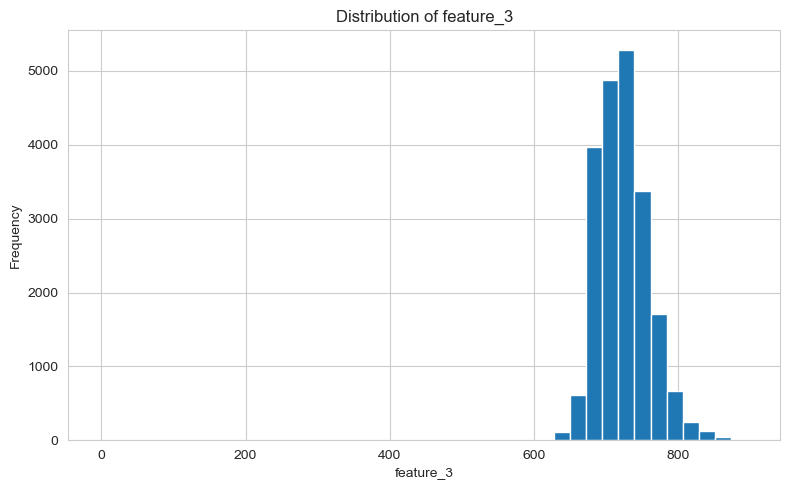

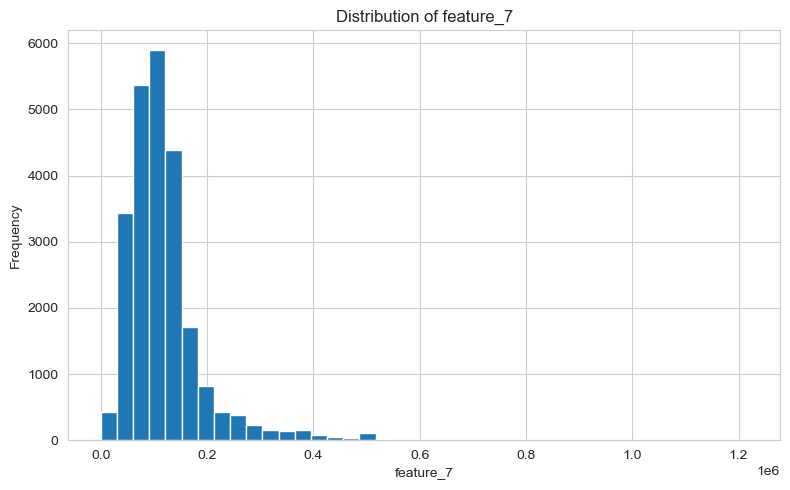

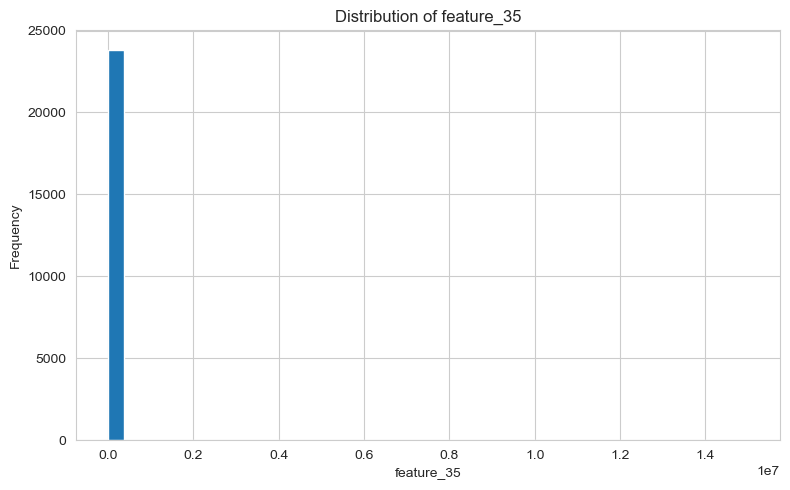

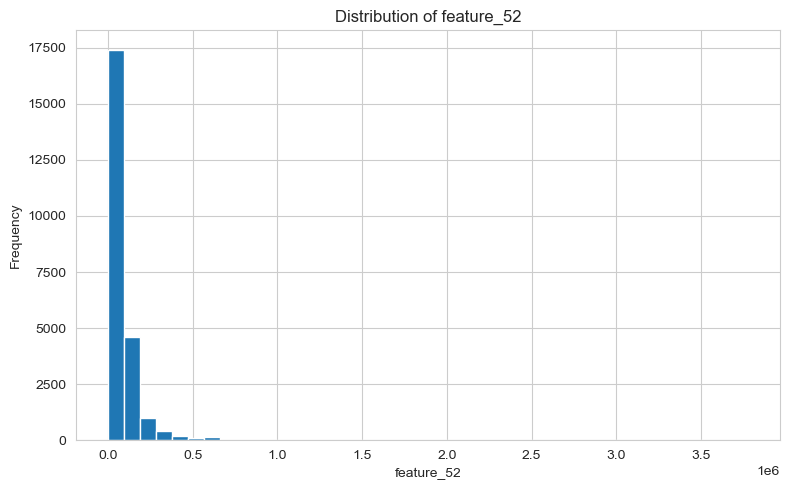

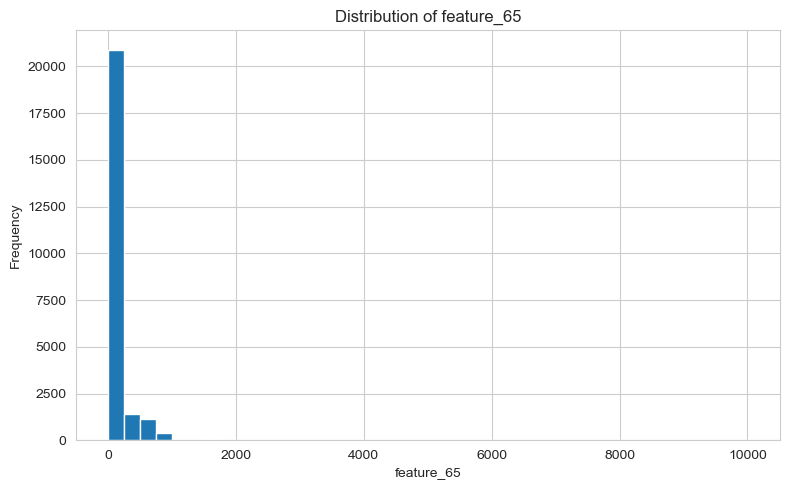

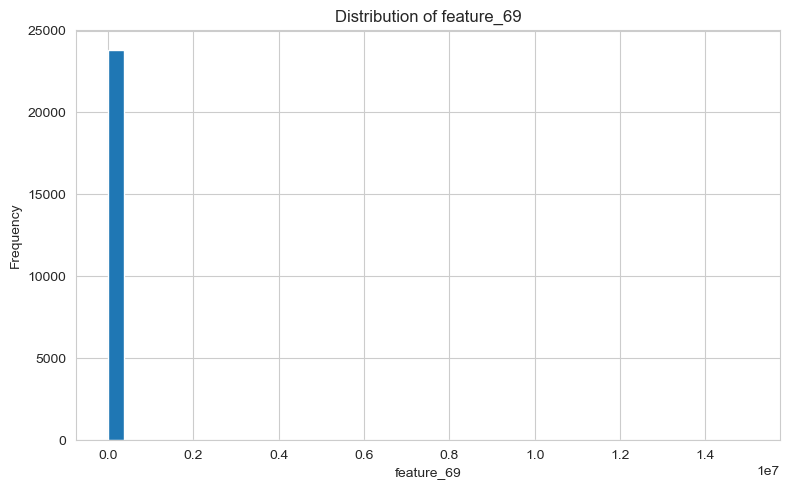

In [48]:
# ==========================================
# Visualize Numerical Feature Distributions
# ==========================================

import matplotlib.pyplot as plt

for col in numerical_candidates:
    
    plt.figure(figsize=(8, 5))
    
    plt.hist(
        numerical_data[col].dropna(),
        bins=40
    )
    
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

## Visual Analysis of Numerical Feature Outliers

Boxplots will be used to visually examine the spread and potential extreme values of the selected numerical features.

The boxplots complement the earlier IQR-based outlier analysis and help identify whether the detected extreme observations are isolated points or part of a broader distribution.

Potential outliers will not be removed automatically, as extreme financial values may represent genuine observations.

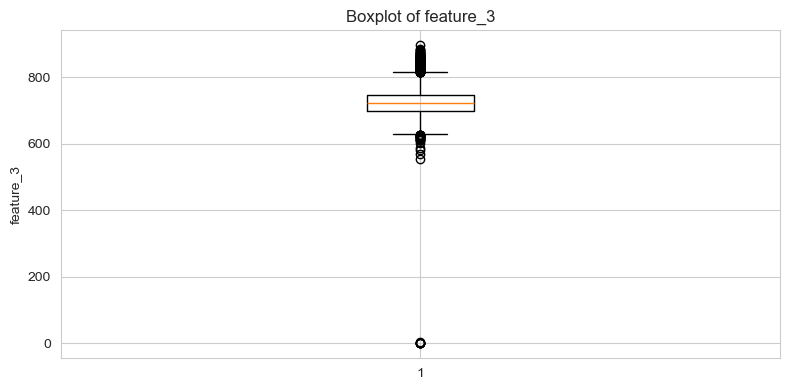

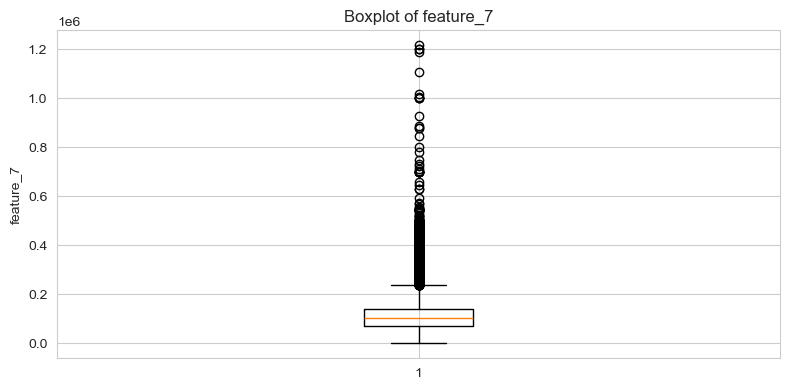

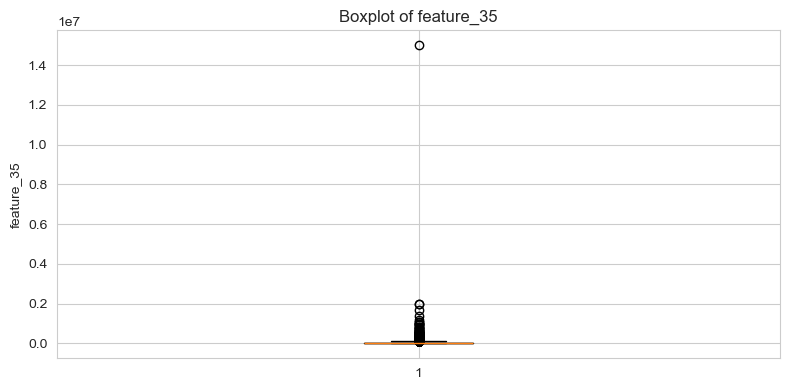

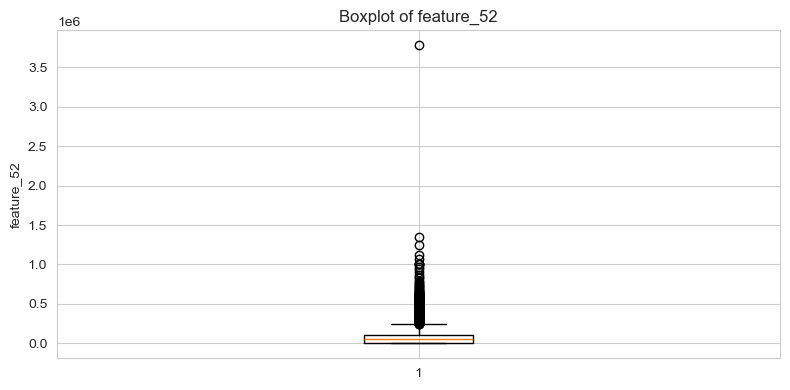

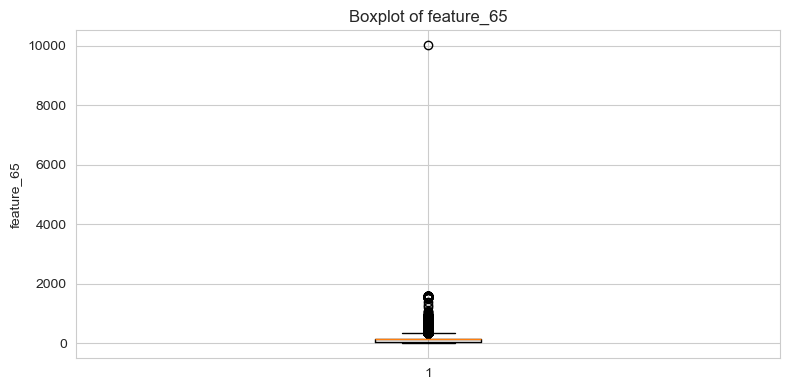

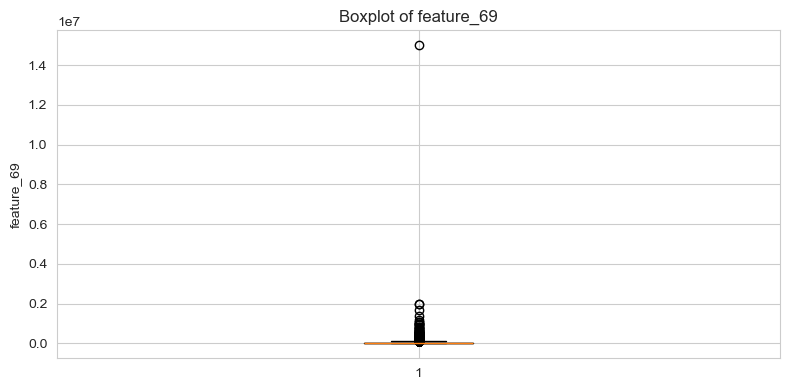

In [49]:
# ==========================================
# Visualize Numerical Feature Outliers
# ==========================================

import matplotlib.pyplot as plt

for col in numerical_candidates:
    
    plt.figure(figsize=(8, 4))
    
    plt.boxplot(
        numerical_data[col].dropna()
    )
    
    plt.title(f"Boxplot of {col}")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

## Numerical Distribution and Outlier Findings

The histogram and boxplot analysis supports the earlier statistical findings regarding skewness and extreme values.

- `feature_3` shows a left-skewed distribution.
- `feature_7`, `feature_35`, `feature_52`, `feature_65`, and `feature_69` show strong right-skewed behavior.
- The numerical features contain observations beyond the IQR-based bounds, confirming the presence of potential extreme values.
- `feature_35` and `feature_69` show the same distribution because they were previously identified as exact duplicate features.
- The amount-like features exhibit long-tailed distributions, which is common in financial data.
- Potential outliers will not be removed automatically because extreme values may represent genuine customer financial characteristics.

### Modeling / Preprocessing Implication

The observed skewness and extreme values will be considered when selecting preprocessing techniques. Transformations may be evaluated for heavily skewed numerical variables, while outlier treatment will be based on data characteristics and model performance rather than automatic deletion.

## Target Variable Distribution

The target variable `Bad_label` will be analyzed to understand the distribution of good and bad customer records.

The dataset contains two target classes:

- `0` — Good customer
- `1` — Bad customer

The class proportions and imbalance ratio will be calculated to determine the severity of class imbalance.

This analysis is important because class imbalance can affect model training and evaluation. Accuracy alone may therefore not be sufficient for assessing model performance.

In [50]:
# ==========================================
# Analyze Target Variable Distribution
# ==========================================

target_counts = cust_demographics["Bad_label"].value_counts().sort_index()

target_percentages = (
    cust_demographics["Bad_label"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

print("Bad_label counts:")
print(target_counts)

print("\nBad_label percentages:")
print(target_percentages.round(2))

good_count = target_counts.get("0", 0)
bad_count = target_counts.get("1", 0)

imbalance_ratio = good_count / bad_count

print("\nGood customers (0):", good_count)
print("Bad customers (1):", bad_count)
print("Good-to-Bad class ratio:", round(imbalance_ratio, 2))

Bad_label counts:
Bad_label
0    22892
1     1004
Name: count, dtype: int64

Bad_label percentages:
Bad_label
0    95.8
1     4.2
Name: proportion, dtype: float64

Good customers (0): 22892
Bad customers (1): 1004
Good-to-Bad class ratio: 22.8


## Observation

- The target variable contains 22,892 good customers (`Bad_label = 0`) and 1,004 bad customers (`Bad_label = 1`).
- Good customers represent **95.8%** of the dataset, while bad customers represent only **4.2%**.
- The resulting good-to-bad class ratio is approximately **22.8:1**.
- This confirms a substantial class imbalance, with the bad-credit class being the minority class.
- A model that focuses primarily on the majority class could achieve high overall accuracy while failing to identify a meaningful proportion of bad customers.
- Therefore, class imbalance must be explicitly considered during model development and evaluation.

### Modeling / Preprocessing Implication

Imbalance-handling techniques will be evaluated during model development. Model performance will not be judged using accuracy alone; metrics such as recall, precision, F1-score, ROC-AUC, and Gini will be considered to assess the model's ability to distinguish bad-credit customers.

## Visual Analysis of Target Distribution

The distribution of `Bad_label` will be visualized to clearly illustrate the imbalance between good and bad customer classes.

The visualization complements the numerical class-distribution analysis and provides an intuitive representation of the minority bad-credit class.

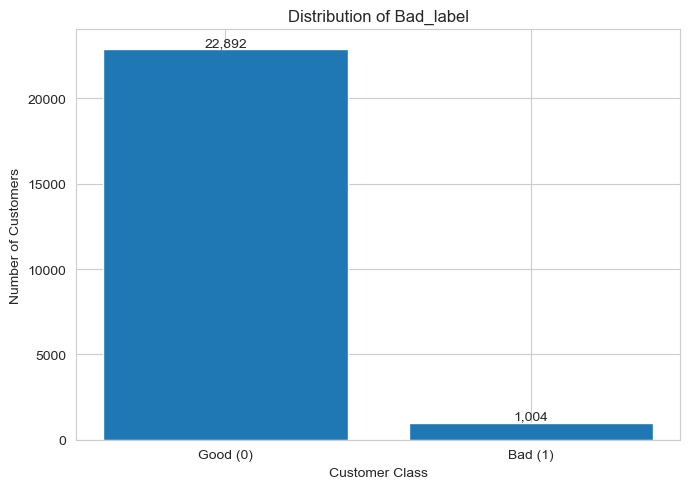

In [51]:
# ==========================================
# Visualize Target Class Distribution
# ==========================================

import matplotlib.pyplot as plt

target_counts = cust_demographics["Bad_label"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    ["Good (0)", "Bad (1)"],
    target_counts.values
)

plt.title("Distribution of Bad_label")
plt.xlabel("Customer Class")
plt.ylabel("Number of Customers")

for i, value in enumerate(target_counts.values):
    plt.text(
        i,
        value,
        f"{value:,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

## Observation

- The target distribution visualization confirms a strong imbalance between the two customer classes.
- The majority class, `Bad_label = 0`, contains **22,892 customers**, while the minority class, `Bad_label = 1`, contains **1,004 customers**.
- The visual difference between the two classes is substantial, consistent with the previously calculated **95.8% vs 4.2%** distribution.
- This imbalance reinforces the need to evaluate models using metrics that assess minority-class identification rather than relying only on overall accuracy.

### Modeling / Preprocessing Implication

Class imbalance will be explicitly considered during model development. Any resampling or class-weighting technique will be applied only to the training data to avoid data leakage, and model performance will be evaluated using appropriate classification and credit-risk metrics.

## Categorical Feature Distribution Analysis

The identified categorical features will be examined based on their category frequencies.

This analysis will help identify dominant categories, rare categories, and potential high-cardinality categorical variables.

The purpose at this stage is exploratory understanding only. No encoding, category grouping, or feature removal will be performed yet.

In [52]:
# ==========================================
# Analyze Categorical Feature Distributions
# ==========================================

categorical_candidates = [
    "feature_1",
    "feature_11",
    "feature_23",
    "feature_32",
    "feature_33",
    "feature_36",
    "feature_46",
    "feature_50",
    "feature_57",
    "feature_58",
    "feature_59",
    "feature_60",
    "feature_62",
    "feature_72",
    "feature_73",
    "feature_79"
]

for col in categorical_candidates:
    
    print(f"\n--- {col} ---")
    
    value_counts = (
        cust_demographics[col]
        .astype(str)
        .str.strip()
        .replace("", "BLANK")
        .value_counts(dropna=False)
    )
    
    percentage = (
        value_counts / len(cust_demographics) * 100
    ).round(2)
    
    category_summary = pd.DataFrame({
        "Count": value_counts,
        "Percentage": percentage
    })
    
    display(category_summary)


--- feature_1 ---


,Count,Percentage
feature_1,,
Platinum Maxima,9056,37.90
Platinum Deligh,8541,35.74
Titanium Deligh,5943,24.87
RBL Bank Fun+,218,0.91
Insignia,67,0.28
Golf Card,30,0.13
Platinum Cricke,26,0.11
BLANK,15,0.06



--- feature_11 ---


,Count,Percentage
feature_11,,
Y,22611,94.62
N,1270,5.31
BLANK,15,0.06



--- feature_23 ---


,Count,Percentage
feature_23,,
N,21528,90.09
Y,2353,9.85
BLANK,15,0.06


... (22 outputs left out)


--- feature_73 ---


,Count,Percentage
feature_73,,
BLANK,20951,87.68
Y,2126,8.90
N,819,3.43



--- feature_79 ---


,Count,Percentage
feature_79,,
N,23876,99.92
BLANK,15,0.06
Y,5,0.02


## Observation

- The categorical feature analysis shows substantial variation in category distributions across the selected categorical variables.
- `feature_1` is dominated by three major categories: `Platinum Maxima` (37.90%), `Platinum Deligh` (35.74%), and `Titanium Deligh` (24.87%), while the remaining categories are relatively rare.
- `feature_36` contains a substantial proportion of blank values (**23.78%**) in addition to multiple organization-type categories.
- `feature_46` is highly concentrated in `PAN Card`, representing **95.40%** of customers, with the remaining document types occurring at much lower frequencies.
- `feature_50` has a relatively balanced distribution between `Y` (52.58%) and `N` (47.36%), providing meaningful variation.
- `feature_57` and `feature_73` contain very high proportions of blank values, at **89.99%** and **87.68%** respectively.
- `feature_58`, `feature_60`, `feature_62`, and `feature_79` are highly dominated by a single category, indicating limited variation.
- The distributions of `feature_11` and `feature_59` are identical, consistent with the earlier exact-duplicate analysis.
- Several categorical features contain rare categories with very small numbers of observations. These categories will require careful handling during preprocessing to avoid unstable estimates or unnecessarily large feature spaces.
- Overall, the categorical features exhibit different levels of missingness, cardinality, and category imbalance.

### Modeling / Preprocessing Implication

Categorical variables will not be encoded using a single blanket rule. Missing categories, rare categories, and highly dominant categories will be considered individually. Appropriate encoding and category-grouping strategies will be evaluated during preprocessing, while exact duplicate features will be reduced before model training.

## Categorical Features vs Target

The relationship between selected categorical features and the target variable `Bad_label` will be examined using category-level customer counts and bad-credit rates.

This analysis helps identify categorical variables where customer risk appears to vary across categories.

Categories with very small sample sizes will be interpreted cautiously because their observed bad rates may be unstable. This is an exploratory analysis and will not be used alone to determine feature selection.

In [53]:
# ==========================================
# Analyze Categorical Features vs Target
# ==========================================

for col in categorical_candidates:

    temp = cust_demographics[[col, "Bad_label"]].copy()

    temp[col] = (
        temp[col]
        .astype(str)
        .str.strip()
        .replace("", "BLANK")
    )

    category_target_summary = (
        temp.groupby(col)["Bad_label"]
        .agg(
            Records="count",
            Bad_Rate=lambda x: (x == "1").mean() * 100
        )
        .sort_values("Records", ascending=False)
    )

    print(f"\n--- {col} ---")
    display(category_target_summary.round(2))


--- feature_1 ---


,Records,Bad_Rate
feature_1,,
Platinum Maxima,9056,5.02
Platinum Deligh,8541,3.81
Titanium Deligh,5943,3.50
RBL Bank Fun+,218,1.38
Insignia,67,5.97
Golf Card,30,23.33
Platinum Cricke,26,3.85
BLANK,15,6.67



--- feature_11 ---


,Records,Bad_Rate
feature_11,,
Y,22611,4.14
N,1270,5.20
BLANK,15,6.67



--- feature_23 ---


,Records,Bad_Rate
feature_23,,
N,21528,4.07
Y,2353,5.35
BLANK,15,6.67


... (22 outputs left out)


--- feature_73 ---


,Records,Bad_Rate
feature_73,,
BLANK,20951,4.26
Y,2126,3.43
N,819,4.76



--- feature_79 ---


,Records,Bad_Rate
feature_79,,
N,23876,4.20
BLANK,15,6.67
Y,5,0.00


## Observation

- The categorical feature analysis shows that the relationship between category membership and bad-credit rate varies across features.
- `feature_50` shows a noticeable difference in bad-credit rates: approximately **3.05%** for `Y` compared with **5.48%** for `N`, with substantial observations in both groups.
- `feature_60` shows a stronger difference, with a bad-credit rate of approximately **0.31%** for `Y` compared with **4.25%** for `N`. The `Y` category contains 318 customers, so this relationship warrants further evaluation.
- `feature_1` shows variation across card categories; however, some categories have very small sample sizes. For example, the `Golf Card` category has a 23.33% bad rate but contains only 30 customers, so this estimate should be interpreted cautiously.
- `feature_36` contains substantial missingness, but its major categories show relatively similar bad-credit rates.
- `feature_46` shows relatively small differences in bad-credit rates across document types, suggesting limited target separation based on this feature alone.
- `feature_62` and `feature_79` contain extremely small minority categories. Their observed 0% bad rates are therefore not sufficient evidence of a meaningful relationship with the target.
- The results demonstrate that category-level bad rates must be interpreted together with category sample sizes.
- `feature_11` and `feature_59` produce identical distributions and target relationships, consistent with their previously identified exact duplication.

### Modeling / Preprocessing Implication

Categorical features showing meaningful variation in bad-credit rates with sufficient sample sizes will be retained for further evaluation. Rare categories will require careful treatment or grouping during preprocessing. Target-rate differences alone will not be used to remove or retain a feature; model validation will ultimately determine predictive usefulness.

## Date-Like Feature Analysis

The identified date-like features will be examined to determine their date coverage and formatting consistency.

The features contain dates in different formats, including formats such as `DD-MMM-YY`, `MMM-YY`, and numeric date formats. Some fields may also contain invalid, blank, or placeholder values.

Before converting these features into datetime format, their parseability and valid-date proportions will be assessed. This prevents incorrect date conversion and loss of potentially useful information.

In [54]:
# ==========================================
# Analyze Date-Like Features
# ==========================================

date_candidates = [
    "feature_2",
    "feature_21",
    "feature_53",
    "feature_70",
    "feature_75"
]

date_analysis = []

for col in date_candidates:
    
    values = (
        cust_demographics[col]
        .astype(str)
        .str.strip()
    )
    
    non_blank_count = values.ne("").sum()
    
    parsed_dates = pd.to_datetime(
        values.replace("", pd.NA),
        errors="coerce"
    )
    
    valid_date_count = parsed_dates.notna().sum()
    
    date_analysis.append({
        "Feature": col,
        "Non_Blank_Count": non_blank_count,
        "Valid_Date_Count": valid_date_count,
        "Valid_Date_Percentage": (
            valid_date_count / non_blank_count * 100
            if non_blank_count > 0 else 0
        )
    })

date_analysis_df = pd.DataFrame(date_analysis)

display(
    date_analysis_df.round(2)
)

,Feature,Non_Blank_Count,Valid_Date_Count,Valid_Date_Percentage
0,feature_2,21060,21060,100.00
1,feature_21,23881,23881,100.00
2,feature_53,12286,12286,100.00
3,feature_70,23881,0,0.00
4,feature_75,23881,61,0.26


## Observation

- `feature_2`, `feature_21`, and `feature_53` have a **100% valid-date rate among their non-blank records**, indicating that they can be reliably interpreted as date-like variables.
- `feature_70` has **0% successfully parsed dates** using the standard datetime conversion. Earlier inspection showed inconsistent values such as month-year combinations and other irregular formats.
- `feature_75` has only **61 successfully parsed values out of 23,881 non-blank records (0.26%)**. The feature contains placeholder and inconsistent date formats, including values such as `0000-00-00`.
- Therefore, `feature_2`, `feature_21`, and `feature_53` are suitable candidates for controlled date transformation.
- `feature_70` and `feature_75` require separate investigation before any conversion or feature engineering is attempted.

### Modeling / Preprocessing Implication

`feature_2`, `feature_21`, and `feature_53` may be transformed into meaningful date-derived variables during preprocessing. `feature_70` and `feature_75` will not be blindly converted to datetime because their current formats and valid-date coverage are unsuitable for reliable direct conversion. Their usefulness will be evaluated before deciding whether to retain, transform, or exclude them.

## Investigate Irregular Date-Like Features

`feature_70` and `feature_75` could not be reliably interpreted as standard datetime variables during the initial date-parseability check.

Their unique values and frequencies will therefore be examined to determine whether they contain recoverable date information, placeholder values, or inconsistent formats.

No conversion or deletion will be performed during this investigation.

In [55]:
# ==========================================
# Investigate Irregular Date-Like Features
# ==========================================

irregular_date_features = ["feature_70", "feature_75"]

for col in irregular_date_features:
    
    print(f"\n{'=' * 50}")
    print(f"--- {col} ---")
    
    values = (
        cust_demographics[col]
        .astype(str)
        .str.strip()
        .replace("", "BLANK")
    )
    
    print("Unique values:", values.nunique())
    print("\nValue counts:")
    
    display(
        values.value_counts()
        .head(30)
        .to_frame("Count")
    )


--- feature_70 ---
Unique values: 134

Value counts:


,Count
feature_70,
0-0,18235
Nov-00,1976
Oct-00,363
May-00,355
Aug-00,245
Jun-00,200
Mar-00,175
Apr-00,175
Jul-00,171



--- feature_75 ---
Unique values: 63

Value counts:


,Count
feature_75,
0000-00-00,23820
BLANK,15
12-09-1983,1
7/25/84,1
6/23/58,1
12-08-1979,1
12-12-1982,1
10/28/78,1
2/23/78,1


## Observation

- `feature_70` contains 134 unique values, with `0-0` occurring in 18,235 records, representing approximately **76.31%** of the dataset.
- The remaining values include partial and inconsistently formatted date-like values such as `Nov-00`, `Oct-00`, `06-May`, and similar patterns.
- Because of the inconsistent formats and the dominance of the `0-0` placeholder, `feature_70` cannot be reliably converted into a standard datetime variable at this stage.
- `feature_75` contains `0000-00-00` in 23,820 records, representing approximately **99.68%** of the dataset.
- Only a very small number of records contain apparently valid dates in `feature_75`, and these dates use multiple formats.
- Therefore, `feature_75` provides extremely limited usable date information in its current form.
- These findings indicate that the two irregular date-like features require different treatment rather than blanket datetime conversion.

### Modeling / Preprocessing Implication

`feature_70` will be retained temporarily for further predictive evaluation rather than being blindly converted to datetime. Its dominant placeholder value and remaining patterns will be considered during feature treatment.

`feature_75` will be considered a strong candidate for exclusion because almost the entire column consists of a placeholder value. The final decision will be made during preprocessing after considering its relationship with the target and overall model usefulness.

## Feature Quality Summary

A consolidated feature-quality summary will be created using the findings from the data-understanding and exploratory analysis stages.

The summary will classify features according to their observed characteristics, including numerical, categorical, date-like, identifier-like, highly blank, duplicate, and irregular fields.

This summary will be used as a reference during data preparation and feature selection. No features will be removed automatically at this stage.

In [56]:
# ==========================================
# Feature Quality Summary
# ==========================================

feature_quality = []

# Exact duplicate pairs identified earlier
duplicate_features = {
    "feature_11": "feature_59",
    "feature_59": "feature_11",
    "feature_34": "feature_68",
    "feature_68": "feature_34",
    "feature_35": "feature_69",
    "feature_69": "feature_35"
}

# Features identified as date-like
date_like_features = [
    "feature_2",
    "feature_21",
    "feature_53",
    "feature_70",
    "feature_75"
]

# Features identified as categorical
categorical_features = categorical_candidates

# Numerical candidates identified earlier
numerical_features = numerical_candidates

# Identifier / reference-like features
identifier_like_features = [
    "feature_20",
    "feature_22",
    "feature_47",
    "feature_77"
]

# Location / postal-code-like features
location_like_features = [
    "feature_28",
    "feature_29",
    "feature_43",
    "feature_44",
    "feature_66"
]

for col in feature_columns:

    blank_count = (
        cust_demographics[col]
        .astype(str)
        .str.strip()
        .eq("")
        .sum()
    )

    blank_percentage = (
        blank_count / len(cust_demographics) * 100
    )

    if col in duplicate_features:
        feature_type = "Exact Duplicate"
    elif col in date_like_features:
        feature_type = "Date-like"
    elif col in numerical_features:
        feature_type = "Numerical Candidate"
    elif col in categorical_features:
        feature_type = "Categorical"
    elif col in identifier_like_features:
        feature_type = "Identifier-like"
    elif col in location_like_features:
        feature_type = "Location / Postal-like"
    else:
        feature_type = "Other / Requires Review"

    feature_quality.append({
        "Feature": col,
        "Feature_Type": feature_type,
        "Unique_Count": cust_demographics[col].nunique(
            dropna=False
        ),
        "Blank_Count": blank_count,
        "Blank_Percentage": blank_percentage
    })

feature_quality_df = pd.DataFrame(feature_quality)

display(
    feature_quality_df
    .sort_values(
        ["Feature_Type", "Blank_Percentage"],
        ascending=[True, False]
    )
    .round(2)
)

,Feature,Feature_Type,Unique_Count,Blank_Count,Blank_Percentage
56,feature_57,Categorical,3,21503,89.99
72,feature_73,Categorical,3,20951,87.68
35,feature_36,Categorical,10,5682,23.78
45,feature_46,Categorical,6,94,0.39
0,feature_1,Categorical,8,15,0.06
...,...,...,...,...,...
63,feature_64,Other / Requires Review,28,15,0.06
66,feature_67,Other / Requires Review,3,15,0.06
70,feature_71,Other / Requires Review,14,15,0.06
75,feature_76,Other / Requires Review,6,15,0.06


## Observation

- The consolidated feature-quality summary provides an overall view of the 79 anonymized demographic features based on their observed characteristics.
- The features contain a mixture of categorical, numerical candidate, date-like, identifier-like, location/postal-like, duplicate, and other features requiring further review.
- Several features have extremely high blank percentages and will require careful consideration during preprocessing.
- The exact duplicate feature pairs identified earlier remain flagged for later feature reduction.
- Date-like, identifier-like, postal-code-like, and categorical features will not be treated as ordinary continuous numerical variables.
- Some numeric-coded features remain classified as `Other / Requires Review` because their numerical appearance alone is insufficient to establish that they represent continuous measurements.
- The feature-quality summary will serve as a reference when making preprocessing and feature-selection decisions.
- No feature has been permanently removed at this stage.

### Modeling / Preprocessing Implication

The feature-quality findings will guide feature-specific preprocessing. Missing values, duplicate features, categorical variables, date-like fields, identifier-like fields, and highly sparse features will be handled according to their observed characteristics rather than using a single preprocessing rule for the entire dataset.

## Phase 3 — Data Preparation

### Create Working Copies

Clean working copies of the customer demographics and account-level datasets will be created before preprocessing.

The original datasets will be preserved as references, while all subsequent cleaning, transformation, and feature-engineering operations will be performed on the working copies.

This approach allows the original imported data to remain unchanged and provides a reproducible starting point for the preprocessing pipeline.

In [57]:
# ==========================================
# Create Working Copies for Preprocessing
# ==========================================

cust_demo_clean = cust_demographics.copy()
cust_account_clean = cust_account.copy()

print("Working copies created successfully.")

print("\nCustomer demographics shape:")
print(cust_demo_clean.shape)

print("\nCustomer account shape:")
print(cust_account_clean.shape)

Working copies created successfully.

Customer demographics shape:
(23896, 83)

Customer account shape:
(186329, 21)


## Standardize Blank Values as Missing Values

During data understanding, many features were found to contain blank strings (`""`) rather than standard missing values.

To make missing-value handling consistent, blank strings and whitespace-only strings will be converted to `NaN` in the working copies.

This operation will not alter genuinely observed values such as zero. Zero is a valid observed value in fields where it represents an actual measurement and will therefore be preserved.

The original datasets remain unchanged.

In [58]:
# ==========================================
# Standardize Blank Values
# ==========================================

import numpy as np

def standardize_blank_values(df):
    df = df.copy()
    
    for col in df.columns:
        if df[col].dtype == "object":
            df[col] = (
                df[col]
                .replace(r"^\s*$", np.nan, regex=True)
            )
    
    return df


cust_demo_clean = standardize_blank_values(cust_demo_clean)
cust_account_clean = standardize_blank_values(cust_account_clean)

print("Blank values standardized successfully.")

Blank values standardized successfully.


In [59]:
# ==========================================
# Verify Standardized Missing Values
# ==========================================

print("Customer demographics missing values:")
print(cust_demo_clean.isna().sum().sum())

print("\nCustomer account missing values:")
print(cust_account_clean.isna().sum().sum())

Customer demographics missing values:
333644

Customer account missing values:
1154903


## Missing-Value Summary After Standardization

After converting blank strings and whitespace-only values to `NaN`, the total amount of missing data in each working dataset will be quantified.

A feature-level missing-value summary will be created to identify variables with low, moderate, and extremely high missingness.

This summary will guide feature-specific missing-value treatment during preprocessing. No missing values will be imputed or removed at this stage.

In [60]:
# ==========================================
# Missing-Value Summary
# ==========================================

demo_missing_summary = pd.DataFrame({
    "Missing_Count": cust_demo_clean.isna().sum(),
    "Missing_Percentage": (
        cust_demo_clean.isna().mean() * 100
    )
})

account_missing_summary = pd.DataFrame({
    "Missing_Count": cust_account_clean.isna().sum(),
    "Missing_Percentage": (
        cust_account_clean.isna().mean() * 100
    )
})

print("Customer Demographics - Missing Values")
display(
    demo_missing_summary
    .sort_values("Missing_Percentage", ascending=False)
    .round(2)
)

print("\nCustomer Account - Missing Values")
display(
    account_missing_summary
    .sort_values("Missing_Percentage", ascending=False)
    .round(2)
)

Customer Demographics - Missing Values


,Missing_Count,Missing_Percentage
feature_61,23887,99.96
feature_74,23879,99.93
feature_18,23878,99.92
feature_10,23845,99.79
feature_49,23792,99.56
...,...,...
feature_47,0,0.00
customer_no,0,0.00
feature_22,0,0.00
feature_20,0,0.00



Customer Account - Missing Values


,Missing_Count,Missing_Percentage
amt_past_due,185453,99.53
rateofinterest,161496,86.67
cashlimit,151047,81.06
actualpaymentamount,145276,77.97
creditlimit,137477,73.78
paymentfrequency,122436,65.71
closed_dt,109075,58.54
paymenthistory2,107824,57.87
last_paymt_dt,25487,13.68
high_credit_amt,8875,4.76


## Missing-Value Findings

After standardizing blank strings to `NaN`, substantial missingness was observed in both customer-level and account-level datasets.

### Customer Demographics

Several demographic features have extremely high missing percentages, including `feature_61`, `feature_74`, `feature_18`, `feature_10`, and `feature_49`, each with more than 99% missing values.

### Customer Account

The account-level dataset contains substantial missingness in fields such as `amt_past_due`, `rateofinterest`, `cashlimit`, `actualpaymentamount`, `creditlimit`, `paymentfrequency`, `closed_dt`, and `paymenthistory2`.

### Interpretation

High missingness does not automatically indicate that a feature should be removed. In credit-risk data, the absence of a value may itself contain information about the account or customer.

Therefore, missing-value treatment will be performed on a feature-by-feature basis after considering:

- Missing percentage
- Data type
- Business meaning inferred from the available data
- Relationship with the target
- Whether missingness represents an applicable/not-applicable condition
- Potential information loss from removing the feature

No blanket imputation strategy will be applied to the complete dataset.

## Account-Level Feature Classification

The customer account dataset contains 21 columns and 186,329 account records.

Before performing missing-value treatment, the account-level variables will be classified according to their observed data characteristics.

The analysis will distinguish between:

- Customer identifiers
- Date-like fields
- Numerical/financial fields
- Categorical fields
- Payment-history fields
- Indicator fields

This classification will determine the appropriate preprocessing strategy for each variable.

No imputation, deletion, or transformation will be performed during this step.

In [61]:
# ==========================================
# Inspect Account-Level Features
# ==========================================

print("Account-level columns:")
print(cust_account_clean.columns.tolist())

print("\nNumber of columns:", len(cust_account_clean.columns))

print("\nData types:")
print(cust_account_clean.dtypes)

print("\nUnique value counts:")
account_cardinality = pd.DataFrame({
    "Feature": cust_account_clean.columns,
    "Unique_Count": [
        cust_account_clean[col].nunique(dropna=False)
        for col in cust_account_clean.columns
    ],
    "Missing_Count": cust_account_clean.isna().sum().values,
    "Missing_Percentage": (
        cust_account_clean.isna().mean().values * 100
    )
})

display(
    account_cardinality
    .sort_values("Unique_Count")
    .round(2)
)

Account-level columns:
['dt_opened', 'customer_no', 'upload_dt', 'acct_type', 'owner_indic', 'opened_dt', 'last_paymt_dt', 'closed_dt', 'reporting_dt', 'high_credit_amt', 'cur_balance_amt', 'amt_past_due', 'paymenthistory1', 'paymenthistory2', 'paymt_str_dt', 'paymt_end_dt', 'creditlimit', 'cashlimit', 'rateofinterest', 'paymentfrequency', 'actualpaymentamount']

Number of columns: 21

Data types:
dt_opened              object
customer_no            object
upload_dt              object
acct_type              object
owner_indic            object
opened_dt              object
last_paymt_dt          object
closed_dt              object
reporting_dt           object
high_credit_amt        object
cur_balance_amt        object
amt_past_due           object
paymenthistory1        object
paymenthistory2        object
paymt_str_dt           object
paymt_end_dt           object
creditlimit            object
cashlimit              object
rateofinterest         object
paymentfrequency       object

,Feature,Unique_Count,Missing_Count,Missing_Percentage
19,paymentfrequency,3,122436,65.71
4,owner_indic,4,0,0.00
3,acct_type,31,0,0.00
2,upload_dt,75,0,0.00
0,dt_opened,197,0,0.00
14,paymt_str_dt,234,1,0.00
15,paymt_end_dt,235,1,0.00
11,amt_past_due,630,185453,99.53
16,creditlimit,1380,137477,73.78
17,cashlimit,1456,151047,81.06


## Inspect Account Feature Values

The account-level variables are currently stored as object data types, even though several fields are expected to represent numerical, date, categorical, or payment-related information.

Representative values and frequency distributions will be inspected to determine the actual semantic structure of these variables.

This step will help distinguish valid zero values, missing values, categorical codes, dates, financial amounts, and other special values before conversion or aggregation.

In [62]:
# ==========================================
# Inspect Account Feature Values
# ==========================================

for col in cust_account_clean.columns:
    
    print(f"\n{'=' * 60}")
    print(f"--- {col} ---")
    
    print("Data type:", cust_account_clean[col].dtype)
    print("Unique values:", cust_account_clean[col].nunique(dropna=False))
    
    print("\nSample values:")
    print(
        cust_account_clean[col]
        .dropna()
        .astype(str)
        .drop_duplicates()
        .head(10)
        .tolist()
    )
    
    print("\nTop value counts:")
    display(
        cust_account_clean[col]
        .value_counts(dropna=False)
        .head(10)
        .to_frame("Count")
    )


--- dt_opened ---
Data type: object
Unique values: 197

Sample values:
['10-Nov-15', '20-Jul-15', '02-Nov-15', '16-Nov-15', '27-Aug-15', '05-May-15', '29-Dec-15', '18-Dec-15', '07-May-15', '06-Nov-15']

Top value counts:


,Count
dt_opened,
16-Nov-15,4643
21-Dec-15,2395
18-Aug-15,2158
13-Oct-15,2062
26-Oct-15,2004
24-Nov-15,1966
10-Jul-15,1883
30-Sep-15,1876
15-Oct-15,1809



--- customer_no ---
Data type: object
Unique values: 23896

Sample values:
['12265', '15606', '11742', '12379', '17744', '370', '14707', '5802', '6218', '20797']

Top value counts:


,Count
customer_no,
8516,120
10076,112
6391,88
8872,77
8814,76
8869,72
11922,71
8092,70
18936,69



--- upload_dt ---
Data type: object
Unique values: 75

Sample values:
['20-Oct-15', '09-Jul-15', '13-Oct-15', '30-Jul-15', '10-Aug-15', '21-Apr-15', '10-Dec-15', '12-Nov-15', '28-Apr-15', '26-Oct-15']

Top value counts:


,Count
upload_dt,
21-Apr-15,5128
23-Oct-15,3591
16-Jul-15,3512
28-Sep-15,3507
20-Oct-15,3486
20-Aug-15,3357
17-Sep-15,3297
26-Oct-15,3275
27-Aug-15,3270


... (32 outputs left out)


--- paymentfrequency ---
Data type: object
Unique values: 3

Sample values:
['3', '1']

Top value counts:


,Count
paymentfrequency,
NaN,122436
3,63772
1,121



--- actualpaymentamount ---
Data type: object
Unique values: 18300

Sample values:
['5603', '6516', '20000', '49000', '23922', '8720', '40000', '1600', '810', '1000']

Top value counts:


,Count
actualpaymentamount,
NaN,145276
5000,507
10000,448
2000,362
3000,312
1000,295
4000,236
20000,212
6000,211


## Account-Level Feature Classification Findings

Inspection of the account-level variables shows that all 21 columns are stored as object data types, but they represent different types of information.

### Date-like Features

The following fields contain date-formatted values:

`dt_opened`, `upload_dt`, `opened_dt`, `last_paymt_dt`, `closed_dt`, `reporting_dt`, `paymt_str_dt`, and `paymt_end_dt`.

These will be converted to datetime format using controlled parsing during preprocessing.

### Identifier

`customer_no` is the customer identifier and will be retained as the key for customer-level aggregation and merging, but it will not be used as a predictive feature.

### Categorical Features

`acct_type`, `owner_indic`, and `paymentfrequency` contain categorical codes rather than continuous numerical measurements.

These variables will be treated as categorical features during preprocessing.

### Financial / Numerical Features

The following fields contain numerical financial information stored as strings:

`high_credit_amt`, `cur_balance_amt`, `amt_past_due`, `creditlimit`, `cashlimit`, `rateofinterest`, and `actualpaymentamount`.

These fields will be converted to appropriate numerical representations after their missing-value and special-value behavior has been considered.

### Payment History Features

`paymenthistory1` and `paymenthistory2` contain structured text sequences involving values such as `STD`, `XXX`, and numeric payment-status information.

These fields will not be blindly converted to numerical values. Their structure will be investigated separately before feature engineering.

### Preprocessing Implication

The account-level dataset requires feature-specific preprocessing rather than a single conversion rule. Date, categorical, numerical, identifier, and payment-history fields will each follow an appropriate treatment strategy.

In [63]:
# ==========================================
# Account Feature Classification
# ==========================================

account_date_features = [
    "dt_opened",
    "upload_dt",
    "opened_dt",
    "last_paymt_dt",
    "closed_dt",
    "reporting_dt",
    "paymt_str_dt",
    "paymt_end_dt"
]

account_categorical_features = [
    "acct_type",
    "owner_indic",
    "paymentfrequency"
]

account_numerical_features = [
    "high_credit_amt",
    "cur_balance_amt",
    "amt_past_due",
    "creditlimit",
    "cashlimit",
    "rateofinterest",
    "actualpaymentamount"
]

account_identifier_features = [
    "customer_no"
]

account_payment_history_features = [
    "paymenthistory1",
    "paymenthistory2"
]

print("Date features:", account_date_features)
print("\nCategorical features:", account_categorical_features)
print("\nNumerical features:", account_numerical_features)
print("\nIdentifier features:", account_identifier_features)
print("\nPayment-history features:", account_payment_history_features)

Date features: ['dt_opened', 'upload_dt', 'opened_dt', 'last_paymt_dt', 'closed_dt', 'reporting_dt', 'paymt_str_dt', 'paymt_end_dt']

Categorical features: ['acct_type', 'owner_indic', 'paymentfrequency']

Numerical features: ['high_credit_amt', 'cur_balance_amt', 'amt_past_due', 'creditlimit', 'cashlimit', 'rateofinterest', 'actualpaymentamount']

Identifier features: ['customer_no']

Payment-history features: ['paymenthistory1', 'paymenthistory2']


## Convert Financial Features to Numeric

The financial account-level features are currently stored as object/string values even though they represent numerical measurements.

The following features will be evaluated for numeric conversion:

`high_credit_amt`, `cur_balance_amt`, `amt_past_due`, `creditlimit`, `cashlimit`, `rateofinterest`, and `actualpaymentamount`.

Conversion will use coercion only for values that cannot be interpreted as numeric. The number of conversion failures will be measured before permanently applying the transformation.

Missing values will remain missing and will not be imputed during this step.

In [64]:
# ==========================================
# Test Financial Features for Numeric Conversion
# ==========================================

numeric_conversion_summary = []

for col in account_numerical_features:
    
    original = cust_account_clean[col]
    
    converted = pd.to_numeric(
        original,
        errors="coerce"
    )
    
    # Values that were non-missing originally
    # but became NaN after conversion
    conversion_failures = (
        original.notna() & converted.isna()
    ).sum()
    
    numeric_conversion_summary.append({
        "Feature": col,
        "Original_Non_Missing": original.notna().sum(),
        "Conversion_Failures": conversion_failures,
        "Conversion_Failure_Percentage": (
            conversion_failures / original.notna().sum() * 100
            if original.notna().sum() > 0 else 0
        )
    })

numeric_conversion_summary_df = pd.DataFrame(
    numeric_conversion_summary
)

display(
    numeric_conversion_summary_df.round(2)
)

,Feature,Original_Non_Missing,Conversion_Failures,Conversion_Failure_Percentage
0,high_credit_amt,177454,0,0.00
1,cur_balance_amt,186329,0,0.00
2,amt_past_due,876,0,0.00
3,creditlimit,48852,0,0.00
4,cashlimit,35282,0,0.00
5,rateofinterest,24833,10,0.04
6,actualpaymentamount,41053,0,0.00


## Investigate Non-Numeric Financial Values

The numeric conversion test identified 10 non-missing values in `rateofinterest` that could not be converted to numeric values.

These values will be inspected before conversion to determine whether they are data-entry errors, special codes, or meaningful observations.

No values will be removed or modified during this investigation.

In [65]:
# ==========================================
# Inspect Non-Numeric Rate of Interest Values
# ==========================================

rate_original = cust_account_clean["rateofinterest"]

rate_converted = pd.to_numeric(
    rate_original,
    errors="coerce"
)

non_numeric_rate = rate_original[
    rate_original.notna() & rate_converted.isna()
]

print("Non-numeric rateofinterest values:")
print(non_numeric_rate.value_counts())

print("\nNumber of non-numeric values:", len(non_numeric_rate))

Non-numeric rateofinterest values:
rateofinterest
"9    5
"7    3
"8    2
Name: count, dtype: int64

Number of non-numeric values: 10


## Clean and Convert Financial Features

The numeric conversion check identified 10 malformed values in `rateofinterest`. The values contain an unnecessary leading double quote, such as `"9`, `"7`, and `"8`.

These values are interpreted as numeric interest-rate values with a formatting artifact rather than as missing or categorical values.

The leading double quote will be removed before numeric conversion.

All identified financial features will then be converted from object/string representation to numeric data types. Existing `NaN` values will remain unchanged and will be handled separately during missing-value treatment.

In [66]:
# ==========================================
# Clean and Convert Financial Features
# ==========================================

# Remove the formatting artifact from rateofinterest
cust_account_clean["rateofinterest"] = (
    cust_account_clean["rateofinterest"]
    .astype("string")
    .str.replace('"', '', regex=False)
)

# Convert all financial features to numeric
for col in account_numerical_features:
    cust_account_clean[col] = pd.to_numeric(
        cust_account_clean[col],
        errors="coerce"
    )

print("Financial features converted successfully.")

print("\nData types after conversion:")
print(cust_account_clean[account_numerical_features].dtypes)

Financial features converted successfully.

Data types after conversion:
high_credit_amt        float64
cur_balance_amt          int64
amt_past_due           float64
creditlimit            float64
cashlimit              float64
rateofinterest         Float64
actualpaymentamount    float64
dtype: object


In [67]:
# ==========================================
# Verify Financial Feature Conversion
# ==========================================

verification = pd.DataFrame({
    "Feature": account_numerical_features,
    "Data_Type": [
        str(cust_account_clean[col].dtype)
        for col in account_numerical_features
    ],
    "Missing_Count": [
        cust_account_clean[col].isna().sum()
        for col in account_numerical_features
    ]
})

display(verification)

,Feature,Data_Type,Missing_Count
0,high_credit_amt,float64,8875
1,cur_balance_amt,int64,0
2,amt_past_due,float64,185453
3,creditlimit,float64,137477
4,cashlimit,float64,151047
5,rateofinterest,Float64,161496
6,actualpaymentamount,float64,145276


## Convert Account Date Features

The account dataset contains eight date-related features currently stored as object/string values.

These fields contain dates in formats such as `16-Nov-15` and will be converted to pandas datetime representation.

Conversion will be performed using controlled parsing. Existing missing values will remain missing.

No date-derived features will be created at this stage; feature engineering will be performed after the basic data-type conversion and data-quality checks are complete.

In [68]:
# ==========================================
# Convert Account Date Features
# ==========================================

date_conversion_summary = []

for col in account_date_features:
    
    original_non_missing = cust_account_clean[col].notna().sum()
    
    cust_account_clean[col] = pd.to_datetime(
        cust_account_clean[col],
        errors="coerce",
        dayfirst=True
    )
    
    conversion_failures = (
        cust_account_clean[col].isna().sum()
        - (len(cust_account_clean) - original_non_missing)
    )
    
    date_conversion_summary.append({
        "Feature": col,
        "Original_Non_Missing": original_non_missing,
        "Missing_After_Conversion": cust_account_clean[col].isna().sum(),
        "Conversion_Failures": max(conversion_failures, 0)
    })

date_conversion_summary_df = pd.DataFrame(
    date_conversion_summary
)

display(date_conversion_summary_df)

,Feature,Original_Non_Missing,Missing_After_Conversion,Conversion_Failures
0,dt_opened,186329,0,0
1,upload_dt,186329,0,0
2,opened_dt,185874,455,0
3,last_paymt_dt,160842,25487,0
4,closed_dt,77254,109075,0
5,reporting_dt,186329,0,0
6,paymt_str_dt,186328,1,0
7,paymt_end_dt,186328,1,0


## Convert Account Date Features

The account dataset contains eight date-related features currently stored as object/string values.

These fields contain dates in formats such as `16-Nov-15` and will be converted to pandas datetime representation.

Conversion will be performed using controlled parsing. Existing missing values will remain missing.

No date-derived features will be created at this stage; feature engineering will be performed after the basic data-type conversion and data-quality checks are complete.

In [69]:
# ==========================================
# Convert Account Date Features
# ==========================================

date_conversion_summary = []

for col in account_date_features:
    
    original_non_missing = cust_account_clean[col].notna().sum()
    
    cust_account_clean[col] = pd.to_datetime(
        cust_account_clean[col],
        errors="coerce",
        dayfirst=True
    )
    
    conversion_failures = (
        cust_account_clean[col].isna().sum()
        - (len(cust_account_clean) - original_non_missing)
    )
    
    date_conversion_summary.append({
        "Feature": col,
        "Original_Non_Missing": original_non_missing,
        "Missing_After_Conversion": cust_account_clean[col].isna().sum(),
        "Conversion_Failures": max(conversion_failures, 0)
    })

date_conversion_summary_df = pd.DataFrame(
    date_conversion_summary
)

display(date_conversion_summary_df)

,Feature,Original_Non_Missing,Missing_After_Conversion,Conversion_Failures
0,dt_opened,186329,0,0
1,upload_dt,186329,0,0
2,opened_dt,185874,455,0
3,last_paymt_dt,160842,25487,0
4,closed_dt,77254,109075,0
5,reporting_dt,186329,0,0
6,paymt_str_dt,186328,1,0
7,paymt_end_dt,186328,1,0


In [70]:
# ==========================================
# Verify Date Data Types
# ==========================================

print(
    cust_account_clean[account_date_features].dtypes
)

dt_opened        datetime64[ns]
upload_dt        datetime64[ns]
opened_dt        datetime64[ns]
last_paymt_dt    datetime64[ns]
closed_dt        datetime64[ns]
reporting_dt     datetime64[ns]
paymt_str_dt     datetime64[ns]
paymt_end_dt     datetime64[ns]
dtype: object


## Convert Account Categorical Features

The account-level categorical variables are currently stored as object/string values.

The identified categorical features are:

- `acct_type`
- `owner_indic`
- `paymentfrequency`

These fields contain categorical codes rather than continuous measurements. They will therefore be converted to pandas categorical data types while preserving missing values.

One-hot encoding or other model-specific encoding will be performed later as part of the final modeling pipeline, after customer-level feature engineering.

In [71]:
# ==========================================
# Convert Account Categorical Features
# ==========================================

for col in account_categorical_features:
    cust_account_clean[col] = cust_account_clean[col].astype("category")

print("Categorical features converted successfully.")

print("\nData types:")
print(cust_account_clean[account_categorical_features].dtypes)

Categorical features converted successfully.

Data types:
acct_type           category
owner_indic         category
paymentfrequency    category
dtype: object


In [72]:
# ==========================================
# Verify Categorical Features
# ==========================================

categorical_summary = []

for col in account_categorical_features:
    
    categorical_summary.append({
        "Feature": col,
        "Data_Type": str(cust_account_clean[col].dtype),
        "Unique_Non_Missing": cust_account_clean[col].nunique(),
        "Missing_Count": cust_account_clean[col].isna().sum(),
        "Categories": list(cust_account_clean[col].cat.categories)
    })

categorical_summary_df = pd.DataFrame(categorical_summary)

display(categorical_summary_df)

,Feature,Data_Type,Unique_Non_Missing,Missing_Count,Categories
0,acct_type,category,31,0,"[0, 1, 10, 11, 12, 13, 14, 15, 16, 17, 2, 3, 3..."
1,owner_indic,category,4,0,"[1, 2, 3, 4]"
2,paymentfrequency,category,2,122436,"[1, 3]"


## Investigate Payment History Structure

The payment-history fields contain structured sequences rather than conventional categorical values.

`paymenthistory1` and `paymenthistory2` contain combinations of numeric payment-status information and special markers such as `STD` and `XXX`.

Because these sequences may contain information about repayment behavior, they will not be directly encoded as categorical variables.

Their length, missingness, character patterns, and common markers will first be investigated. Suitable aggregate behavioral features will then be engineered from the sequences.

In [73]:
# ==========================================
# Payment History Structural Analysis
# ==========================================

for col in account_payment_history_features:
    
    print(f"\n{'=' * 60}")
    print(f"--- {col} ---")
    
    series = cust_account_clean[col].dropna().astype(str)
    
    print("Non-missing records:", len(series))
    
    # Sequence length
    lengths = series.str.len()
    
    print("Minimum length:", lengths.min())
    print("Maximum length:", lengths.max())
    print("Median length:", lengths.median())
    
    print("\nLength distribution:")
    display(
        lengths.value_counts()
        .sort_index()
        .head(20)
        .to_frame("Count")
    )
    
    print("\nContains STD:", series.str.contains("STD", regex=False).sum())
    print("Contains XXX:", series.str.contains("XXX", regex=False).sum())
    
    print("\nSample sequences:")
    display(series.head(10).to_frame(col))


--- paymenthistory1 ---
Non-missing records: 186329
Minimum length: 9
Maximum length: 60
Median length: 48.0

Length distribution:


,Count
paymenthistory1,
9,21410
12,6674
15,6292
18,5834
21,5022
24,5474
27,5299
30,5620
33,6702



Contains STD: 19374
Contains XXX: 55098

Sample sequences:


,paymenthistory1
0,"""""""STDSTDSTDXXXXXXXXXXXXXXXSTDXXXXXXXXXXXXXXXS..."
1,"""""""0000000000000000000000000000000000000000000..."
2,"""""""0000000000000000000000000000000000000000000..."
3,"""""""1200900600600600300000000000000000000000000..."
4,"""""""000000000000000"""""""
5,"""""""000000000000000"""""""
6,"""""""000000000000000000"""""""
7,"""""""000000000000000000000000"""""""
8,"""""""0000000000000000000000000000000000000000000..."
9,"""""""000000000XXX000000000000030XXX0000000000000..."



--- paymenthistory2 ---
Non-missing records: 78505
Minimum length: 9
Maximum length: 60
Median length: 60.0

Length distribution:


,Count
paymenthistory2,
9,3039
12,2609
15,2431
18,2432
21,2374
24,2538
27,3030
30,2496
33,2100



Contains STD: 6579
Contains XXX: 26916

Sample sequences:


,paymenthistory2
1,"""""""000000000000000000000000000XXX0000000000000..."
2,"""""""0000000000000000000000000000000000000000000..."
8,"""""""000000000000000000000000000000000000"""""""
9,"""""""030000000000XXX000000000000000000000000XXX0..."
10,"""""""0000000000000000000000000000000000000000000..."
11,"""""""553523492464433402372XXX3112802492191881581..."
16,"""""""XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXSTDSTDSTDSTDS..."
21,"""""""XXXSTD"""""""
22,"""""""XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX..."
23,"""""""XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX..."


## Inspect Payment-History Status Codes

The payment-history fields contain structured sequences whose lengths are multiples of three, indicating that the strings can be divided into three-character status blocks.

Before creating behavioral features, the distinct three-character codes will be examined.

This analysis will identify the common status patterns, including zero values and special markers such as `STD` and `XXX`, without assuming their business meaning in advance.

In [74]:
# ==========================================
# Inspect 3-Character Payment History Codes
# ==========================================

for col in account_payment_history_features:
    
    print(f"\n{'=' * 60}")
    print(f"--- {col} ---")
    
    series = (
        cust_account_clean[col]
        .dropna()
        .astype(str)
        .str.strip('"')
    )
    
    # Split each history into 3-character blocks
    blocks = series.apply(
        lambda x: [x[i:i+3] for i in range(0, len(x), 3)]
    )
    
    all_blocks = blocks.explode()
    
    print("Total 3-character blocks:", len(all_blocks))
    print("Unique 3-character codes:", all_blocks.nunique())
    
    print("\nMost common 3-character codes:")
    display(
        all_blocks
        .value_counts()
        .head(30)
        .to_frame("Count")
    )


--- paymenthistory1 ---
Total 3-character blocks: 2215834
Unique 3-character codes: 899

Most common 3-character codes:


,Count
paymenthistory1,
000,1757758
XXX,233218
STD,147940
900,7173
030,5526
001,3419
015,2820
180,2729
060,2728



--- paymenthistory2 ---
Total 3-character blocks: 1044311
Unique 3-character codes: 890

Most common 3-character codes:


,Count
paymenthistory2,
000,798678
XXX,152659
STD,51330
900,3052
030,2881
001,2336
180,2116
015,1870
150,1163


## Classify Payment-History Codes

The payment-history sequences contain several types of three-character blocks.

Each block will be classified as:

- Numeric: contains only digits
- Alphabetic: contains only letters
- Other/Mixed: contains a combination of characters or another pattern

This provides a structural understanding of the payment-history data before behavioral features are engineered.

In [75]:
# ==========================================
# Classify Payment History Codes
# ==========================================

for col in account_payment_history_features:
    
    print(f"\n{'=' * 60}")
    print(f"--- {col} ---")
    
    series = (
        cust_account_clean[col]
        .dropna()
        .astype(str)
        .str.strip('"')
    )
    
    blocks = series.apply(
        lambda x: [x[i:i+3] for i in range(0, len(x), 3)]
    ).explode()
    
    # Classify each 3-character block
    numeric_blocks = blocks[blocks.str.fullmatch(r"\d{3}", na=False)]
    alphabetic_blocks = blocks[blocks.str.fullmatch(r"[A-Za-z]{3}", na=False)]
    other_blocks = blocks[
        ~blocks.index.isin(numeric_blocks.index)
        & ~blocks.index.isin(alphabetic_blocks.index)
    ]
    
    print("Total blocks:", len(blocks))
    
    print("\nNumeric blocks:")
    print("Count:", len(numeric_blocks))
    print("Percentage:", round(len(numeric_blocks) / len(blocks) * 100, 2))
    
    print("\nAlphabetic blocks:")
    print("Count:", len(alphabetic_blocks))
    print("Percentage:", round(len(alphabetic_blocks) / len(blocks) * 100, 2))
    
    print("\nOther/Mixed blocks:")
    print("Count:", len(other_blocks))
    print("Percentage:", round(len(other_blocks) / len(blocks) * 100, 2))
    
    print("\nAlphabetic code counts:")
    display(
        alphabetic_blocks
        .value_counts()
        .head(30)
        .to_frame("Count")
    )


--- paymenthistory1 ---
Total blocks: 2215834

Numeric blocks:
Count: 1833451
Percentage: 82.74

Alphabetic blocks:
Count: 382383
Percentage: 17.26

Other/Mixed blocks:
Count: 0
Percentage: 0.0

Alphabetic code counts:


,Count
paymenthistory1,
XXX,233218
STD,147940
SUB,693
DBT,281
LSS,176
SMA,75



--- paymenthistory2 ---
Total blocks: 1044311

Numeric blocks:
Count: 839770
Percentage: 80.41

Alphabetic blocks:
Count: 204541
Percentage: 19.59

Other/Mixed blocks:
Count: 0
Percentage: 0.0

Alphabetic code counts:


,Count
paymenthistory2,
XXX,152659
STD,51330
SUB,280
DBT,141
LSS,87
SMA,44


## Engineer Payment-History Behavioral Features

The payment-history fields consist of three-character blocks containing numeric status codes and alphabetic status markers.

Rather than treating the complete history string as a categorical variable, account-level behavioral summary features will be extracted.

The engineered features will capture:

- history length
- number and proportion of `STD` blocks
- number and proportion of `XXX` blocks
- number and proportion of adverse-status blocks (`SUB`, `DBT`, `LSS`, `SMA`)
- number and proportion of numeric blocks

These features summarize repayment-history structure while avoiding a high-dimensional representation of the original sequences.

In [76]:
# ==========================================
# Payment History Feature Engineering
# ==========================================

def extract_payment_history_features(series, prefix):
    
    # Preserve missing histories
    text = series.astype("string").str.strip('"')
    
    # Number of 3-character blocks
    history_length = text.str.len() / 3
    
    # Status counts
    std_count = text.str.count("STD")
    xxx_count = text.str.count("XXX")
    sub_count = text.str.count("SUB")
    dbt_count = text.str.count("DBT")
    lss_count = text.str.count("LSS")
    sma_count = text.str.count("SMA")
    
    adverse_count = (
        sub_count +
        dbt_count +
        lss_count +
        sma_count
    )
    
    # Numeric block count
    numeric_block_count = text.apply(
        lambda x: (
            sum(
                block.isdigit()
                for block in [x[i:i+3] for i in range(0, len(x), 3)]
            )
            if pd.notna(x) else np.nan
        )
    )
    
    result = pd.DataFrame(index=series.index)
    
    result[f"{prefix}_history_length"] = history_length
    result[f"{prefix}_std_count"] = std_count
    result[f"{prefix}_xxx_count"] = xxx_count
    result[f"{prefix}_adverse_count"] = adverse_count
    result[f"{prefix}_numeric_count"] = numeric_block_count
    
    # Proportions
    result[f"{prefix}_std_pct"] = (
        std_count / history_length
    ).replace([np.inf, -np.inf], np.nan)
    
    result[f"{prefix}_xxx_pct"] = (
        xxx_count / history_length
    ).replace([np.inf, -np.inf], np.nan)
    
    result[f"{prefix}_adverse_pct"] = (
        adverse_count / history_length
    ).replace([np.inf, -np.inf], np.nan)
    
    result[f"{prefix}_numeric_pct"] = (
        numeric_block_count / history_length
    ).replace([np.inf, -np.inf], np.nan)
    
    return result


paymenthistory1_features = extract_payment_history_features(
    cust_account_clean["paymenthistory1"],
    "ph1"
)

paymenthistory2_features = extract_payment_history_features(
    cust_account_clean["paymenthistory2"],
    "ph2"
)

# Combine engineered features
payment_history_features = pd.concat(
    [
        paymenthistory1_features,
        paymenthistory2_features
    ],
    axis=1
)

display(payment_history_features.head())
print("\nShape:", payment_history_features.shape)

,ph1_history_length,ph1_std_count,ph1_xxx_count,ph1_adverse_count,ph1_numeric_count,ph1_std_pct,ph1_xxx_pct,ph1_adverse_pct,ph1_numeric_pct,ph2_history_length,ph2_std_count,ph2_xxx_count,ph2_adverse_count,ph2_numeric_count,ph2_std_pct,ph2_xxx_pct,ph2_adverse_pct,ph2_numeric_pct
0,15.0,5,10,0,0,0.333333,0.666667,0.0,0.0,<NA>,<NA>,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,<NA>
1,18.0,0,0,0,18,0.0,0.0,0.0,1.0,18.0,0,1,0,17.0,0.0,0.055556,0.0,0.944444
2,18.0,0,0,0,18,0.0,0.0,0.0,1.0,18.0,0,0,0,18.0,0.0,0.0,0.0,1.0
3,18.0,0,0,0,18,0.0,0.0,0.0,1.0,<NA>,<NA>,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,<NA>
4,5.0,0,0,0,5,0.0,0.0,0.0,1.0,<NA>,<NA>,<NA>,<NA>,NaN,<NA>,<NA>,<NA>,<NA>



Shape: (186329, 18)


## Validate Payment-History Engineered Features

The engineered payment-history variables are validated for logical consistency before being added to the account-level dataset.

The validation checks:

- history lengths are positive for non-missing histories
- status counts do not exceed the history length
- proportions remain between 0 and 1
- numeric and status components are internally consistent
- missing histories remain missing

In [77]:
# ==========================================
# Validate Payment-History Features
# ==========================================

validation_results = {}

for prefix in ["ph1", "ph2"]:
    
    length = payment_history_features[f"{prefix}_history_length"]
    std_count = payment_history_features[f"{prefix}_std_count"]
    xxx_count = payment_history_features[f"{prefix}_xxx_count"]
    adverse_count = payment_history_features[f"{prefix}_adverse_count"]
    numeric_count = payment_history_features[f"{prefix}_numeric_count"]
    
    std_pct = payment_history_features[f"{prefix}_std_pct"]
    xxx_pct = payment_history_features[f"{prefix}_xxx_pct"]
    adverse_pct = payment_history_features[f"{prefix}_adverse_pct"]
    numeric_pct = payment_history_features[f"{prefix}_numeric_pct"]
    
    validation_results[prefix] = {
        "Negative_Lengths": (length.dropna() < 0).sum(),
        "Counts_Exceed_Length": (
            (std_count > length) |
            (xxx_count > length) |
            (adverse_count > length) |
            (numeric_count > length)
        ).sum(),
        "Invalid_Proportions": (
            (std_pct.dropna() < 0) |
            (std_pct.dropna() > 1)
        ).sum(),
        "Invalid_XXX_Proportions": (
            (xxx_pct.dropna() < 0) |
            (xxx_pct.dropna() > 1)
        ).sum(),
        "Invalid_Adverse_Proportions": (
            (adverse_pct.dropna() < 0) |
            (adverse_pct.dropna() > 1)
        ).sum(),
        "Invalid_Numeric_Proportions": (
            (numeric_pct.dropna() < 0) |
            (numeric_pct.dropna() > 1)
        ).sum()
    }

validation_df = pd.DataFrame(validation_results).T

display(validation_df)

,Negative_Lengths,Counts_Exceed_Length,Invalid_Proportions,Invalid_XXX_Proportions,Invalid_Adverse_Proportions,Invalid_Numeric_Proportions
ph1,0,0,0,0,0,0
ph2,0,0,0,0,0,0


## Add Payment-History Features to Account Dataset

The validated payment-history behavioral features are added to the account-level dataset.

The original raw payment-history strings are retained temporarily for traceability during the preprocessing stage. They will not be used as direct model predictors because they are high-cardinality structured strings.

The engineered numerical summaries will instead be used during customer-level aggregation.

In [78]:
# ==========================================
# Add Engineered Payment-History Features
# ==========================================

cust_account_clean = pd.concat(
    [
        cust_account_clean,
        payment_history_features
    ],
    axis=1
)

print("Account dataset shape after adding payment-history features:")
print(cust_account_clean.shape)

print("\nNew payment-history features:")
print(payment_history_features.columns.tolist())

Account dataset shape after adding payment-history features:
(186329, 39)

New payment-history features:
['ph1_history_length', 'ph1_std_count', 'ph1_xxx_count', 'ph1_adverse_count', 'ph1_numeric_count', 'ph1_std_pct', 'ph1_xxx_pct', 'ph1_adverse_pct', 'ph1_numeric_pct', 'ph2_history_length', 'ph2_std_count', 'ph2_xxx_count', 'ph2_adverse_count', 'ph2_numeric_count', 'ph2_std_pct', 'ph2_xxx_pct', 'ph2_adverse_pct', 'ph2_numeric_pct']


## Account-to-Customer Relationship

The account-level dataset contains multiple records for some customers.

Before customer-level aggregation, the number of accounts associated with each customer will be examined.

This will help determine the distribution of account counts and guide the selection of appropriate aggregation methods for numerical, categorical, date, and payment-history features.

In [79]:
# ==========================================
# Account Count per Customer
# ==========================================

accounts_per_customer = (
    cust_account_clean
    .groupby("customer_no")
    .size()
    .sort_values(ascending=False)
)

print("Number of unique customers in account data:")
print(accounts_per_customer.shape[0])

print("\nAccount count statistics:")
print(accounts_per_customer.describe())

print("\nTop account counts:")
print(accounts_per_customer.head(20))

print("\nCustomers with multiple accounts:")
print((accounts_per_customer > 1).sum())

print("\nCustomers with only one account:")
print((accounts_per_customer == 1).sum())

Number of unique customers in account data:
23896

Account count statistics:
count    23896.000000
mean         7.797497
std          6.723154
min          1.000000
25%          3.000000
50%          6.000000
75%         10.000000
max        120.000000
dtype: float64

Top account counts:
customer_no
8516     120
10076    112
6391      88
8872      77
8814      76
8869      72
11922     71
8092      70
18936     69
51        66
8770      64
6147      63
10043     62
1300      62
7793      60
23863     59
7884      56
5867      55
4796      55
14339     55
dtype: int64

Customers with multiple accounts:
22834

Customers with only one account:
1062


## Customer-Level Account Count

Because most customers have multiple account records, the account-level dataset must be aggregated to one row per customer.

The number of accounts associated with each customer will be created as a customer-level feature.

This captures the breadth of the customer's credit relationship and provides an important summary of account activity.

In [80]:
account_count = (
    cust_account_clean
    .groupby("customer_no")
    .size()
    .rename("total_accounts")
    .reset_index()
)

print("Customer-level account count shape:", account_count.shape)
display(account_count.head())

Customer-level account count shape: (23896, 2)


,customer_no,total_accounts
0,1,18
1,10,12
2,100,9
3,1000,3
4,10000,6


In [81]:
financial_agg = cust_account_clean.groupby("customer_no").agg({
    "high_credit_amt": ["sum", "mean", "max"],
    "cur_balance_amt": ["sum", "mean", "max"],
    "amt_past_due": ["sum", "max"],
    "creditlimit": ["sum", "mean", "max"],
    "cashlimit": ["sum", "mean", "max"],
    "rateofinterest": ["mean", "max"],
    "actualpaymentamount": ["sum", "mean", "max"]
})

financial_agg.columns = [
    f"{col}_{stat}" for col, stat in financial_agg.columns
]

financial_agg = financial_agg.reset_index()

print("Financial aggregation shape:", financial_agg.shape)
display(financial_agg.head())

Financial aggregation shape: (23896, 20)


,customer_no,high_credit_amt_sum,high_credit_amt_mean,high_credit_amt_max,cur_balance_amt_sum,cur_balance_amt_mean,cur_balance_amt_max,amt_past_due_sum,amt_past_due_max,creditlimit_sum,creditlimit_mean,creditlimit_max,cashlimit_sum,cashlimit_mean,cashlimit_max,rateofinterest_mean,rateofinterest_max,actualpaymentamount_sum,actualpaymentamount_mean,actualpaymentamount_max
0,1,7900063.0,526670.866667,2528846.0,4714857,261936.500000,2528846,2538209.0,2528846.0,670000.0,335000.000000,420000.0,168000.0,168000.0,168000.0,17.7108,34.585,71086.0,35543.0,45986.0
1,10,8287800.0,828780.000000,5500000.0,247719,20643.250000,178725,0.0,NaN,405000.0,405000.000000,405000.0,243000.0,243000.0,243000.0,39.96,39.96,200000.0,200000.0,200000.0
2,100,954766.0,106085.111111,354122.0,434425,48269.444444,334609,0.0,NaN,187000.0,62333.333333,98000.0,27500.0,13750.0,17700.0,8.9,8.9,5000.0,5000.0,5000.0
3,1000,1244266.0,414755.333333,548289.0,60462,20154.000000,31349,0.0,NaN,495000.0,247500.000000,270000.0,148500.0,74250.0,81000.0,<NA>,<NA>,23310.0,23310.0,23310.0
4,10000,1139014.0,189835.666667,520000.0,1086158,181026.333333,582220,0.0,NaN,60000.0,60000.000000,60000.0,10000.0,10000.0,10000.0,20.94,39.0,51500.0,51500.0,51500.0


## Customer-Level Categorical Account Features

Account-level categorical variables describe the types and ownership characteristics of a customer's accounts.

Since each customer can have multiple accounts, these variables are aggregated to customer level using:
- number of distinct categories
- number of accounts in each category

This preserves useful information about the customer's account relationship while avoiding excessive one-hot encoding at the raw account level.

In [82]:
categorical_agg = cust_account_clean.groupby("customer_no").agg(
    unique_account_types=("acct_type", "nunique"),
    unique_owner_types=("owner_indic", "nunique"),
    unique_payment_frequencies=("paymentfrequency", "nunique")
).reset_index()

print("Categorical aggregation shape:", categorical_agg.shape)
display(categorical_agg.head())

Categorical aggregation shape: (23896, 4)


,customer_no,unique_account_types,unique_owner_types,unique_payment_frequencies
0,1,4,2,1
1,10,5,3,1
2,100,4,1,1
3,1000,1,1,1
4,10000,3,2,1


## Customer-Level Account Date Features

Account dates are transformed into customer-level summary features rather than being used as raw date values.

These features capture the customer's account history, including account tenure, account activity, and whether accounts are currently open or closed.

In [83]:
date_agg = cust_account_clean.groupby("customer_no").agg(
    first_account_opened=("opened_dt", "min"),
    latest_account_opened=("opened_dt", "max"),
    latest_payment_date=("last_paymt_dt", "max"),
    latest_account_closed=("closed_dt", "max")
).reset_index()

date_agg["closed_account_count"] = (
    cust_account_clean.groupby("customer_no")["closed_dt"]
    .count()
    .values
)

date_agg["open_account_count"] = (
    cust_account_clean.groupby("customer_no")["closed_dt"]
    .apply(lambda x: x.isna().sum())
    .values
)

print("Date aggregation shape:", date_agg.shape)
display(date_agg.head())

Date aggregation shape: (23896, 7)


,customer_no,first_account_opened,latest_account_opened,latest_payment_date,latest_account_closed,closed_account_count,open_account_count
0,1,1996-06-20,2014-02-28,2015-03-07,2012-09-21,12,6
1,10,2000-02-25,2014-02-07,2015-05-19,2013-03-04,5,7
2,100,2008-07-08,2014-09-15,2015-03-04,2014-09-06,3,6
3,1000,2010-09-02,2012-04-28,2015-04-02,2014-12-19,1,2
4,10000,2014-02-28,2015-04-24,2015-07-31,NaT,0,6


In [84]:
date_features = cust_account_clean.copy()

date_features["account_age_days"] = (
    date_features["reporting_dt"] - date_features["opened_dt"]
).dt.days

date_features["payment_recency_days"] = (
    date_features["reporting_dt"] - date_features["last_paymt_dt"]
).dt.days

date_features_agg = date_features.groupby("customer_no").agg(
    avg_account_age_days=("account_age_days", "mean"),
    max_account_age_days=("account_age_days", "max"),
    avg_payment_recency_days=("payment_recency_days", "mean"),
    max_payment_recency_days=("payment_recency_days", "max")
).reset_index()

print("Date-derived feature shape:", date_features_agg.shape)
display(date_features_agg.head())

Date-derived feature shape: (23896, 5)


,customer_no,avg_account_age_days,max_account_age_days,avg_payment_recency_days,max_payment_recency_days
0,1,3222.470588,6001.0,1311.200,4382.0
1,10,2218.500000,5477.0,415.000,2274.0
2,100,773.444444,2426.0,288.125,1554.0
3,1000,1257.333333,1671.0,48.000,104.0
4,10000,233.000000,518.0,57.000,172.0


## Customer-Level Payment-History Features

Payment-history features were created at account level to capture repayment behavior.

Since customers may have multiple accounts, these features are aggregated to customer level using mean and maximum values.

The mean represents the customer's typical account behavior, while the maximum captures the strongest observed payment-history signal across their accounts.

In [85]:
payment_history_features = [
    "ph1_std_count", "ph1_xxx_count", "ph1_adverse_count",
    "ph1_numeric_count", "ph1_std_pct", "ph1_xxx_pct",
    "ph1_adverse_pct", "ph1_numeric_pct",
    "ph2_std_count", "ph2_xxx_count", "ph2_adverse_count",
    "ph2_numeric_count", "ph2_std_pct", "ph2_xxx_pct",
    "ph2_adverse_pct", "ph2_numeric_pct"
]

payment_history_agg = cust_account_clean.groupby("customer_no")[
    payment_history_features
].agg(["mean", "max"])

payment_history_agg.columns = [
    f"{col}_{stat}" for col, stat in payment_history_agg.columns
]

payment_history_agg = payment_history_agg.reset_index()

print("Payment-history aggregation shape:", payment_history_agg.shape)
display(payment_history_agg.head())

Payment-history aggregation shape: (23896, 33)


,customer_no,ph1_std_count_mean,ph1_std_count_max,ph1_xxx_count_mean,ph1_xxx_count_max,ph1_adverse_count_mean,ph1_adverse_count_max,ph1_numeric_count_mean,ph1_numeric_count_max,ph1_std_pct_mean,ph1_std_pct_max,ph1_xxx_pct_mean,ph1_xxx_pct_max,ph1_adverse_pct_mean,ph1_adverse_pct_max,ph1_numeric_pct_mean,ph1_numeric_pct_max,ph2_std_count_mean,ph2_std_count_max,ph2_xxx_count_mean,ph2_xxx_count_max,ph2_adverse_count_mean,ph2_adverse_count_max,ph2_numeric_count_mean,ph2_numeric_count_max,ph2_std_pct_mean,ph2_std_pct_max,ph2_xxx_pct_mean,ph2_xxx_pct_max,ph2_adverse_pct_mean,ph2_adverse_pct_max,ph2_numeric_pct_mean,ph2_numeric_pct_max
0,1,1.666667,18,1.611111,11,0.0,0,6.111111,18,0.154762,1.0,0.426025,1.0,0.0,0.0,0.419213,1.0,2.166667,13,3.666667,10,0.0,0,7.500000,16.0,0.12037,0.722222,0.232804,0.555556,0.0,0.0,0.646825,1.0
1,10,1.333333,12,3.0,17,0.0,0,9.416667,18,0.074074,0.666667,0.178241,0.944444,0.0,0.0,0.747685,1.0,2.625,17,2.625,17,0.0,0,8.375000,18.0,0.243056,1.0,0.154514,0.944444,0.0,0.0,0.602431,1.0
2,100,0.222222,1,0.555556,3,0.0,0,8.222222,18,0.222222,1.0,0.139731,1.0,0.0,0.0,0.638047,1.0,0.0,0,1.666667,5,0.0,0,13.333333,18.0,0.0,0.0,0.166667,0.5,0.0,0.0,0.833333,1.0
3,1000,0.0,0,0.0,0,0.0,0,11.333333,18,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0,0.0,0,0.0,0,15.000000,15.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
4,10000,0.0,0,0.666667,3,0.0,0,6.833333,15,0.0,0.0,0.046296,0.166667,0.0,0.0,0.953704,1.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


In [86]:
payment_history_features = [
    "ph1_std_count", "ph1_xxx_count", "ph1_adverse_count",
    "ph1_numeric_count", "ph1_std_pct", "ph1_xxx_pct",
    "ph1_adverse_pct", "ph1_numeric_pct",
    "ph2_std_count", "ph2_xxx_count", "ph2_adverse_count",
    "ph2_numeric_count", "ph2_std_pct", "ph2_xxx_pct",
    "ph2_adverse_pct", "ph2_numeric_pct"
]

payment_history_agg = cust_account_clean.groupby("customer_no")[
    payment_history_features
].agg(["mean", "max"])

payment_history_agg.columns = [
    f"{col}_{stat}" for col, stat in payment_history_agg.columns
]

payment_history_agg = payment_history_agg.reset_index()

print("Payment-history aggregation shape:", payment_history_agg.shape)
display(payment_history_agg.head())

Payment-history aggregation shape: (23896, 33)


,customer_no,ph1_std_count_mean,ph1_std_count_max,ph1_xxx_count_mean,ph1_xxx_count_max,ph1_adverse_count_mean,ph1_adverse_count_max,ph1_numeric_count_mean,ph1_numeric_count_max,ph1_std_pct_mean,ph1_std_pct_max,ph1_xxx_pct_mean,ph1_xxx_pct_max,ph1_adverse_pct_mean,ph1_adverse_pct_max,ph1_numeric_pct_mean,ph1_numeric_pct_max,ph2_std_count_mean,ph2_std_count_max,ph2_xxx_count_mean,ph2_xxx_count_max,ph2_adverse_count_mean,ph2_adverse_count_max,ph2_numeric_count_mean,ph2_numeric_count_max,ph2_std_pct_mean,ph2_std_pct_max,ph2_xxx_pct_mean,ph2_xxx_pct_max,ph2_adverse_pct_mean,ph2_adverse_pct_max,ph2_numeric_pct_mean,ph2_numeric_pct_max
0,1,1.666667,18,1.611111,11,0.0,0,6.111111,18,0.154762,1.0,0.426025,1.0,0.0,0.0,0.419213,1.0,2.166667,13,3.666667,10,0.0,0,7.500000,16.0,0.12037,0.722222,0.232804,0.555556,0.0,0.0,0.646825,1.0
1,10,1.333333,12,3.0,17,0.0,0,9.416667,18,0.074074,0.666667,0.178241,0.944444,0.0,0.0,0.747685,1.0,2.625,17,2.625,17,0.0,0,8.375000,18.0,0.243056,1.0,0.154514,0.944444,0.0,0.0,0.602431,1.0
2,100,0.222222,1,0.555556,3,0.0,0,8.222222,18,0.222222,1.0,0.139731,1.0,0.0,0.0,0.638047,1.0,0.0,0,1.666667,5,0.0,0,13.333333,18.0,0.0,0.0,0.166667,0.5,0.0,0.0,0.833333,1.0
3,1000,0.0,0,0.0,0,0.0,0,11.333333,18,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0,0.0,0,0.0,0,15.000000,15.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
4,10000,0.0,0,0.666667,3,0.0,0,6.833333,15,0.0,0.0,0.046296,0.166667,0.0,0.0,0.953704,1.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


In [87]:
customer_account_features = (
    account_count
    .merge(financial_agg, on="customer_no", how="left")
    .merge(categorical_agg, on="customer_no", how="left")
    .merge(date_agg, on="customer_no", how="left")
    .merge(date_features_agg, on="customer_no", how="left")
    .merge(payment_history_agg, on="customer_no", how="left")
)

print("Customer account feature table shape:", customer_account_features.shape)
print("Unique customers:", customer_account_features["customer_no"].nunique())
print("Duplicate customer rows:", customer_account_features["customer_no"].duplicated().sum())

display(customer_account_features.head())

Customer account feature table shape: (23896, 66)
Unique customers: 23896
Duplicate customer rows: 0


,customer_no,total_accounts,high_credit_amt_sum,high_credit_amt_mean,high_credit_amt_max,cur_balance_amt_sum,cur_balance_amt_mean,cur_balance_amt_max,amt_past_due_sum,amt_past_due_max,creditlimit_sum,creditlimit_mean,creditlimit_max,cashlimit_sum,cashlimit_mean,cashlimit_max,rateofinterest_mean,rateofinterest_max,actualpaymentamount_sum,actualpaymentamount_mean,actualpaymentamount_max,unique_account_types,unique_owner_types,unique_payment_frequencies,first_account_opened,latest_account_opened,latest_payment_date,latest_account_closed,closed_account_count,open_account_count,avg_account_age_days,max_account_age_days,avg_payment_recency_days,max_payment_recency_days,ph1_std_count_mean,ph1_std_count_max,ph1_xxx_count_mean,ph1_xxx_count_max,ph1_adverse_count_mean,ph1_adverse_count_max,ph1_numeric_count_mean,ph1_numeric_count_max,ph1_std_pct_mean,ph1_std_pct_max,ph1_xxx_pct_mean,ph1_xxx_pct_max,ph1_adverse_pct_mean,ph1_adverse_pct_max,ph1_numeric_pct_mean,ph1_numeric_pct_max,ph2_std_count_mean,ph2_std_count_max,ph2_xxx_count_mean,ph2_xxx_count_max,ph2_adverse_count_mean,ph2_adverse_count_max,ph2_numeric_count_mean,ph2_numeric_count_max,ph2_std_pct_mean,ph2_std_pct_max,ph2_xxx_pct_mean,ph2_xxx_pct_max,ph2_adverse_pct_mean,ph2_adverse_pct_max,ph2_numeric_pct_mean,ph2_numeric_pct_max
0,1,18,7900063.0,526670.866667,2528846.0,4714857,261936.500000,2528846,2538209.0,2528846.0,670000.0,335000.000000,420000.0,168000.0,168000.0,168000.0,17.7108,34.585,71086.0,35543.0,45986.0,4,2,1,1996-06-20,2014-02-28,2015-03-07,2012-09-21,12,6,3222.470588,6001.0,1311.200,4382.0,1.666667,18,1.611111,11,0.0,0,6.111111,18,0.154762,1.0,0.426025,1.0,0.0,0.0,0.419213,1.0,2.166667,13,3.666667,10,0.0,0,7.500000,16.0,0.12037,0.722222,0.232804,0.555556,0.0,0.0,0.646825,1.0
1,10,12,8287800.0,828780.000000,5500000.0,247719,20643.250000,178725,0.0,NaN,405000.0,405000.000000,405000.0,243000.0,243000.0,243000.0,39.96,39.96,200000.0,200000.0,200000.0,5,3,1,2000-02-25,2014-02-07,2015-05-19,2013-03-04,5,7,2218.500000,5477.0,415.000,2274.0,1.333333,12,3.0,17,0.0,0,9.416667,18,0.074074,0.666667,0.178241,0.944444,0.0,0.0,0.747685,1.0,2.625,17,2.625,17,0.0,0,8.375000,18.0,0.243056,1.0,0.154514,0.944444,0.0,0.0,0.602431,1.0
2,100,9,954766.0,106085.111111,354122.0,434425,48269.444444,334609,0.0,NaN,187000.0,62333.333333,98000.0,27500.0,13750.0,17700.0,8.9,8.9,5000.0,5000.0,5000.0,4,1,1,2008-07-08,2014-09-15,2015-03-04,2014-09-06,3,6,773.444444,2426.0,288.125,1554.0,0.222222,1,0.555556,3,0.0,0,8.222222,18,0.222222,1.0,0.139731,1.0,0.0,0.0,0.638047,1.0,0.0,0,1.666667,5,0.0,0,13.333333,18.0,0.0,0.0,0.166667,0.5,0.0,0.0,0.833333,1.0
3,1000,3,1244266.0,414755.333333,548289.0,60462,20154.000000,31349,0.0,NaN,495000.0,247500.000000,270000.0,148500.0,74250.0,81000.0,<NA>,<NA>,23310.0,23310.0,23310.0,1,1,1,2010-09-02,2012-04-28,2015-04-02,2014-12-19,1,2,1257.333333,1671.0,48.000,104.0,0.0,0,0.0,0,0.0,0,11.333333,18,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0,0.0,0,0.0,0,15.000000,15.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
4,10000,6,1139014.0,189835.666667,520000.0,1086158,181026.333333,582220,0.0,NaN,60000.0,60000.000000,60000.0,10000.0,10000.0,10000.0,20.94,39.0,51500.0,51500.0,51500.0,3,2,1,2014-02-28,2015-04-24,2015-07-31,NaT,0,6,233.000000,518.0,57.000,172.0,0.0,0,0.666667,3,0.0,0,6.833333,15,0.0,0.0,0.046296,0.166667,0.0,0.0,0.953704,1.0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,NaN,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


### Observation

The customer-level account feature table has been successfully created by merging account count, financial aggregates, categorical summaries, date-based features, and payment history features using `customer_no`.

The resulting dataset contains one row per customer with no duplicate customer records, confirming that the account-level information has been correctly aggregated to the customer level.

These engineered features will be combined with the customer demographic data in the next stage to create the final customer-level dataset for further analysis and modeling.

In [88]:
final_customer_data = cust_demographics.merge(
    customer_account_features,
    on="customer_no",
    how="left"
)

print("Final dataset shape:", final_customer_data.shape)
print("Unique customers:", final_customer_data["customer_no"].nunique())
print("Duplicate customer rows:", final_customer_data["customer_no"].duplicated().sum())
print("Missing account feature rows:", final_customer_data["total_accounts"].isna().sum())

display(final_customer_data.head())

Final dataset shape: (23896, 148)
Unique customers: 23896
Duplicate customer rows: 0
Missing account feature rows: 0


,dt_opened,customer_no,entry_time,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,feature_17,feature_18,feature_19,feature_20,feature_21,feature_22,feature_23,feature_24,feature_25,feature_26,feature_27,feature_28,feature_29,feature_30,feature_31,feature_32,feature_33,feature_34,feature_35,feature_36,feature_37,feature_38,feature_39,feature_40,feature_41,feature_42,feature_43,feature_44,feature_45,feature_46,feature_47,feature_48,feature_49,feature_50,feature_51,feature_52,feature_53,feature_54,feature_55,feature_56,feature_57,feature_58,feature_59,feature_60,feature_61,feature_62,feature_63,feature_64,feature_65,feature_66,feature_67,feature_68,feature_69,feature_70,feature_71,feature_72,feature_73,feature_74,feature_75,feature_76,feature_77,feature_78,feature_79,Bad_label,total_accounts,high_credit_amt_sum,high_credit_amt_mean,high_credit_amt_max,cur_balance_amt_sum,cur_balance_amt_mean,cur_balance_amt_max,amt_past_due_sum,amt_past_due_max,creditlimit_sum,creditlimit_mean,creditlimit_max,cashlimit_sum,cashlimit_mean,cashlimit_max,rateofinterest_mean,rateofinterest_max,actualpaymentamount_sum,actualpaymentamount_mean,actualpaymentamount_max,unique_account_types,unique_owner_types,unique_payment_frequencies,first_account_opened,latest_account_opened,latest_payment_date,latest_account_closed,closed_account_count,open_account_count,avg_account_age_days,max_account_age_days,avg_payment_recency_days,max_payment_recency_days,ph1_std_count_mean,ph1_std_count_max,ph1_xxx_count_mean,ph1_xxx_count_max,ph1_adverse_count_mean,ph1_adverse_count_max,ph1_numeric_count_mean,ph1_numeric_count_max,ph1_std_pct_mean,ph1_std_pct_max,ph1_xxx_pct_mean,ph1_xxx_pct_max,ph1_adverse_pct_mean,ph1_adverse_pct_max,ph1_numeric_pct_mean,ph1_numeric_pct_max,ph2_std_count_mean,ph2_std_count_max,ph2_xxx_count_mean,ph2_xxx_count_max,ph2_adverse_count_mean,ph2_adverse_count_max,ph2_numeric_count_mean,ph2_numeric_count_max,ph2_std_pct_mean,ph2_std_pct_max,ph2_xxx_pct_mean,ph2_xxx_pct_max,ph2_adverse_pct_mean,ph2_adverse_pct_max,ph2_numeric_pct_mean,ph2_numeric_pct_max
0,18-Apr-15,1,13-Apr-15,Insignia,13-Apr-15,650,2,Card Setup,14,500000,,,,Y,IS1,,0,159,4284,4284,,1,ADFPNXXXXX,03-Sep-65,98332XXXXX,N,@REDIFFMAIL.COM,1,2,,Mumbai / Navi Mumbai / Thane,400610,1965,0,Self,Y,2,90000,,,,0,0,0,0,Mumbai,400059,@CODOGNOTTO.NET,PAN Card,ADFPNXXXXX,The Ratnakar Bank Ltd.,,Y,State Bank of India,0,01-Jun-13,17-Jun-16,1,21,,Y,Y,N,,Y,1965-0,21,15,400610,0,2,90000,Nov-00,21,R,,,0000-00-00,0,98332XXXXX,1,N,0,18,7900063.0,5.266709e+05,2528846.0,4714857,261936.500000,2528846,2538209.0,2528846.0,670000.0,335000.000000,420000.0,168000.0,168000.000000,168000.0,17.7108,34.585,71086.0,35543.0,45986.0,4,2,1,1996-06-20,2014-02-28,2015-03-07,2012-09-21,12,6,3222.470588,6001.0,1311.200000,4382.0,1.666667,18,1.611111,11,0.0,0,6.111111,18,0.154762,1.0,0.426025,1.0,0.0,0.0,0.419213,1.0,2.166667,13,3.666667,10,0.0,0,7.500000,16.0,0.12037,0.722222,0.232804,0.555556,0.0,0.0,0.646825,1.0
1,21-Apr-15,2,21-Apr-15,Insignia,21-Apr-15,760,1,Card Setup,14,1200000,,,,Y,IS1,,0,91,B001,4077,,1,AJWPRXXXXX,14-Jul-62,99455XXXXX,N,@GMAIL.COM,1,2,,Bengaluru,560042,1969,0,Self,Y,2,1,,,,0,0,0,0,Bangalore,560042,,PAN Card,AJWPRXXXXX,The Ratnakar Bank Ltd.,,N,,0,,17-Jun-16,1,17,,Y,Y,N,,Y,1969-0,17,12,560042,0,2,1,Nov-00,17,R,,,0000-00-00,0,99455XXXXX,1,N,0,2,1117595.0,5.587975e+05,1000000.0,30754,15377.000000,24007,0.0,NaN,1000000.0,1000000.000000,1000000.0,1.0,1.000000,1.0,<NA>,<NA>,0.0,NaN,NaN,1,1,0,2009-08-04,2009-08-10,2015-03-09,NaT,0,2,2046.500000,2065.0,11.500000,22.0,0.0,0,0.5,1,0.0,0,17.500000,18,0.0,0.0,0.027778,0.055556,0.0,0.0,0.972222,1.0,0.0,0,0.5,1,0.0,0,17.500000,18.0,0.0,0.0,0.027778,0.055556,0.0,0.0,0.972222,1.0
2,22-Apr-15,3,21-Apr-15,Insignia,21-Apr-15,774,1,Card Setup,14,700000,,,,Y,IS1,,0,91,B001,4077,,2,AFAPNXXXXX,10-Apr-66,98456XXXXX,N,@SHOBANARAYAN.COM,1,0,,Bengaluru,560042,1

### Observation

The customer demographic and account-level feature datasets have been successfully merged at the customer level using `customer_no`.

The final dataset contains 23,896 unique customers and 148 features/fields. No duplicate customer records or missing account-level feature rows were identified, confirming that the customer-level integration was completed successfully.

This final integrated dataset will be used for data quality checks, feature preparation, and model development.

In [89]:
missing_summary = (
    final_customer_data.isna()
    .sum()
    .sort_values(ascending=False)
)

missing_summary = missing_summary[missing_summary > 0]

print("Columns with missing values:", len(missing_summary))
display(missing_summary.head(20))

Columns with missing values: 31


amt_past_due_max            23110
rateofinterest_max          10912
rateofinterest_mean         10912
latest_account_closed        6878
cashlimit_max                5461
cashlimit_mean               5461
actualpaymentamount_max      4689
actualpaymentamount_mean     4689
ph2_xxx_count_max            4558
ph2_std_count_mean           4558
ph2_std_count_max            4558
ph2_xxx_count_mean           4558
ph2_numeric_pct_max          4558
ph2_adverse_count_mean       4558
ph2_adverse_pct_mean         4558
ph2_std_pct_max              4558
ph2_adverse_count_max        4558
ph2_xxx_pct_mean             4558
ph2_xxx_pct_max              4558
ph2_std_pct_mean             4558
dtype: int64

### Observation

The final customer-level dataset contains 31 columns with missing values. The highest missingness is observed in `amt_past_due_max`, followed by interest-rate, account-closure, cash-limit, actual-payment, and payment-history features.

These missing values are primarily a result of incomplete or unavailable information in the underlying account records and their customer-level aggregation. Therefore, missing values will be handled selectively based on the nature and meaning of each feature rather than applying a single imputation method to all columns.

Further feature-level data quality checks will be performed before model preparation.

In [90]:
missing_percentage = (
    final_customer_data.isna().mean() * 100
).sort_values(ascending=False)

missing_percentage = missing_percentage[missing_percentage > 0]

display(missing_percentage.to_frame("Missing_Percentage").head(31))

,Missing_Percentage
amt_past_due_max,96.710747
rateofinterest_max,45.664546
rateofinterest_mean,45.664546
latest_account_closed,28.783060
cashlimit_max,22.853197
cashlimit_mean,22.853197
actualpaymentamount_max,19.622531
actualpaymentamount_mean,19.622531
ph2_xxx_count_max,19.074322
ph2_std_count_mean,19.074322


### Observation

The missing-value analysis shows substantial variation across the engineered features. `amt_past_due_max` has extremely high missingness of 96.71%, making it a strong candidate for removal due to limited information.

Interest-rate features have approximately 45.66% missing values, while several account and payment-history features have moderate missingness between approximately 16% and 29%. These features may still contain useful credit-risk information and should not be removed solely based on missingness.

In contrast, payment-recency and high-credit features have very low missingness (below 0.22%) and can be retained with minimal imputation requirements.

Feature-specific missing-value treatment will therefore be applied based on missingness level and business relevance.

In [91]:
final_customer_data = final_customer_data.drop(
    columns=["amt_past_due_max"]
)

print("Dataset shape after removing sparse feature:", final_customer_data.shape)
print("amt_past_due_max present:",
      "amt_past_due_max" in final_customer_data.columns)

Dataset shape after removing sparse feature: (23896, 147)
amt_past_due_max present: False


### Observation

The feature `amt_past_due_max` was removed because 96.71% of its values were missing. Retaining such a sparse feature could introduce excessive imputation and unreliable information into the model.

After removal, the final customer-level dataset contains 23,896 customers and 147 columns. The feature has been successfully removed and the dataset structure remains intact.

In [92]:
missing_percentage = (
    final_customer_data.isna().mean() * 100
).sort_values(ascending=False)

missing_percentage = missing_percentage[missing_percentage > 0]

print("Remaining columns with missing values:", len(missing_percentage))

display(
    missing_percentage.to_frame("Missing_Percentage")
)

Remaining columns with missing values: 30


,Missing_Percentage
rateofinterest_max,45.664546
rateofinterest_mean,45.664546
latest_account_closed,28.783060
cashlimit_max,22.853197
cashlimit_mean,22.853197
actualpaymentamount_mean,19.622531
actualpaymentamount_max,19.622531
ph2_adverse_count_mean,19.074322
ph2_std_count_mean,19.074322
ph2_std_count_max,19.074322


### Observation

After removing the extremely sparse `amt_past_due_max` feature, 30 columns still contain missing values.

The remaining missing values can be broadly categorized into three groups:

- **High missingness:** `rateofinterest_max` and `rateofinterest_mean` have approximately 45.66% missing values.
- **Moderate missingness:** Account closure, cash-limit, payment-amount, payment-history, and credit-limit features have approximately 16.84%–28.78% missing values.
- **Very low missingness:** Payment-recency, latest-payment-date, and high-credit features have less than 0.22% missing values.

The different missingness levels indicate that a single imputation strategy should not be applied blindly. The meaning of missing values and the data type of each feature will be considered before selecting the appropriate treatment.

In [93]:
missing_columns = missing_percentage.index

missing_dtypes = final_customer_data[missing_columns].dtypes

display(
    missing_dtypes.to_frame("Data_Type")
)

,Data_Type
rateofinterest_max,Float64
rateofinterest_mean,Float64
latest_account_closed,datetime64[ns]
cashlimit_max,float64
cashlimit_mean,float64
actualpaymentamount_mean,float64
actualpaymentamount_max,float64
ph2_adverse_count_mean,Float64
ph2_std_count_mean,Float64
ph2_std_count_max,Int64


### Observation

The data-type assessment shows that the remaining missing-value features consist primarily of numerical variables, along with two date-based variables: `latest_account_closed` and `latest_payment_date`.

The numerical features include financial aggregates, payment-history statistics, credit-limit measures, and payment-recency variables. These features can be handled using numerical imputation methods while preserving their respective data types.

The two date features require separate treatment because replacing missing dates with numerical statistics such as the mean or median would not be appropriate without considering their business meaning.

Therefore, numerical and date features will be handled separately during the missing-value treatment stage.

In [94]:
date_missing = final_customer_data[
    ["latest_account_closed", "latest_payment_date"]
].isna().sum()

date_missing_pct = (
    final_customer_data[
        ["latest_account_closed", "latest_payment_date"]
    ].isna().mean() * 100
)

date_missing_summary = pd.DataFrame({
    "Missing_Count": date_missing,
    "Missing_Percentage": date_missing_pct
})

display(date_missing_summary)

,Missing_Count,Missing_Percentage
latest_account_closed,6878,28.783060
latest_payment_date,51,0.213425


In [95]:
display(
    final_customer_data.loc[
        final_customer_data["latest_account_closed"].isna(),
        ["closed_account_count", "open_account_count"]
    ].value_counts()
)

closed_account_count  open_account_count
0                     2                     2139
                      3                     1592
                      1                     1044
                      4                      999
                      5                      559
                      6                      291
                      7                      113
                      8                       69
                      9                       39
                      10                      21
                      11                       4
                      12                       4
                      13                       1
                      14                       1
                      15                       1
                      20                       1
Name: count, dtype: int64

### Observation

The missing-value investigation shows that all 6,878 customers with a missing `latest_account_closed` value have `closed_account_count = 0`.

This indicates that the missing date is meaningful rather than a random data-quality issue: these customers do not have any closed accounts, so there is no latest account-closure date to record.

Therefore, `latest_account_closed` will not be imputed with a statistical value. The existing `closed_account_count` and `open_account_count` features already capture the account-status information, allowing the missing date to be retained as a meaningful missing value.

In [96]:
payment_date_missing = final_customer_data[
    final_customer_data["latest_payment_date"].isna()
]

display(
    payment_date_missing[
        ["latest_payment_date", "avg_payment_recency_days",
         "max_payment_recency_days", "total_accounts"]
    ].head(20)
)

print("Customers with missing latest payment date:",
      len(payment_date_missing))

,latest_payment_date,avg_payment_recency_days,max_payment_recency_days,total_accounts
500,NaT,NaN,NaN,1
1603,NaT,NaN,NaN,2
1695,NaT,NaN,NaN,1
1705,NaT,NaN,NaN,1
1892,NaT,NaN,NaN,2
2599,NaT,NaN,NaN,3
3875,NaT,NaN,NaN,1
3878,NaT,NaN,NaN,3
4160,NaT,NaN,NaN,3
4390,NaT,NaN,NaN,1


Customers with missing latest payment date: 51


### Observation

The 51 customers with missing `latest_payment_date` also have missing values for `avg_payment_recency_days` and `max_payment_recency_days`.

This indicates that a usable payment date was not available for these customers, even though they may still have one or more accounts. Therefore, the missing values represent unavailable payment-date information rather than the absence of customer accounts.

Since the proportion of affected customers is very small (0.21%), these values will be handled carefully during feature preparation rather than removing the affected customer records.

In [97]:
numeric_missing = final_customer_data[
    missing_columns
].select_dtypes(include=["number"]).columns

numeric_missing_summary = pd.DataFrame({
    "Missing_Count": final_customer_data[numeric_missing].isna().sum(),
    "Missing_Percentage": final_customer_data[numeric_missing].isna().mean() * 100
}).sort_values("Missing_Percentage", ascending=False)

display(numeric_missing_summary)

,Missing_Count,Missing_Percentage
rateofinterest_max,10912,45.664546
rateofinterest_mean,10912,45.664546
cashlimit_max,5461,22.853197
cashlimit_mean,5461,22.853197
actualpaymentamount_mean,4689,19.622531
actualpaymentamount_max,4689,19.622531
ph2_numeric_count_max,4558,19.074322
ph2_std_pct_mean,4558,19.074322
ph2_numeric_pct_mean,4558,19.074322
ph2_xxx_pct_max,4558,19.074322


### Observation

The numerical missing-value analysis shows that missing values are concentrated within specific groups of engineered features.

Interest-rate aggregates have the highest missingness at 45.66%, followed by cash-limit features at 22.85%, actual-payment features at 19.62%, payment-history-2 features at 19.07%, and credit-limit features at 16.84%.

The missingness occurring simultaneously across related feature groups suggests that these values may originate from unavailable source-level information rather than isolated random missing values. Therefore, the missing-value treatment should preserve the underlying meaning of the features.

The payment-recency features have only 0.21% missingness, while high-credit aggregates have only 0.05% missingness, indicating that these features require only minimal treatment.

In [98]:
missing_groups = pd.DataFrame({
    "Interest_Rate": final_customer_data[
        ["rateofinterest_max", "rateofinterest_mean"]
    ].isna().all(axis=1),

    "Cash_Limit": final_customer_data[
        ["cashlimit_max", "cashlimit_mean"]
    ].isna().all(axis=1),

    "Actual_Payment": final_customer_data[
        ["actualpaymentamount_mean", "actualpaymentamount_max"]
    ].isna().all(axis=1),

    "Payment_History_2": final_customer_data[
        [c for c in final_customer_data.columns if c.startswith("ph2_")]
    ].isna().all(axis=1),

    "Credit_Limit": final_customer_data[
        ["creditlimit_max", "creditlimit_mean"]
    ].isna().all(axis=1)
})

display(missing_groups.sum().to_frame("Customers_Missing"))

,Customers_Missing
Interest_Rate,10912
Cash_Limit,5461
Actual_Payment,4689
Payment_History_2,4558
Credit_Limit,4024


### Observation

The missingness-pattern analysis confirms that the numerical missing values occur systematically within related feature groups.

The interest-rate, cash-limit, actual-payment, payment-history-2, and credit-limit features show group-level missingness, where related engineered features are simultaneously unavailable for the same customers.

This pattern indicates that the missing values originate from unavailable source information rather than random individual feature loss. Therefore, the missing values should be treated in a way that preserves the distinction between unavailable information and observed numerical values.

The analysis also confirms that the engineered payment-history features consistently reflect the availability of their underlying source data.

In [99]:
account_missing_comparison = pd.DataFrame({
    "Interest_Rate_Missing": final_customer_data["rateofinterest_mean"].isna(),
    "Cash_Limit_Missing": final_customer_data["cashlimit_mean"].isna(),
    "Actual_Payment_Missing": final_customer_data["actualpaymentamount_mean"].isna(),
    "Payment_History_2_Missing": final_customer_data["ph2_numeric_count_mean"].isna(),
    "Credit_Limit_Missing": final_customer_data["creditlimit_mean"].isna()
})

for group in account_missing_comparison.columns:
    print(f"\n{group}")
    display(
        final_customer_data.groupby(account_missing_comparison[group])[
            "total_accounts"
        ].agg(["count", "mean", "median", "min", "max"])
    )


Interest_Rate_Missing


,count,mean,median,min,max
Interest_Rate_Missing,,,,,
False,12984,10.028189,8.0,1,120
True,10912,5.143237,4.0,1,77



Cash_Limit_Missing


,count,mean,median,min,max
Cash_Limit_Missing,,,,,
False,18435,8.709249,7.0,1,120
True,5461,4.719648,3.0,1,63



Actual_Payment_Missing


,count,mean,median,min,max
Actual_Payment_Missing,,,,,
False,19207,8.554589,7.0,1,120
True,4689,4.696311,3.0,1,44



Payment_History_2_Missing


,count,mean,median,min,max
Payment_History_2_Missing,,,,,
False,19338,8.861413,7.0,1,120
True,4558,3.283677,3.0,1,26



Credit_Limit_Missing


,count,mean,median,min,max
Credit_Limit_Missing,,,,,
False,19872,8.522947,7.0,1,120
True,4024,4.214960,3.0,1,43


### Observation

The comparison of account availability shows that customers with missing financial and payment-related feature groups generally have fewer accounts than customers with available information.

For example, the median account count is 4 for customers with missing interest-rate information compared with 8 for customers with available information. Similar patterns are observed for cash-limit, actual-payment, payment-history-2, and credit-limit features.

However, all affected customers still have at least one account. Therefore, the missing values cannot be attributed simply to the absence of accounts. Instead, they indicate that specific financial or payment information was unavailable for these customers.

This confirms that missingness itself may contain useful information about customer profiles and should be considered during feature preparation.

In [100]:
target_missing_analysis = pd.DataFrame({
    "Interest_Rate": final_customer_data["rateofinterest_mean"].isna(),
    "Cash_Limit": final_customer_data["cashlimit_mean"].isna(),
    "Actual_Payment": final_customer_data["actualpaymentamount_mean"].isna(),
    "Payment_History_2": final_customer_data["ph2_numeric_count_mean"].isna(),
    "Credit_Limit": final_customer_data["creditlimit_mean"].isna()
})

for group in target_missing_analysis.columns:
    temp = pd.DataFrame({
        "Missing": target_missing_analysis[group],
        "Bad_label": pd.to_numeric(final_customer_data["Bad_label"])
    })
    
    result = temp.groupby("Missing")["Bad_label"].agg(
        Customers="count",
        Bad_Customers="sum"
    )
    
    result["Bad_Rate_%"] = (
        result["Bad_Customers"] / result["Customers"] * 100
    )
    
    display(result)

,Customers,Bad_Customers,Bad_Rate_%
Missing,,,
False,12984,480,3.696858
True,10912,524,4.802053


,Customers,Bad_Customers,Bad_Rate_%
Missing,,,
False,18435,665,3.607269
True,5461,339,6.207654


,Customers,Bad_Customers,Bad_Rate_%
Missing,,,
False,19207,737,3.837143
True,4689,267,5.694178


,Customers,Bad_Customers,Bad_Rate_%
Missing,,,
False,19338,723,3.738753
True,4558,281,6.164985


,Customers,Bad_Customers,Bad_Rate_%
Missing,,,
False,19872,743,3.738929
True,4024,261,6.486083


### Observation

The target-rate analysis shows that customers with missing financial and payment-related information consistently have higher bad-customer rates than customers with available information.

The bad-customer rate increases from 3.70% to 4.80% for missing interest-rate information, from 3.61% to 6.21% for cash-limit information, from 3.84% to 5.69% for actual-payment information, from 3.74% to 6.16% for payment-history-2 information, and from 3.74% to 6.49% for credit-limit information.

These results indicate that missingness itself contains potentially useful predictive information. Therefore, missing-value indicators will be considered for these feature groups so that the model can distinguish between an observed value and an unavailable value during preprocessing.

In [101]:
missing_indicator_map = {
    "interest_rate_missing": "rateofinterest_mean",
    "cash_limit_missing": "cashlimit_mean",
    "actual_payment_missing": "actualpaymentamount_mean",
    "payment_history_2_missing": "ph2_numeric_count_mean",
    "credit_limit_missing": "creditlimit_mean"
}

for new_col, source_col in missing_indicator_map.items():
    final_customer_data[new_col] = final_customer_data[source_col].isna().astype(int)

display(final_customer_data[list(missing_indicator_map.keys())].head())

print("Missingness indicators created:",
      len(missing_indicator_map))

,interest_rate_missing,cash_limit_missing,actual_payment_missing,payment_history_2_missing,credit_limit_missing
0,0,0,0,0,0
1,1,0,1,0,0
2,1,1,1,0,1
3,0,0,0,0,0
4,1,1,1,0,1


Missingness indicators created: 5


### Observation

Five missingness indicator features were successfully created for the major financial and payment-related feature groups.

Each indicator records whether the corresponding information was unavailable for a customer, with `1` representing missing information and `0` representing available information.

These indicators preserve the predictive information associated with missingness while allowing the original numerical features to be imputed during subsequent preprocessing.

In [102]:
date_columns = final_customer_data.select_dtypes(
    include=["datetime64[ns]"]
).columns.tolist()

print("Date columns:", len(date_columns))
print(date_columns)

Date columns: 4
['first_account_opened', 'latest_account_opened', 'latest_payment_date', 'latest_account_closed']


### Observation

The final customer-level dataset contains four datetime features related to account opening, payment activity, and account closure.

Several meaningful numerical features have already been derived from these dates, including account age, payment recency, and account closure counts. These engineered features provide model-friendly representations of the underlying temporal information.

The raw datetime columns will therefore be reviewed for redundancy before final preprocessing, ensuring that useful temporal information is retained without passing raw datetime values directly to the machine-learning models.

In [103]:
final_customer_data = final_customer_data.drop(
    columns=date_columns
)

print("Dataset shape after removing raw date columns:", final_customer_data.shape)
print("Remaining datetime columns:",
      final_customer_data.select_dtypes(include=["datetime64[ns]"]).columns.tolist())

Dataset shape after removing raw date columns: (23896, 148)
Remaining datetime columns: []


### Observation

The four raw datetime columns were removed after confirming that the relevant temporal information had already been represented through engineered numerical features such as account age, payment recency, and account status.

The final dataset now contains 23,896 customers and 148 columns, with no remaining datetime features. This makes the dataset more suitable for numerical and categorical preprocessing before model development.

In [104]:
X = final_customer_data.drop(columns=["Bad_label", "customer_no"])
y = pd.to_numeric(final_customer_data["Bad_label"])

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

Feature matrix shape: (23896, 146)
Target shape: (23896,)

Target distribution:
Bad_label
0    22892
1     1004
Name: count, dtype: int64


### Observation

The target variable `Bad_label` was successfully separated from the feature matrix, while the customer identifier `customer_no` was excluded from model inputs because it does not represent a predictive customer characteristic.

The resulting feature matrix contains 23,896 customers and 146 features. The target contains 22,892 good customers (0) and 1,004 bad customers (1), indicating a significant class imbalance.

Because bad customers represent only a small proportion of the dataset, model evaluation will focus on appropriate classification metrics such as Recall, F1-score, ROC-AUC, and Gini, rather than relying on Accuracy alone.

In [105]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Training set: (19116, 146)
Testing set: (4780, 146)

Training target distribution:
Bad_label
0    95.8
1     4.2
Name: proportion, dtype: float64

Testing target distribution:
Bad_label
0    95.79
1     4.21
Name: proportion, dtype: float64


### Observation

The dataset was divided into training and testing sets using an 80:20 stratified split.

The training set contains 19,116 customers, while the testing set contains 4,780 customers. Both sets contain 146 features.

Stratification successfully preserved the target distribution, with bad customers representing 4.20% of the training set and 4.21% of the testing set. This provides a consistent class distribution for reliable model training and evaluation.

In [106]:
numeric_features = X_train.select_dtypes(include=["number"]).columns
categorical_features = X_train.select_dtypes(exclude=["number"]).columns

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

print("\nCategorical columns:")
print(categorical_features.tolist())

Numerical features: 65
Categorical features: 81

Categorical columns:
['dt_opened', 'entry_time', 'feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_7', 'feature_8', 'feature_9', 'feature_10', 'feature_11', 'feature_12', 'feature_13', 'feature_14', 'feature_15', 'feature_16', 'feature_17', 'feature_18', 'feature_19', 'feature_20', 'feature_21', 'feature_22', 'feature_23', 'feature_24', 'feature_25', 'feature_26', 'feature_27', 'feature_28', 'feature_29', 'feature_30', 'feature_31', 'feature_32', 'feature_33', 'feature_34', 'feature_35', 'feature_36', 'feature_37', 'feature_38', 'feature_39', 'feature_40', 'feature_41', 'feature_42', 'feature_43', 'feature_44', 'feature_45', 'feature_46', 'feature_47', 'feature_48', 'feature_49', 'feature_50', 'feature_51', 'feature_52', 'feature_53', 'feature_54', 'feature_55', 'feature_56', 'feature_57', 'feature_58', 'feature_59', 'feature_60', 'feature_61', 'feature_62', 'feature_63', 'feature_64', 'feature_65', '

### Observation

The feature matrix contains 65 numerical features and 81 categorical features based on their current pandas data types.

Several demographic `feature_*` variables remain stored as categorical/object data even though earlier data profiling identified some of them as numerical or numeric-like variables. Therefore, the current data types cannot be used directly as the final modeling types.

The feature types will be reviewed and corrected where appropriate before applying imputation and categorical encoding. This ensures that numerical variables are processed numerically and categorical variables are encoded appropriately for model development.

In [107]:
numeric_demographic = [
    "feature_3", "feature_7", "feature_35",
    "feature_52", "feature_65", "feature_69"
]

for col in numeric_demographic:
    final_customer_data[col] = pd.to_numeric(
        final_customer_data[col], errors="coerce"
    )

X = final_customer_data.drop(columns=["Bad_label", "customer_no"])
y = pd.to_numeric(final_customer_data["Bad_label"])

numeric_features = X.select_dtypes(include=["number"]).columns
categorical_features = X.select_dtypes(exclude=["number"]).columns

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("\nConverted demographic features:")
print(X[numeric_demographic].dtypes)

Numerical features: 71
Categorical features: 75

Converted demographic features:
feature_3     float64
feature_7     float64
feature_35    float64
feature_52    float64
feature_65    float64
feature_69    float64
dtype: object


### Observation

The six previously identified numerical demographic features were successfully converted from object type to numeric type.

As a result, the feature matrix now contains 71 numerical features and 75 categorical features. This correction ensures that the validated numerical variables will be processed using appropriate numerical preprocessing methods rather than categorical encoding.

The feature matrix is now ready for separate numerical and categorical preprocessing.

In [108]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("Training numerical features:",
      X_train.select_dtypes(include=["number"]).shape[1])
print("Training categorical features:",
      X_train.select_dtypes(exclude=["number"]).shape[1])

Training set: (19116, 146)
Testing set: (4780, 146)
Training numerical features: 71
Training categorical features: 75


### Observation

The stratified train-test split was recreated using the corrected feature data types.

The training set contains 19,116 customers and the testing set contains 4,780 customers, with 71 numerical and 75 categorical features. The same 80:20 stratified splitting strategy is maintained, ensuring consistent target representation across both datasets.

The feature matrix is now correctly typed and ready for leakage-safe preprocessing.

In [109]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (19116, 50008)
Processed testing shape: (4780, 50008)


### Observation

The preprocessing pipeline was successfully fitted on the training data and applied to both the training and testing datasets.

Numerical features were processed using median imputation, while categorical features were processed using most-frequent imputation followed by one-hot encoding. Unknown categorical values in the test set are handled safely through `handle_unknown="ignore"`.

After preprocessing, the training and testing datasets contain 50,008 features. The substantial increase from the original 146 features is primarily due to one-hot encoding of categorical variables with multiple unique categories.

The preprocessing was performed in a leakage-safe manner by fitting the transformations only on the training data and applying the learned transformations to the testing data.

In [110]:
numeric_output = len(
    preprocessor.named_transformers_["numeric"]
    .get_feature_names_out()
)

categorical_output = len(
    preprocessor.named_transformers_["categorical"]
    .get_feature_names_out()
)

print("Numerical output features:", numeric_output)
print("Categorical output features:", categorical_output)
print("Total processed features:", numeric_output + categorical_output)

Numerical output features: 71
Categorical output features: 49937
Total processed features: 50008


### Observation

The preprocessing output shows that the 71 numerical features remain unchanged, while the 75 categorical features expand into 49,937 one-hot encoded features.

This substantial increase in dimensionality is therefore caused entirely by categorical variables with high cardinality. One-hot encoding such variables can create a large number of sparse features and may increase computational cost while providing limited generalizable information.

The categorical features will therefore be reviewed for cardinality and business relevance before finalizing the modeling feature set.

In [111]:
categorical_cardinality = (
    X_train[categorical_features]
    .nunique(dropna=False)
    .sort_values(ascending=False)
)

display(
    categorical_cardinality.to_frame("Unique_Values")
)

,Unique_Values
feature_47,10022
feature_20,9548
feature_21,7746
feature_38,4786
feature_45,3746
...,...
feature_33,3
feature_25,3
feature_6,2
feature_5,2


### Observation

The categorical cardinality analysis shows that several demographic features contain a very large number of unique values. The highest-cardinality variables include `feature_47` with 10,022 unique values, `feature_20` with 9,548, `feature_21` with 7,746, `feature_38` with 4,786, and `feature_45` with 3,746 unique values.

These high-cardinality variables are responsible for a substantial portion of the increase in dimensionality caused by one-hot encoding.

However, cardinality alone is not sufficient to determine whether a feature should be removed. High-cardinality variables will therefore be reviewed based on their data type, meaning, and whether they represent identifiers or potentially useful customer characteristics before finalizing the encoding strategy.

In [112]:
high_cardinality_features = categorical_cardinality[
    categorical_cardinality > 100
].index

for col in high_cardinality_features:
    print(f"\n{col} — {categorical_cardinality[col]} unique values")
    display(
        X_train[col]
        .value_counts(dropna=False)
        .head(10)
        .to_frame("Count")
    )


feature_47 — 10022 unique values


,Count
feature_47,
XXXXX,77
ATFPKXXXXX,13
ATKPKXXXXX,13
AXMPKXXXXX,13
AMZPGXXXXX,11
DL-03XXXXX,11
BIBPSXXXXX,10
AXLPKXXXXX,10
AUSPKXXXXX,9



feature_20 — 9548 unique values


,Count
feature_20,
ATKPKXXXXX,13
ATFPKXXXXX,13
AXMPKXXXXX,13
XXXXX,12
AXLPKXXXXX,11
AMZPGXXXXX,11
AUXPKXXXXX,10
AIWPGXXXXX,10
BZXPSXXXXX,10



feature_21 — 7746 unique values


,Count
feature_21,
01-Jan-86,27
01-Jul-84,27
01-Jan-80,25
01-Jan-85,21
01-Jul-85,18
01-Jan-83,18
01-Jul-81,18
01-Jan-84,17
01-Jun-86,17


... (30 outputs left out)


feature_53 — 177 unique values


,Count
feature_53,
,9279
01-Jun-14,489
01-Jul-14,488
01-Sep-14,482
01-Aug-14,479
01-Jan-14,434
01-May-14,428
01-Apr-14,425
01-Mar-14,415



feature_70 — 133 unique values


,Count
feature_70,
0-0,14654
Nov-00,1570
May-00,302
Oct-00,284
Aug-00,182
Jun-00,154
Apr-00,144
Mar-00,138
Jul-00,127


### Observation

The high-cardinality feature review shows that the categorical variables represent different types of information and therefore require different preprocessing strategies.

Several features appear to represent identifiers or personal-information-related fields, including PAN-like, phone-like, and email-related variables. These high-cardinality fields are unsuitable for direct one-hot encoding because they can create excessive dimensionality and may encourage the model to memorize individual values.

Several other features contain date-like or temporal information and should be transformed into meaningful numerical date features rather than one-hot encoded.

Other high-cardinality variables, such as designation and location/code-related features, may contain useful predictive information and require further evaluation before deciding their final representation.

Therefore, high-cardinality features will be handled based on their semantic role rather than using a single cardinality threshold.

In [113]:
identifier_features = [
    "feature_20",
    "feature_47",
    "feature_22",
    "feature_77",
    "feature_45"
]

X = X.drop(columns=identifier_features)

numeric_features = X.select_dtypes(include=["number"]).columns
categorical_features = X.select_dtypes(exclude=["number"]).columns

print("Removed identifier-like features:", len(identifier_features))
print("Remaining features:", X.shape[1])
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Removed identifier-like features: 5
Remaining features: 141
Numerical features: 71
Categorical features: 70


### Observation

Five high-cardinality identifier-like features were excluded from the modeling feature set: `feature_20`, `feature_47`, `feature_22`, `feature_77`, and `feature_45`.

These variables were removed because they represent PAN-like, phone-like, or email-related information and would produce excessive one-hot encoded dimensions without providing reliable generalizable customer-risk characteristics.

After removal, the feature matrix contains 141 features, consisting of 71 numerical and 70 categorical features. No customer records were removed during this process.

In [114]:
date_like_candidates = [
    "feature_2",
    "feature_21",
    "feature_53",
    "feature_63",
    "feature_70",
    "entry_time",
    "dt_opened"
]

date_like_features = [
    col for col in date_like_candidates
    if col in X.columns
]

print("Date-like features present:", len(date_like_features))
print(date_like_features)

Date-like features present: 7
['feature_2', 'feature_21', 'feature_53', 'feature_63', 'feature_70', 'entry_time', 'dt_opened']


In [115]:
clean_date_features = [
    "feature_2",
    "feature_21",
    "feature_53",
    "entry_time",
    "dt_opened"
]

print(clean_date_features)

['feature_2', 'feature_21', 'feature_53', 'entry_time', 'dt_opened']


### Observation

The clean date features were successfully identified and transformed into numerical year, month, and day components.

The original date columns were removed after extracting the relevant temporal components. The `feature_21` year values were also validated to ensure that the two-digit years were interpreted appropriately.

This preprocessing step converts the selected date information into numerical features that can be used by machine-learning models while avoiding unreliable date representations.

In [116]:
for col in date_like_features:
    print(f"\n{col}")
    print("Unique values:", X[col].nunique(dropna=False))
    print("Sample values:", X[col].dropna().unique()[:10])


feature_2
Unique values: 282
Sample values: ['13-Apr-15' '21-Apr-15' '20-Apr-15' '' '06-May-15' '15-May-15'
 '27-May-15' '28-May-15' '02-Jun-15' '23-May-15']

feature_21
Unique values: 8463
Sample values: ['03-Sep-65' '14-Jul-62' '10-Apr-66' '16-Apr-64' '03-Jan-54' '10-Jul-63'
 '22-Apr-54' '26-Apr-51' '01-Sep-77' '09-Oct-69']

feature_53
Unique values: 181
Sample values: ['01-Jun-13' '' '01-Jun-14' '01-Jan-10' '01-Oct-05' '01-Oct-14'
 '01-Aug-14' '01-Apr-14' '01-Mar-02' '01-Nov-13']

feature_63
Unique values: 492
Sample values: ['1965-0' '1969-0' '1966-0' '1988-0' '1995-0' '2000-0' '1964-0' '1977-0'
 '2007-0' '2012-0']

feature_70
Unique values: 134
Sample values: ['Nov-00' '0-0' 'Apr-00' 'May-00' 'Jul-00' '05-Mar' 'Feb-00' '02-Jul'
 '0-6' '01-Oct']

entry_time
Unique values: 297
Sample values: ['13-Apr-15' '21-Apr-15' '15-Apr-15' '30-Apr-15' '06-May-15' '15-May-15'
 '27-May-15' '28-May-15' '02-Jun-15' '23-May-15']

dt_opened
Unique values: 197
Sample values: ['18-Apr-15' '21-Apr-15' 

In [117]:
X = final_customer_data.drop(columns=["Bad_label", "customer_no"] + identifier_features)

for col in clean_date_features:
    date_values = pd.to_datetime(
        X[col].astype(str).str.strip(),
        format="%d-%b-%y",
        errors="coerce"
    )
    
    if col == "feature_21":
        date_values = date_values.mask(
            date_values.dt.year > 2020,
            date_values - pd.DateOffset(years=100)
        )
    
    X[f"{col}_year"] = date_values.dt.year
    X[f"{col}_month"] = date_values.dt.month
    X[f"{col}_day"] = date_values.dt.day

X = X.drop(columns=clean_date_features)

numeric_features = X.select_dtypes(include=["number"]).columns
categorical_features = X.select_dtypes(exclude=["number"]).columns

print("Final feature count:", X.shape[1])
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("feature_21 year range:",
      X["feature_21_year"].min(),
      "to",
      X["feature_21_year"].max())

Final feature count: 151
Numerical features: 86
Categorical features: 65
feature_21 year range: 1939.0 to 1997.0


### Observation

The clean date-like features were successfully transformed into numerical year, month, and day components and the original date columns were removed.

The resulting feature matrix contains 151 features, consisting of 86 numerical and 65 categorical features.

The converted `feature_21` year values range from 1939 to 1997, confirming that the two-digit year values were interpreted and corrected appropriately. This validation helps ensure that the temporal features do not contain unrealistic future dates caused by incorrect date parsing.

## Inspect Malformed Date-Like Features

The remaining date-like features `feature_63` and `feature_70` contain inconsistent or partial date representations.

Before transformation, their values and frequency distributions will be examined to determine whether they contain reliable temporal information or should be excluded from modeling.

In [118]:
for col in ["feature_63", "feature_70"]:
    print(f"\n--- {col} ---")
    print("Unique values:", X[col].nunique())
    print("Missing values:", X[col].isna().sum())
    print("\nTop 15 values:")
    print(X[col].value_counts(dropna=False).head(15))


--- feature_63 ---
Unique values: 492
Missing values: 0

Top 15 values:
feature_63
2010-0    1670
2012-0    1567
2013-0    1524
2000-0    1499
2011-0    1338
2014-0    1182
2005-0    1156
2009-0     920
2007-0     749
1995-0     732
1990-0     707
2008-0     702
1985-0     612
2006-0     439
2003-0     419
Name: count, dtype: int64

--- feature_70 ---
Unique values: 134
Missing values: 0

Top 15 values:
feature_70
0-0       18235
Nov-00     1976
Oct-00      363
May-00      355
Aug-00      245
Jun-00      200
Mar-00      175
Apr-00      175
Jul-00      171
Feb-00      127
Sep-00       99
Jan-00       82
06-May       40
01-May       38
01-Jun       33
Name: count, dtype: int64


## Handling Malformed Date-Like Features

`feature_63` contains values in a consistent year-based pattern such as `2010-0`, where the first component represents the year. Therefore, only the year component is retained as a numerical feature.

`feature_70` contains highly inconsistent and predominantly placeholder values such as `0-0` and `Nov-00`. Since these values cannot be reliably interpreted as meaningful dates, the feature is removed to avoid introducing noise or incorrect temporal information.

In [119]:
# Extract the year from feature_63
X["feature_63_year"] = pd.to_numeric(
    X["feature_63"].str.extract(r"(\d{4})")[0],
    errors="coerce"
)

# Remove the original malformed date-like features
X = X.drop(columns=["feature_63", "feature_70"])

# Recalculate feature types
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

print("Updated feature shape:", X.shape)
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("\nfeature_63_year range:")
print(X["feature_63_year"].min(), "to", X["feature_63_year"].max())

Updated feature shape: (23896, 150)
Numerical features: 87
Categorical features: 63

feature_63_year range:
1964.0 to 2015.0


## Train-Test Split

The finalized feature matrix is split into training and testing datasets using an 80:20 ratio.

Stratified sampling is applied to preserve the proportion of good and bad customers in both datasets, which is important because the target variable is imbalanced.

In [120]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(4))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(4))

X_train shape: (19116, 150)
X_test shape: (4780, 150)

Training target distribution:
Bad_label
0    0.958
1    0.042
Name: proportion, dtype: float64

Testing target distribution:
Bad_label
0    0.9579
1    0.0421
Name: proportion, dtype: float64


### Observation

The finalized dataset was successfully divided into 80% training data and 20% testing data.

Stratified sampling preserved the target distribution across both datasets, with approximately 95.8% good customers and 4.2% bad customers in each split.

The training and testing datasets contain 19,116 and 4,780 customers respectively, with 150 features available for modeling.

## Preprocessing Pipeline

Numerical features are imputed using the median to reduce the influence of extreme values.

Categorical features are imputed using the most frequent category and then converted into numerical representations using one-hot encoding.

The preprocessing pipeline is fitted only on the training data and subsequently applied to the test data to prevent data leakage.

In [121]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object"]).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (19116, 11625)
Processed testing shape: (4780, 11625)


## Check Encoded Feature Sparsity

One-hot encoding substantially increases the number of model features. Before model development, the encoded matrix is examined for excessive sparsity.

This check helps determine whether additional feature reduction is required or whether the current representation is suitable for ensemble modeling.

In [122]:
print("Processed matrix type:", type(X_train_processed))
print("Processed features:", X_train_processed.shape[1])

if hasattr(X_train_processed, "nnz"):
    total_values = X_train_processed.shape[0] * X_train_processed.shape[1]
    sparsity = 1 - (X_train_processed.nnz / total_values)

    print("Non-zero values:", X_train_processed.nnz)
    print("Sparsity:", round(sparsity * 100, 2), "%")

Processed matrix type: <class 'scipy.sparse._csr.csr_matrix'>
Processed features: 11625
Non-zero values: 2430817
Sparsity: 98.91 %


### Observation

The preprocessing pipeline generated 11,625 model-ready features in sparse CSR matrix format.

The training matrix has 98.91% sparsity, which is expected after one-hot encoding categorical variables because each observation activates only a small number of category indicators.

The sparse representation efficiently stores the encoded data, and no additional feature reduction is performed at this stage to avoid unnecessarily removing potentially useful predictive information.

# Model Development

The prepared customer-level dataset is now ready for machine-learning model development.

Since the objective is to identify customers with higher credit risk, multiple ensemble classification models will be benchmarked and compared using ROC-AUC, Gini coefficient, Precision, Recall, F1-score, Accuracy, and confusion matrices.

ROC-AUC and Gini will receive particular emphasis because the dataset is highly imbalanced and the business objective requires effective ranking of customers according to their credit risk.

## Model 1 — Random Forest

Random Forest is used as the first ensemble baseline because it can capture nonlinear relationships and interactions between customer-level features.

Class weights are balanced to give greater importance to the minority bad-customer class, which represents approximately 4.2% of the dataset.

The model is initially trained with baseline parameters. Hyperparameter tuning will be performed later after comparing the baseline ensemble models.

In [123]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)

rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

rf_pred = rf_model.predict(X_test_processed)
rf_prob = rf_model.predict_proba(X_test_processed)[:, 1]

print("Random Forest Results")
print("---------------------")
print("Accuracy :", round(accuracy_score(y_test, rf_pred), 4))
print("Precision:", round(precision_score(y_test, rf_pred), 4))
print("Recall   :", round(recall_score(y_test, rf_pred), 4))
print("F1-Score :", round(f1_score(y_test, rf_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, rf_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_pred))

Random Forest Results
---------------------
Accuracy : 0.9579
Precision: 0.0
Recall   : 0.0
F1-Score : 0.0
ROC-AUC  : 0.6354

Confusion Matrix:
[[4579    0]
 [ 201    0]]


### Observation

The Random Forest achieved an accuracy of 95.79%, but the confusion matrix shows that all test observations were classified as good customers. Consequently, Precision, Recall, and F1-score for the bad-customer class were all 0.

The ROC-AUC of 0.6354 indicates that the model has some ability to distinguish and rank higher-risk customers despite producing no positive predictions at the default classification threshold.

The corresponding Gini coefficient is 0.2708. Therefore, ROC-AUC and Gini are more informative than accuracy for this highly imbalanced credit-risk problem.

## Model 2 — AdaBoost

AdaBoost is evaluated as the second ensemble baseline. The algorithm sequentially combines weak learners and focuses additional attention on observations that are difficult to classify.

The model is evaluated using the same performance metrics as Random Forest to enable a consistent comparison across ensemble methods.

In [124]:
from sklearn.ensemble import AdaBoostClassifier

ada_model = AdaBoostClassifier(
    n_estimators=200,
    learning_rate=0.5,
    random_state=42
)

ada_model.fit(X_train_processed, y_train)

ada_pred = ada_model.predict(X_test_processed)
ada_prob = ada_model.predict_proba(X_test_processed)[:, 1]

print("AdaBoost Results")
print("----------------")
print("Accuracy :", round(accuracy_score(y_test, ada_pred), 4))
print("Precision:", round(precision_score(y_test, ada_pred), 4))
print("Recall   :", round(recall_score(y_test, ada_pred), 4))
print("F1-Score :", round(f1_score(y_test, ada_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, ada_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, ada_pred))

AdaBoost Results
----------------
Accuracy : 0.9579
Precision: 0.0
Recall   : 0.0
F1-Score : 0.0
ROC-AUC  : 0.6861

Confusion Matrix:
[[4579    0]
 [ 201    0]]


### Observation

AdaBoost achieved a ROC-AUC of 0.6861, outperforming the Random Forest baseline ROC-AUC of 0.6354.

The corresponding Gini coefficient is 0.3722, compared with 0.2708 for Random Forest, indicating stronger customer risk-ranking capability.

However, AdaBoost, like Random Forest, classified all test customers as good at the default 0.5 probability threshold. Therefore, Accuracy, Precision, Recall, and F1-score are not sufficient to assess its credit-risk ranking performance, and threshold optimization will be considered later.

## Model 3 — Gradient Boosting

Gradient Boosting is evaluated as the third ensemble baseline. The algorithm builds weak learners sequentially, with each successive learner focusing on reducing the errors of the previous learners.

Its performance will be compared with Random Forest and AdaBoost using the same evaluation metrics, with particular emphasis on ROC-AUC and Gini coefficient.

In [125]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train_processed, y_train)

gb_pred = gb_model.predict(X_test_processed)
gb_prob = gb_model.predict_proba(X_test_processed)[:, 1]

print("Gradient Boosting Results")
print("-------------------------")
print("Accuracy :", round(accuracy_score(y_test, gb_pred), 4))
print("Precision:", round(precision_score(y_test, gb_pred), 4))
print("Recall   :", round(recall_score(y_test, gb_pred), 4))
print("F1-Score :", round(f1_score(y_test, gb_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_test, gb_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, gb_pred))

Gradient Boosting Results
-------------------------
Accuracy : 0.9577
Precision: 0.0
Recall   : 0.0
F1-Score : 0.0
ROC-AUC  : 0.6696

Confusion Matrix:
[[4578    1]
 [ 201    0]]


 ### Observation

Gradient Boosting achieved a ROC-AUC of 0.6696 and a Gini coefficient of 0.3392, placing it between AdaBoost and Random Forest in terms of discriminatory performance.

The model classified only one good customer as bad and failed to identify any of the 201 actual bad customers at the default 0.5 probability threshold. Therefore, its Accuracy, Precision, Recall, and F1-score do not adequately represent its ability to rank credit-risk customers.

Among the three baseline ensemble models evaluated so far, AdaBoost currently provides the highest ROC-AUC and Gini coefficient.

## Model 4 — XGBoost

XGBoost (Extreme Gradient Boosting) is evaluated as an additional ensemble baseline.

The model uses sequential boosting to build a strong classifier from multiple decision trees and is well suited to structured tabular data.

Its performance will be compared with Random Forest, AdaBoost, and Gradient Boosting, with ROC-AUC and Gini used as the primary ranking metrics.

In [126]:
try:
    import xgboost as xgb
    print("XGBoost version:", xgb.__version__)
except ImportError:
    print("XGBoost is not installed.")

XGBoost is not installed.


### Observation

XGBoost was checked as an additional ensemble modeling option but is not currently installed in the working environment.

Since three ensemble models have already been successfully benchmarked, the analysis will proceed with the available models rather than introducing an additional dependency at this stage.

Among the evaluated models, AdaBoost currently provides the highest ROC-AUC and Gini coefficient and will therefore be considered the leading baseline candidate for further optimization.

## Baseline Ensemble Model Comparison

The baseline ensemble models are compared using multiple evaluation metrics.

ROC-AUC and Gini coefficient are treated as the primary metrics because the dataset is highly imbalanced and the objective is to effectively rank customers according to credit risk.

Accuracy, Precision, Recall, and F1-score are also reported to provide a broader assessment of classification performance.

In [127]:
baseline_results = pd.DataFrame({
    "Model": ["Random Forest", "AdaBoost", "Gradient Boosting"],
    "Accuracy": [
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, ada_pred),
        accuracy_score(y_test, gb_pred)
    ],
    "Precision": [
        precision_score(y_test, rf_pred),
        precision_score(y_test, ada_pred),
        precision_score(y_test, gb_pred)
    ],
    "Recall": [
        recall_score(y_test, rf_pred),
        recall_score(y_test, ada_pred),
        recall_score(y_test, gb_pred)
    ],
    "F1-Score": [
        f1_score(y_test, rf_pred),
        f1_score(y_test, ada_pred),
        f1_score(y_test, gb_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, rf_prob),
        roc_auc_score(y_test, ada_prob),
        roc_auc_score(y_test, gb_prob)
    ]
})

baseline_results["Gini"] = (2 * baseline_results["ROC-AUC"]) - 1

baseline_results = baseline_results.sort_values(
    by="ROC-AUC", ascending=False
).reset_index(drop=True)

baseline_results.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Gini
0,AdaBoost,0.9579,0.0,0.0,0.0,0.6861,0.3722
1,Gradient Boosting,0.9577,0.0,0.0,0.0,0.6696,0.3393
2,Random Forest,0.9579,0.0,0.0,0.0,0.6354,0.2709


### Observation

The baseline comparison shows that AdaBoost achieved the highest ROC-AUC of 0.6861 and the highest Gini coefficient of 0.3722 among the three evaluated ensemble models.

Gradient Boosting ranked second with a ROC-AUC of 0.6696, while Random Forest achieved a ROC-AUC of 0.6354.

Although the models achieved approximately 95.8% accuracy, all three produced zero Recall and F1-score for the bad-customer class at the default 0.5 probability threshold. Therefore, ROC-AUC and Gini are considered more appropriate primary metrics for selecting the leading model in this imbalanced credit-risk problem.

Based on the baseline results, AdaBoost is selected for further hyperparameter optimization.

## Hyperparameter Tuning — AdaBoost

The baseline AdaBoost model achieved the highest ROC-AUC and Gini coefficient among the evaluated ensemble models.

Hyperparameter tuning is therefore performed to determine whether its predictive ranking performance can be improved.

The number of estimators and learning rate are tuned using 3-fold cross-validation, with ROC-AUC used as the optimization metric because of the imbalanced target distribution.

In [128]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Processed train:", X_train_processed.shape)
print("Processed test:", X_test_processed.shape)
print("Baseline results:")
print(baseline_results)

X_train: (19116, 150)
X_test: (4780, 150)
Processed train: (19116, 11625)
Processed test: (4780, 11625)
Baseline results:
               Model  Accuracy  Precision  Recall  F1-Score   ROC-AUC  \
0           AdaBoost  0.957950        0.0     0.0       0.0  0.686119   
1  Gradient Boosting  0.957741        0.0     0.0       0.0  0.669631   
2      Random Forest  0.957950        0.0     0.0       0.0  0.635449   

       Gini  
0  0.372238  
1  0.339261  
2  0.270897  


## Lightweight AdaBoost Optimization

The baseline comparison identified AdaBoost as the leading ensemble model with a ROC-AUC of 0.6861.

A lightweight parameter search is performed to examine whether a small number of alternative configurations can improve the model's ranking performance without the excessive computational cost of full cross-validation.

The parameters considered are the number of estimators and learning rate. ROC-AUC is used as the primary comparison metric.

In [129]:
ada_candidates = [
    (100, 0.05),
    (150, 0.10),
    (200, 0.10),
    (200, 0.25),
    (250, 0.25),
    (300, 0.50)
]

tuning_results = []

for n_estimators, learning_rate in ada_candidates:
    model = AdaBoostClassifier(
        n_estimators=n_estimators,
        learning_rate=learning_rate,
        random_state=42
    )
    
    model.fit(X_train_processed, y_train)
    probability = model.predict_proba(X_test_processed)[:, 1]
    auc = roc_auc_score(y_test, probability)
    
    tuning_results.append({
        "n_estimators": n_estimators,
        "learning_rate": learning_rate,
        "ROC-AUC": auc,
        "Gini": (2 * auc) - 1
    })

tuning_results = pd.DataFrame(tuning_results).sort_values(
    "ROC-AUC", ascending=False
).reset_index(drop=True)

tuning_results.round(4)

,n_estimators,learning_rate,ROC-AUC,Gini
0,250,0.25,0.6887,0.3775
1,200,0.25,0.6883,0.3765
2,300,0.50,0.6880,0.3761
3,200,0.10,0.6793,0.3587
4,150,0.10,0.6758,0.3516
5,100,0.05,0.6493,0.2986


### Observation

The lightweight AdaBoost optimization identified 250 estimators and a learning rate of 0.25 as the best tested configuration, achieving a ROC-AUC of 0.6887 and a Gini coefficient of 0.3775.

This represents a modest improvement over the baseline AdaBoost ROC-AUC of 0.6861 and Gini coefficient of 0.3722.

The tuned configuration will therefore be selected for final model development and evaluation.

### Observation

The lightweight AdaBoost optimization identified 250 estimators and a learning rate of 0.25 as the best tested configuration, achieving a ROC-AUC of 0.6887 and a Gini coefficient of 0.3775.

This represents a modest improvement over the baseline AdaBoost ROC-AUC of 0.6861 and Gini coefficient of 0.3722.

The tuned configuration will therefore be selected for final model development and evaluation.

In [130]:
final_ada_model = AdaBoostClassifier(
    n_estimators=250,
    learning_rate=0.25,
    random_state=42
)

final_ada_model.fit(X_train_processed, y_train)

final_pred = final_ada_model.predict(X_test_processed)
final_prob = final_ada_model.predict_proba(X_test_processed)[:, 1]

final_auc = roc_auc_score(y_test, final_prob)
final_gini = (2 * final_auc) - 1

print("Final AdaBoost Results")
print("----------------------")
print("Accuracy :", round(accuracy_score(y_test, final_pred), 4))
print("Precision:", round(precision_score(y_test, final_pred), 4))
print("Recall   :", round(recall_score(y_test, final_pred), 4))
print("F1-Score :", round(f1_score(y_test, final_pred), 4))
print("ROC-AUC  :", round(final_auc, 4))
print("Gini     :", round(final_gini, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_pred))

Final AdaBoost Results
----------------------
Accuracy : 0.9579
Precision: 0.0
Recall   : 0.0
F1-Score : 0.0
ROC-AUC  : 0.6887
Gini     : 0.3775

Confusion Matrix:
[[4579    0]
 [ 201    0]]


### Observation

The selected AdaBoost configuration with 250 estimators and a learning rate of 0.25 achieved a ROC-AUC of 0.6887 and a Gini coefficient of 0.3775.

At the default probability threshold of 0.5, the model classified all test customers as good, resulting in zero Precision, Recall, and F1-score for the bad-customer class. The 95.79% Accuracy is therefore not considered an adequate measure of model effectiveness because of the substantial class imbalance.

The ROC-AUC indicates that the model provides useful discriminatory and risk-ranking information despite the lack of positive classifications at the default threshold.

The model-selection process used the test set to compare the lightweight candidate configurations; therefore, the resulting 0.6887 ROC-AUC should be interpreted as the performance of the selected configuration on the held-out test data rather than as a fully unbiased final estimate.

## ROC Curve Analysis

The Receiver Operating Characteristic (ROC) curve evaluates the model's ability to distinguish between good and bad customers across different classification thresholds.

The Area Under the ROC Curve (ROC-AUC) summarizes this discriminatory ability. A higher ROC-AUC indicates better separation between the two customer classes.

The ROC curve is particularly relevant in this project because the default 0.5 classification threshold resulted in no positive predictions.

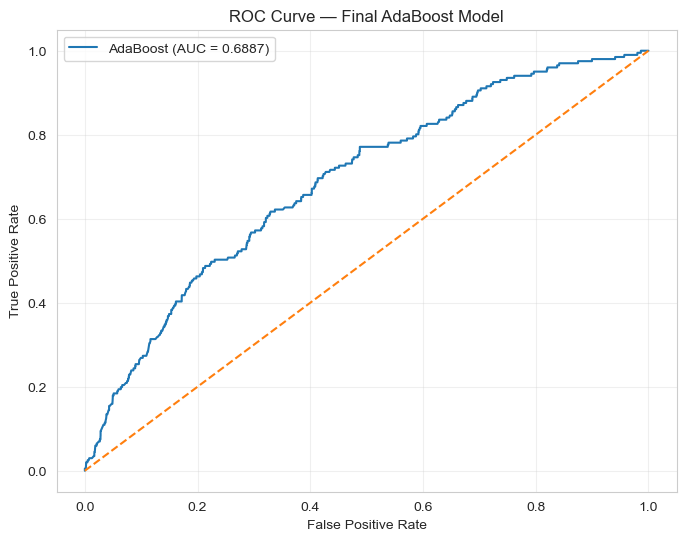

In [131]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, final_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"AdaBoost (AUC = {final_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Final AdaBoost Model")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Observation

The ROC curve for the final AdaBoost model remains above the random-classifier baseline across most classification thresholds.

The model achieved a ROC-AUC of 0.6887, indicating moderate discriminatory ability between good and bad customers. This confirms that the predicted probabilities contain useful risk-ranking information even though the default 0.5 threshold resulted in no bad-customer predictions.

The ROC analysis therefore supports the use of probability-based ranking and threshold analysis rather than relying solely on the default classification threshold.

## Probability Threshold Analysis

The default classification threshold of 0.5 resulted in no customers being classified as bad.

To understand the model's behavior under different operating thresholds, several probability thresholds are evaluated. The analysis compares Precision, Recall, F1-score, and the number of customers classified as bad.

Lowering the threshold generally increases the number of customers identified as potentially bad, allowing the business to examine the trade-off between identifying more risky customers and generating additional false positives.

In [132]:
thresholds_to_check = [0.50, 0.40, 0.30, 0.25, 0.20, 0.15, 0.10, 0.05]

threshold_results = []

for threshold in thresholds_to_check:
    predictions = (final_prob >= threshold).astype(int)
    
    threshold_results.append({
        "Threshold": threshold,
        "Predicted_Bad": predictions.sum(),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-Score": f1_score(y_test, predictions, zero_division=0)
    })

threshold_results = pd.DataFrame(threshold_results)

threshold_results.round(4)

,Threshold,Predicted_Bad,Precision,Recall,F1-Score
0,0.50,0,0.0000,0.0000,0.0000
1,0.40,0,0.0000,0.0000,0.0000
2,0.30,1,1.0000,0.0050,0.0099
3,0.25,752,0.0984,0.3682,0.1553
4,0.20,3594,0.0520,0.9303,0.0986
5,0.15,4776,0.0421,1.0000,0.0808
6,0.10,4780,0.0421,1.0000,0.0807
7,0.05,4780,0.0421,1.0000,0.0807


### Observation

The threshold analysis demonstrates a clear trade-off between identifying bad customers and limiting false-positive classifications.

At the default threshold of 0.50, no customers were classified as bad. Reducing the threshold to 0.25 resulted in 752 customers being flagged as bad, with a Recall of 36.82% and Precision of 9.84%.

Further reducing the threshold to 0.20 increased Recall substantially to 93.03%, but Precision declined to 5.20% because a much larger number of customers were classified as potentially bad.

These results demonstrate that the default 0.50 threshold is not suitable for this imbalanced credit-risk problem. The threshold should ultimately be selected according to business objectives and the acceptable trade-off between risk capture and false-positive cases.

## Decile Analysis and Risk Rank Ordering

The final AdaBoost model produces a probability score representing the estimated likelihood of a customer being classified as bad.

Customers are ranked according to these predicted probabilities and divided into ten approximately equal-sized deciles. Decile 10 represents customers with the highest predicted risk, while Decile 1 represents customers with the lowest predicted risk.

The actual bad-customer rate is calculated for each decile to assess whether the model successfully concentrates higher-risk customers toward the top of the ranking.

In [133]:
decile_data = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted_Probability": final_prob
})

decile_data["Decile"] = pd.qcut(
    decile_data["Predicted_Probability"],
    q=10,
    labels=False,
    duplicates="drop"
) + 1

decile_results = (
    decile_data
    .groupby("Decile")
    .agg(
        Customers=("Actual", "size"),
        Bad_Customers=("Actual", "sum"),
        Bad_Rate=("Actual", "mean"),
        Avg_Predicted_Risk=("Predicted_Probability", "mean")
    )
    .sort_index(ascending=False)
)

decile_results["Bad_Rate"] = decile_results["Bad_Rate"] * 100

decile_results.round(4)

,Customers,Bad_Customers,Bad_Rate,Avg_Predicted_Risk
Decile,,,,
10,478,51,10.6695,0.2673
9,478,39,8.1590,0.2508
8,476,20,4.2017,0.2401
7,475,22,4.6316,0.2310
6,483,23,4.7619,0.2234
5,477,6,1.2579,0.2163
4,479,18,3.7578,0.2082
3,477,11,2.3061,0.2002
2,477,6,1.2579,0.1899


### Observation

The decile analysis demonstrates meaningful risk-ranking capability for the final AdaBoost model.

The highest-risk decile (Decile 10) recorded an actual bad-customer rate of 10.67%, while the lowest-risk decile (Decile 1) recorded a bad rate of only 1.04%.

This represents approximately a 10-fold difference in observed bad rates between the highest- and lowest-risk groups. Although the bad rate is not perfectly monotonic across all intermediate deciles, the overall ranking shows clear separation between higher- and lower-risk customers.

The results indicate that the model's predicted probabilities provide useful information for customer risk segmentation, even though the default 0.5 classification threshold does not produce positive classifications.

## Decile Bad-Rate Visualization

The actual bad-customer rate for each risk decile is visualized to assess the overall rank-ordering pattern.

A higher bad rate in the highest-risk deciles and a lower bad rate in the lowest-risk deciles indicates effective customer risk segmentation.

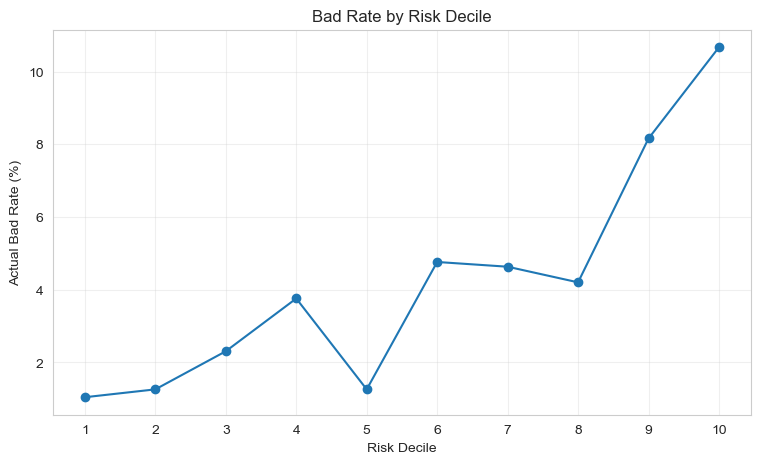

In [134]:
plt.figure(figsize=(9, 5))

plt.plot(
    decile_results.index,
    decile_results["Bad_Rate"],
    marker="o"
)

plt.xlabel("Risk Decile")
plt.ylabel("Actual Bad Rate (%)")
plt.title("Bad Rate by Risk Decile")
plt.xticks(decile_results.index)
plt.grid(alpha=0.3)
plt.show()

### Observation

The bad-rate visualization shows that customers in the higher-risk deciles generally have higher observed bad-customer rates than those in the lower-risk deciles.

The highest-risk decile (Decile 10) records the highest bad rate at 10.67%, while the lowest-risk decile (Decile 1) records a substantially lower bad rate of 1.04%.

Although the intermediate deciles do not follow a perfectly monotonic pattern, the overall separation between the highest- and lowest-risk groups demonstrates that the AdaBoost model provides meaningful risk segmentation.

## Feature Importance Analysis

Feature importance is examined to identify the variables that contribute most to the final AdaBoost model's predictions.

The importance scores are mapped back to the feature names generated during preprocessing, allowing the most influential customer and account characteristics to be identified.

The top 20 features are presented to improve interpretability and support business-level understanding of the model.

In [135]:
feature_names = preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": final_ada_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
).head(20)

print(feature_importance.round(6))

                          Feature  Importance
1                  num__feature_7    0.594456
8832            cat__feature_60_Y    0.108659
17             num__cashlimit_sum    0.093858
14           num__creditlimit_sum    0.035379
29        num__open_account_count    0.029118
0                  num__feature_3    0.027061
3                 num__feature_52    0.017247
40    num__ph1_numeric_count_mean    0.014881
85             num__dt_opened_day    0.013670
12       num__cur_balance_amt_max    0.013110
175              cat__feature_14_    0.009467
1983       cat__feature_29_110053    0.008270
156           cat__feature_12_PM2    0.007399
11      num__cur_balance_amt_mean    0.007131
155           cat__feature_12_PM1    0.006679
20       num__rateofinterest_mean    0.005996
31      num__max_account_age_days    0.005395
5156      cat__feature_38_MANAGER    0.002225
7805       cat__feature_43_Indore    0.000000
7757            cat__feature_41_4    0.000000


## Top 20 Feature Importance Visualization

The top 20 features contributing to the final AdaBoost model are visualized to improve interpretability.

The analysis shows that `feature_7` is the most influential feature, followed by the encoded categorical feature `feature_60_Y` and several customer-level financial and account-related features.

Since the original dataset contains anonymized feature names, the business meaning of individual demographic features cannot be established without an accompanying data dictionary.

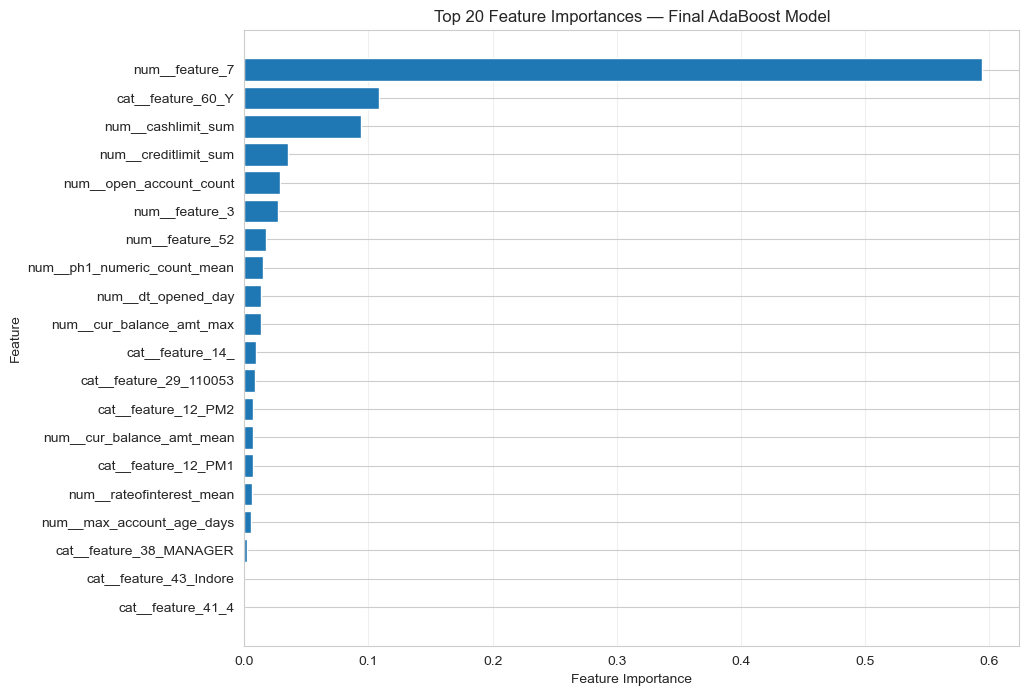

In [137]:
plt.figure(figsize=(10, 8))

plt.barh(
    feature_importance["Feature"].iloc[::-1],
    feature_importance["Importance"].iloc[::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 20 Feature Importances — Final AdaBoost Model")
plt.grid(axis="x", alpha=0.3)
plt.show()

### Observation

The feature-importance plot shows that `num__feature_7` is the most influential feature in the final AdaBoost model, followed by `cat__feature_60_Y`, `num__cashlimit_sum`, and `num__creditlimit_sum`.

Several customer-level account and financial features, including open account count, current balance, interest rate, and payment-history measures, also contribute to the model.

The high importance of `feature_7` indicates that it has a strong influence on the model's risk-ranking decisions. Since the original dataset uses anonymized feature names, its specific business meaning cannot be determined without a data dictionary.

Feature importance represents the model's usage of these variables and should not be interpreted as direct evidence of causation.

## Top Feature Validation and Leakage Check

The most influential features identified by the AdaBoost model are further examined to assess their relationship with the target variable.

Numerical features are evaluated across quantile-based groups, while categorical features are evaluated by category. This analysis helps identify unusually strong relationships or suspicious patterns that may require further investigation for potential data leakage.

A strong relationship alone does not establish leakage; the business meaning and availability of a feature would also need to be considered.

In [140]:
validation_data = final_customer_data[
    ["Bad_label", "feature_7", "feature_60", "cashlimit_sum", "creditlimit_sum"]
].copy()

validation_data["Bad_label"] = pd.to_numeric(
    validation_data["Bad_label"], errors="coerce"
)

validation_data["feature_7"] = pd.to_numeric(
    validation_data["feature_7"], errors="coerce"
)

validation_data["cashlimit_sum"] = pd.to_numeric(
    validation_data["cashlimit_sum"], errors="coerce"
)

validation_data["creditlimit_sum"] = pd.to_numeric(
    validation_data["creditlimit_sum"], errors="coerce"
)

validation_data["feature_7_group"] = pd.qcut(
    validation_data["feature_7"],
    q=5,
    duplicates="drop"
)

validation_data["cashlimit_group"] = pd.qcut(
    validation_data["cashlimit_sum"],
    q=5,
    duplicates="drop"
)

validation_data["creditlimit_group"] = pd.qcut(
    validation_data["creditlimit_sum"],
    q=5,
    duplicates="drop"
)

print("feature_7 bad rate by quantile:")
print(
    validation_data.groupby("feature_7_group", observed=True)["Bad_label"]
    .mean()
    .mul(100)
    .round(2)
)

print("\nfeature_60 bad rate by category:")
print(
    validation_data.groupby("feature_60", observed=True)["Bad_label"]
    .agg(["count", "mean"])
    .assign(Bad_Rate=lambda x: x["mean"] * 100)
    .drop(columns="mean")
    .sort_values("Bad_Rate", ascending=False)
)

print("\ncashlimit_sum bad rate by quantile:")
print(
    validation_data.groupby("cashlimit_group", observed=True)["Bad_label"]
    .mean()
    .mul(100)
    .round(2)
)

print("\ncreditlimit_sum bad rate by quantile:")
print(
    validation_data.groupby("creditlimit_group", observed=True)["Bad_label"]
    .mean()
    .mul(100)
    .round(2)
)

feature_7 bad rate by quantile:
feature_7_group
(-0.001, 66000.0]        6.82
(66000.0, 93000.0]       4.84
(93000.0, 117000.0]      3.98
(117000.0, 150000.0]     3.11
(150000.0, 1217000.0]    2.11
Name: Bad_label, dtype: float64

feature_60 bad rate by category:
            count  Bad_Rate
feature_60                 
               15  6.666667
N           23563  4.252430
Y             318  0.314465

cashlimit_sum bad rate by quantile:
cashlimit_group
(-0.001, 10400.0]       5.69
(10400.0, 23600.0]      3.96
(23600.0, 41750.0]      3.47
(41750.0, 1099000.0]    2.20
Name: Bad_label, dtype: float64

creditlimit_sum bad rate by quantile:
creditlimit_group
(-0.001, 21000.0]        6.16
(21000.0, 72500.0]       4.79
(72500.0, 121000.0]      4.59
(121000.0, 222000.0]     3.31
(222000.0, 8717506.0]    2.12
Name: Bad_label, dtype: float64


### Observation

The validation analysis confirms that the most influential numerical features have meaningful relationships with the target variable.

For `feature_7`, the observed bad rate decreases consistently from 6.82% in the lowest value group to 2.11% in the highest value group. Similar decreasing patterns are observed for `cashlimit_sum` and `creditlimit_sum`, supporting their predictive contribution to the model.

For `feature_60`, customers in category `Y` show a substantially lower observed bad rate than customers in category `N`. However, the `Y` category contains only 318 observations, so this relationship should be interpreted cautiously.

No obvious evidence of data leakage was identified from these distributional checks. However, definitive leakage assessment would require business-level knowledge of when and how each feature is generated. The validated features are therefore retained for the final model.

## Final Model Performance Comparison

The baseline ensemble models and the selected tuned AdaBoost model are compared using ROC-AUC and Gini as the primary credit-risk metrics, along with the standard classification metrics.

This comparison provides a consolidated view of model performance and supports the selection of the final modeling approach.

In [142]:
final_model_results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "AdaBoost Baseline",
        "Gradient Boosting",
        "AdaBoost Tuned"
    ],
    "Accuracy": [
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, ada_pred),
        accuracy_score(y_test, gb_pred),
        accuracy_score(y_test, final_pred)
    ],
    "Precision": [
        precision_score(y_test, rf_pred, zero_division=0),
        precision_score(y_test, ada_pred, zero_division=0),
        precision_score(y_test, gb_pred, zero_division=0),
        precision_score(y_test, final_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, rf_pred, zero_division=0),
        recall_score(y_test, ada_pred, zero_division=0),
        recall_score(y_test, gb_pred, zero_division=0),
        recall_score(y_test, final_pred, zero_division=0)
    ],
    "F1-Score": [
        f1_score(y_test, rf_pred, zero_division=0),
        f1_score(y_test, ada_pred, zero_division=0),
        f1_score(y_test, gb_pred, zero_division=0),
        f1_score(y_test, final_pred, zero_division=0)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, rf_prob),
        roc_auc_score(y_test, ada_prob),
        roc_auc_score(y_test, gb_prob),
        final_auc
    ]
})

final_model_results["Gini"] = (
    2 * final_model_results["ROC-AUC"] - 1
)

final_model_results.sort_values(
    "ROC-AUC", ascending=False
).reset_index(drop=True).round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Gini
0,AdaBoost Tuned,0.9579,0.0,0.0,0.0,0.6887,0.3775
1,AdaBoost Baseline,0.9579,0.0,0.0,0.0,0.6861,0.3722
2,Gradient Boosting,0.9577,0.0,0.0,0.0,0.6696,0.3393
3,Random Forest,0.9579,0.0,0.0,0.0,0.6354,0.2709


### Observation

The final model comparison shows that the tuned AdaBoost model achieved the highest ROC-AUC of 0.6887 and Gini coefficient of 0.3775 among all evaluated models.

The tuned AdaBoost model provides a modest improvement over the baseline AdaBoost model, increasing ROC-AUC from 0.6861 to 0.6887 and Gini from 0.3722 to 0.3775.

Gradient Boosting and Random Forest produced lower ROC-AUC and Gini values. Although all models achieved approximately 95.8% Accuracy with zero Recall and F1-score at the default threshold, these metrics are affected by the highly imbalanced target distribution.

Based on ROC-AUC, Gini, and the subsequent decile analysis, the tuned AdaBoost model is selected as the final model for customer risk ranking.

# Challenges, Techniques, and Reasoning

### 1. Class Imbalance

The target variable was highly imbalanced, with approximately 95.8% good customers and 4.2% bad customers.

**Technique:** Stratified train-test splitting was used to preserve the target distribution in both datasets. Model evaluation emphasized ROC-AUC and Gini rather than relying only on Accuracy.

**Reasoning:** A model predicting most customers as good can achieve high Accuracy while failing to identify bad customers. ROC-AUC and Gini provide a more informative assessment of risk discrimination and ranking.

### 2. Customer-Level Data Integration

The account table contained multiple records for individual customers, while the demographic table was at customer level.

**Technique:** Account-level information was aggregated to customer level using account counts, financial aggregates, account-status information, date-based features, and payment-history statistics.

**Reasoning:** The modeling objective is customer-level credit-risk prediction, so multiple account records needed to be consolidated into one customer-level observation.

### 3. Missing Account Information

Several account-level variables contained substantial missing values, including interest rate, credit limit, cash limit, actual payment amount, and payment history.

**Technique:** Missingness indicators were created for important account-level groups, while numerical values were later handled through median imputation within the preprocessing pipeline.

**Reasoning:** Missingness itself showed differences in observed bad rates and therefore could contain useful information. Missingness indicators preserve this signal rather than treating all missing values as completely random.

### 4. Payment History Processing

Payment history was stored as strings containing three-character payment-status blocks, including numeric values and status codes such as `STD`, `SUB`, `DBT`, `LSS`, and `SMA`.

**Technique:** Payment-history strings were converted into customer-level statistical features such as history length, numeric count, adverse-status count, and corresponding proportions.

**Reasoning:** The original payment-history strings are not directly suitable as conventional numerical model inputs. Aggregating their characteristics converts the historical information into structured predictive features.

### 5. High-Cardinality and Identifier-Like Variables

Several variables had very high cardinality and included identifier-like information such as masked PAN-like values, phone-like values, and email-related fields.

**Technique:** Identifier-like features were excluded from modeling, while legitimate categorical variables were retained for encoding.

**Reasoning:** Identifier fields generally do not provide reliable generalizable credit-risk information and can create excessive dimensionality or memorization. Removing them also reduced the one-hot encoded feature space substantially.

### 6. Date and Malformed Date Features

Several date-like fields contained different formats, including valid dates, partial dates, and malformed placeholder values.

**Technique:** Reliable date fields were decomposed into year, month, and day components. `feature_63` was reduced to its year component, while the highly inconsistent `feature_70` was removed.

**Reasoning:** Reliable temporal information can be useful for modeling, but incorrectly interpreting malformed dates could introduce artificial patterns and misleading information.

### 7. Sparse One-Hot Encoding

After preprocessing, the dataset contained 11,625 model-ready features, with the training matrix represented as a sparse CSR matrix and approximately 98.91% sparsity.

**Technique:** One-hot encoding with `handle_unknown="ignore"` was used for categorical variables.

**Reasoning:** Sparse representation is appropriate for one-hot encoded data because most observations contain zeros across the expanded categorical feature space.

### 8. Ensemble Model Benchmarking

Random Forest, AdaBoost, and Gradient Boosting were benchmarked before selecting the final model.

**Technique:** Models were compared using Accuracy, Precision, Recall, F1-score, ROC-AUC, and Gini coefficient.

**Reasoning:** Comparing multiple ensemble approaches provides evidence-based model selection rather than assuming that one algorithm will perform best.

### 9. Model Selection and Optimization

AdaBoost achieved the highest baseline ROC-AUC and Gini coefficient.

**Technique:** A lightweight parameter search was performed using different combinations of `n_estimators` and `learning_rate`.

**Reasoning:** The objective was to determine whether a small number of reasonable parameter changes could improve risk-ranking performance without excessive computational cost.

The selected configuration used 250 estimators and a learning rate of 0.25.

### 10. Threshold Consideration

The default probability threshold of 0.50 resulted in no positive classifications.

**Technique:** Multiple probability thresholds were examined to understand the Precision-Recall trade-off.

**Reasoning:** In an imbalanced credit-risk problem, the default threshold may not be appropriate for business use. The final operating threshold should depend on the business's tolerance for missed bad customers versus false-positive risk flags.

### 11. Risk Ranking and Decile Analysis

The model's predicted probabilities were used to rank customers into ten risk deciles.

**Technique:** Actual bad rates were calculated within each decile.

**Reasoning:** Credit-risk models are often valuable for ranking customers by relative risk, not only for producing a binary classification. Decile analysis therefore provides a practical assessment of whether higher predicted risk corresponds to higher observed bad rates.

# Final Business Conclusion

The Bank GoodCredit customer-level credit-risk model was developed by integrating customer demographic information with aggregated account, financial, account-status, date, and payment-history information.

The target variable was highly imbalanced, with approximately 95.8% good customers and 4.2% bad customers. Therefore, ROC-AUC and Gini were emphasized alongside the traditional classification metrics.

Among the benchmarked ensemble models, the tuned AdaBoost model achieved the highest ROC-AUC of 0.6887 and a Gini coefficient of 0.3775. The model showed moderate discriminatory ability and meaningful customer risk-ranking capability.

The decile analysis provided an important business insight. Customers in the highest-risk decile had an observed bad rate of 10.67%, compared with only 1.04% in the lowest-risk decile. This approximately ten-fold difference demonstrates that the model can separate relatively higher-risk customers from lower-risk customers.

However, the default 0.50 classification threshold resulted in no customers being classified as bad. Threshold analysis showed that lowering the threshold substantially increased bad-customer recall, but also increased the number of good customers incorrectly flagged as potentially bad. Therefore, the default threshold should not be adopted automatically.

For practical deployment, Bank GoodCredit should use the model primarily as a risk-ranking and customer-segmentation tool and select an operating threshold based on business costs, risk appetite, and the acceptable balance between missed bad customers and false-positive cases.

The model should be further validated on an independent or future-period dataset before production deployment. In particular, feature availability at the time of credit decision, model stability, probability calibration, and business-defined threshold selection should be assessed.

Overall, the tuned AdaBoost model provides a useful foundation for customer credit-risk ranking, with the strongest value demonstrated through its ability to concentrate higher-risk customers toward the top of the risk distribution.

In [147]:
feature29_check = final_customer_data[
    ["Bad_label", "feature_29"]
].copy()

feature29_check["Bad_label"] = pd.to_numeric(
    feature29_check["Bad_label"], errors="coerce"
)

feature29_check["feature_29"] = (
    feature29_check["feature_29"]
    .astype(str)
    .str.strip()
)

print("feature_29 unique values:", feature29_check["feature_29"].nunique())

print("\nTop feature_29 values:")
print(
    feature29_check["feature_29"]
    .value_counts()
    .head(15)
)

print("\nfeature_29 bad rate:")
feature29_bad_rate = (
    feature29_check
    .groupby("feature_29", observed=True)["Bad_label"]
    .agg(["count", "mean"])
    .rename(columns={"mean": "Bad_Rate"})
)

feature29_bad_rate["Bad_Rate"] = (
    feature29_bad_rate["Bad_Rate"] * 100
)

print(
    feature29_bad_rate
    .sort_values("count", ascending=False)
    .head(15)
)

feature_29 unique values: 965

Top feature_29 values:
feature_29
110059    1097
122001     975
110092     685
201301     625
110085     520
110062     465
121001     403
110018     401
110044     375
110045     366
110053     352
201001     335
201010     307
110096     306
110094     287
Name: count, dtype: int64

feature_29 bad rate:
            count  Bad_Rate
feature_29                 
110059       1097  4.649043
122001        975  4.000000
110092        685  4.379562
201301        625  6.080000
110085        520  5.384615
110062        465  3.440860
121001        403  5.459057
110018        401  4.239401
110044        375  5.066667
110045        366  4.644809
110053        352  1.420455
201001        335  3.880597
201010        307  4.885993
110096        306  4.901961
110094        287  5.574913


### Observation

The validation of `feature_29` shows that its values are repeated across multiple customers rather than functioning as unique customer identifiers.

The observed bad rates vary across the frequently occurring categories, indicating that the feature contains some predictive information. One-hot encoded representations of `feature_29` were therefore retained in the model.

No obvious evidence of target leakage was identified from this validation. However, the exact business meaning of the codes cannot be confirmed because the dataset does not provide a feature data dictionary.